# SparseComm: saved-results audit and publication readiness

**STOPPED snapshot; no model inference.** E1–E4 complete300 each; E5 partial129/300. The verdict is **not ready for a strong WWW2027 submission as currently framed**. No missing result was filled.

Read the full report for statistical scope, leak/overlap checks and publication blockers. All plotting uses authentic saved outputs. This notebook defaults to reading derived artifacts; it does not train, test or call Azure.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT=Path('/home/saurab/Documents/projectRLMAIN/WEBExtension')
REVIEW=ROOT/'analysis/publication_review_20261014'
AUDIT=json.loads((REVIEW/'audit_metrics.json').read_text())
assert AUDIT['no_inference_requested']
display(Markdown('**Verdict:** '+AUDIT['verdict']))
display(pd.DataFrame(AUDIT['integrity']).T)

**Verdict:** NOT_READY_FOR_A_STRONG_WWW2027_SUBMISSION

,n,target,unique_ids,ids_within_frozen_test,status,sha256,complete_sha_matches_status
E1,300,300,300,True,COMPLETE,1afe9ce6293a85acdcc743ee18b81c9ae79d57cd825869...,True
E2,300,300,300,True,COMPLETE,dfae111876fc8fbcc3aaadd7ddff050909b3e76f0bb2e9...,True
E3,300,300,300,True,COMPLETE,793f10a77da7556cec6adec23e0bcbdd8e99cf5361ca97...,True
E4,300,300,300,True,COMPLETE,10ec23783228e25ab1002d0aeb241e7dd5f30f0b6e8a67...,True
E5,129,300,129,True,INCOMPLETE,e783049d60ba5b38cbbc658ae6b273dc7e51d8a6c50b0a...,None


## Complete experiments and statistical effects

E1 primary interaction includes zero. Secondary and stratum findings are distinct from primary inference; do not replace the primary endpoint after inspection.

In [2]:
summary=pd.read_csv(REVIEW/'tables/condition_summary.csv')
display(summary[summary.experiment!='E5'][['experiment','condition','n','F1','F1_CI_low','F1_CI_high','EM','payload_tokens_known_mean','logical_calls_known_mean']])
display(pd.DataFrame(AUDIT['complete_effects']))

,experiment,condition,n,F1,F1_CI_low,F1_CI_high,EM,payload_tokens_known_mean,logical_calls_known_mean
0,E1,P_CCW,300,9.040009,6.171397,12.089730,6.333333,66.800000,6.00
1,E1,P_CW,300,9.132973,6.246647,12.283052,6.666667,66.800000,6.00
2,E1,P_NoComm,300,5.266709,2.999965,7.735159,3.666667,0.000000,3.00
3,E1,P_SelfUpdate,300,5.755598,3.454103,8.250356,3.666667,0.000000,6.00
4,E1,R_CCW,300,32.839021,28.015025,37.725476,24.000000,145.163333,6.00
5,E1,R_CW,300,32.732497,27.964957,37.544710,24.333333,145.163333,6.00
6,E1,R_NoComm,300,31.747740,26.996901,36.605409,22.666667,0.000000,3.00
7,E1,R_SelfUpdate,300,32.088925,27.320465,36.982090,23.666667,0.000000,6.00
8,E2,R_CCW,300,32.839021,28.015025,37.725476,24.000000,145.163333,6.00
9,E2,R_CW,300,32.732497,27.964957,37.544710,24.333333,145.163333,6.00


,experiment,contrast,primary,n,effect,ci95,randomization_p,helped,harmed,unchanged,holm_p_within_experiment,holm_across_completed_secondary_contrasts
0,E1,(CW-NoComm)_P - (CW-NoComm)_R,True,300,2.881507,"[-0.25996063576945927, 6.010893847437964]",0.071293,25,16,259,NaN,NaN
1,E1,R_CW - R_NoComm,False,300,0.984757,"[-0.7680588093823387, 2.893296595379929]",0.295470,14,6,280,0.857914,1.000000
2,E1,P_CW - P_NoComm,False,300,3.866263,"[1.356056786350904, 6.485954184704185]",0.001500,20,5,275,0.008999,0.013499
3,E1,R_CCW - R_NoComm,False,300,1.091281,"[-0.8013360790444124, 3.144086659074404]",0.285971,14,10,276,0.857914,1.000000
4,E1,P_CCW - P_NoComm,False,300,3.773300,"[1.4206812876665817, 6.354451447245564]",0.002400,20,4,276,0.011999,0.019198
5,E1,R_CW - R_SelfUpdate,False,300,0.643572,"[-0.870582611832612, 2.2149882209988596]",0.420958,13,6,281,0.857914,1.000000
6,E1,P_CW - P_SelfUpdate,False,300,3.377375,"[0.8490954715219422, 6.052734487734487]",0.010999,18,7,275,0.043996,0.076992
7,E2,R_CW - R_CCW,False,300,-0.106524,"[-1.4761482730232731, 1.147305934805935]",0.880112,10,6,284,0.880112,1.000000
8,E3,R_prefix - R_crop,False,300,0.145022,"[-0.13636363636363635, 0.5714285714285714]",1.000000,1,1,298,1.000000,1.000000
9,E4,P_stopped - P_final,False,300,0.000000,"[0.0, 0.0]",1.000000,0,0,300,1.000000,1.000000


## No accidental train/test overlap

Zero exact IDs, normalized questions and NFKC/casefold candidate-title overlap across train/validation/heldout/pilot. This is not a guarantee against semantic aliases or pretraining contamination. Shared test IDs across experimental arms/optimizer seeds are intentional paired measurements.

In [3]:
display(pd.DataFrame(AUDIT['leakage']['pairwise_checks']).T)
display(pd.read_csv(REVIEW/'tables/intentional_experiment_question_overlap.csv'))
display(pd.DataFrame(AUDIT['retrieval_availability']))

,id_overlap,normalized_question_overlap,candidate_title_overlap
train__validation,0,0,0
train__heldout,0,0,0
train__pilot,0,0,0
validation__heldout,0,0,0
validation__pilot,0,0,0
heldout__pilot,0,0,0


,left,right,shared_question_ids,interpretation
0,E1,E2,300,Intentional same-question pairing; not indepen...
1,E1,E3,300,Intentional same-question pairing; not indepen...
2,E1,E4,300,Intentional same-question pairing; not indepen...
3,E1,E5,129,Intentional same-question pairing; not indepen...
4,E2,E3,300,Intentional same-question pairing; not indepen...
5,E2,E4,300,Intentional same-question pairing; not indepen...
6,E2,E5,129,Intentional same-question pairing; not indepen...
7,E3,E4,300,Intentional same-question pairing; not indepen...
8,E3,E5,129,Intentional same-question pairing; not indepen...
9,E4,E5,129,Intentional same-question pairing; not indepen...


,candidate_gold_count,top6_gold_count
0,55,60
2,79,76
1,166,164


## All recorded scalar metrics and their distributions

Known-subset token means are labeled explicitly; missing counts remain NA. Supporting/joint-label diagnostics are not entailment verification. Choose a metric to inspect its distribution without calling a model.

In [4]:
all_metrics=pd.read_csv(REVIEW/'tables/all_condition_question_metrics.csv')
profiles=pd.read_csv(REVIEW/'tables/all_metric_distribution_profiles.csv')
METRIC='answer_support_recall'
display(profiles[profiles.metric==METRIC])
display(pd.DataFrame.from_dict(AUDIT['metric_definitions'],orient='index',columns=['Definition']))

,experiment,condition,metric,n,known_n,missing_n,mean_known,std_known,min_known,p05_known,median_known,p95_known,max_known
2,E1,P_CCW,answer_support_recall,300,300,0,0.069389,0.202642,0.0,0.0,0.00,0.5,1.0
27,E1,P_CW,answer_support_recall,300,300,0,0.059944,0.181016,0.0,0.0,0.00,0.5,1.0
52,E1,P_NoComm,answer_support_recall,300,300,0,0.039167,0.152911,0.0,0.0,0.00,0.5,1.0
77,E1,P_SelfUpdate,answer_support_recall,300,300,0,0.037500,0.151194,0.0,0.0,0.00,0.5,1.0
102,E1,R_CCW,answer_support_recall,300,300,0,0.268667,0.337474,0.0,0.0,0.00,1.0,1.0
127,E1,R_CW,answer_support_recall,300,300,0,0.268000,0.341668,0.0,0.0,0.00,1.0,1.0
152,E1,R_NoComm,answer_support_recall,300,300,0,0.254944,0.327931,0.0,0.0,0.00,1.0,1.0
177,E1,R_SelfUpdate,answer_support_recall,300,300,0,0.259389,0.335328,0.0,0.0,0.00,1.0,1.0
202,E2,R_CCW,answer_support_recall,300,300,0,0.268667,0.337474,0.0,0.0,0.00,1.0,1.0
227,E2,R_CW,answer_support_recall,300,300,0,0.268000,0.341668,0.0,0.0,0.00,1.0,1.0


,Definition
f1,"Official HotpotQA normalized answer token F1, ..."
em,"Official normalized answer exact match, multip..."
support_available_recall,"Fraction of gold supporting (title,sentence in..."
all_support_available,All gold supporting labels available somewhere...
split_support_across_nodes,Gold supporting labels available in pool but n...
answer_support_recall_precision,Gold supporting-label agreement for citations ...
support_label_f1_em,Additional official-style support-set overlap ...
label_joint_f1_em,Official joint-metric algebra applied to ensem...
new_support_facts_delivered,Gold support labels newly delivered to recipie...
payload_tokens,Actual pinned-tokenizer count summed over deli...


## Controller training and incomplete held-out trend

E5 is only129/300. Seeds are averaged within each question for the paired analysis; n is129, not387. Do not tune checkpoints based on this partial test or call the test complete.

In [5]:
display(pd.read_csv(REVIEW/'tables/controller_learning_curves.csv'))
display(pd.DataFrame(AUDIT['partial_E5_effects']))
display(pd.read_csv(REVIEW/'tables/E5_partial_quality_resource_tradeoffs.csv'))
display(pd.read_csv(REVIEW/'tables/E5_partial_action_adaptivity.csv'))
display(pd.read_csv(REVIEW/'tables/E5_partial_missing_data_bounds.csv'))

,seed,epoch,mean_utility_gain,mean_f1,n_contexts,optimizer_loss,optimizer_updates,optimizer_early_kl_stop,optimizer_max_kl,train_mean_reward,train_mean_f1,train_rollouts,selected_epoch,train_action_entropy_bits
0,7,1,0.022807,39.891771,60,-0.025601,28,False,0.000292,-0.031934,45.943619,200,1,5.554739
1,7,2,-0.021408,33.367657,60,-0.040512,28,False,0.000257,-0.014694,47.537998,200,1,5.595551
2,7,3,-0.004136,35.371674,60,-0.044279,28,False,0.001145,0.006885,49.734217,200,1,5.548689
3,19,1,-0.011901,34.682540,60,-0.035685,28,False,0.000268,-0.010179,48.268035,200,3,5.553159
4,19,2,-0.034397,32.334530,60,-0.016499,28,False,0.000245,-0.009525,48.234217,200,3,5.493330
5,19,3,0.027468,38.011768,60,-0.034015,28,False,0.000524,0.008505,49.896121,200,3,5.534017
6,31,1,-0.004798,34.571429,60,-0.039224,28,False,0.000239,-0.024396,46.567550,200,3,5.603577
7,31,2,0.030153,37.874459,60,-0.023465,28,False,0.000394,-0.014941,47.617970,200,3,5.623867
8,31,3,0.035072,37.874459,60,-0.034304,28,False,0.000780,-0.016005,47.470351,200,3,5.542904


,experiment,contrast,scope,n,effect,ci95,randomization_p,helped,harmed,unchanged,holm_exploratory_partial_family
0,E5,R_seed_mean_Learned - NoComm,PARTIAL_PREFIX_EXPLORATORY_NOT_FINAL,129,-0.543437,"[-2.6311468462631242, 1.4702160218216076]",0.636273,8,6,115,1.000000
1,E5,R_seed_mean_Learned - SelfUpdate,PARTIAL_PREFIX_EXPLORATORY_NOT_FINAL,129,0.281087,"[-2.116726801783321, 2.7032504952081573]",0.822835,9,6,114,1.000000
2,E5,R_seed_mean_Learned - Static,PARTIAL_PREFIX_EXPLORATORY_NOT_FINAL,129,0.322196,"[-2.0851776342632413, 2.859603789836348]",0.789242,8,7,114,1.000000
3,E5,R_seed_mean_Learned - Broadcast,PARTIAL_PREFIX_EXPLORATORY_NOT_FINAL,129,0.220463,"[-1.6987874313455706, 2.1476562603083553]",0.818236,8,6,115,1.000000
4,E5,R_seed_mean_Learned - MatchedRandom,PARTIAL_PREFIX_EXPLORATORY_NOT_FINAL,129,0.005064,"[-1.2427710102128708, 1.255405240025534]",1.000000,7,4,118,1.000000
5,E5,P_seed_mean_Learned - NoComm,PARTIAL_PREFIX_EXPLORATORY_NOT_FINAL,129,7.835554,"[4.439221953756837, 11.75521130462991]",0.000200,22,1,106,0.002000
6,E5,P_seed_mean_Learned - SelfUpdate,PARTIAL_PREFIX_EXPLORATORY_NOT_FINAL,129,6.469736,"[2.1593705605333513, 10.798663545756567]",0.002999,22,4,103,0.020996
7,E5,P_seed_mean_Learned - Static,PARTIAL_PREFIX_EXPLORATORY_NOT_FINAL,129,6.478965,"[2.706690381108986, 10.213989283756726]",0.000600,21,1,107,0.004799
8,E5,P_seed_mean_Learned - Broadcast,PARTIAL_PREFIX_EXPLORATORY_NOT_FINAL,129,-5.335190,"[-8.337192523239034, -2.560334798706894]",0.000200,1,17,111,0.002000
9,E5,P_seed_mean_Learned - MatchedRandom,PARTIAL_PREFIX_EXPLORATORY_NOT_FINAL,129,2.183239,"[0.828047921071177, 3.9182942380616788]",0.003999,9,1,119,0.023995


,regime,baseline,n,learned_seed_mean_F1,baseline_F1,F1_change,learned_mean_payload_tokens,baseline_payload_tokens,payload_reduction_percent,learned_mean_logical_calls,baseline_calls,call_reduction_percent,scope
0,R,NoComm,129,34.274004,34.817441,-0.543437,66.891473,0.000000,NaN,3.987080,3.0,-32.902670,PARTIAL_PREFIX_ONLY
1,R,SelfUpdate,129,34.274004,33.992916,0.281087,66.891473,0.000000,NaN,3.987080,6.0,33.548665,PARTIAL_PREFIX_ONLY
2,R,Static,129,34.274004,33.951808,0.322196,66.891473,102.945736,35.022590,3.987080,5.0,20.258398,PARTIAL_PREFIX_ONLY
3,R,Broadcast,129,34.274004,34.053540,0.220463,66.891473,326.837209,79.533703,3.987080,6.0,33.548665,PARTIAL_PREFIX_ONLY
4,P,NoComm,129,12.401814,4.566261,7.835554,79.015504,0.000000,NaN,4.661499,3.0,-55.383290,PARTIAL_PREFIX_ONLY
5,P,SelfUpdate,129,12.401814,5.932078,6.469736,79.015504,0.000000,NaN,4.661499,6.0,22.308355,PARTIAL_PREFIX_ONLY
6,P,Static,129,12.401814,5.922850,6.478965,79.015504,49.937984,-58.227259,4.661499,5.0,6.770026,PARTIAL_PREFIX_ONLY
7,P,Broadcast,129,12.401814,17.737005,-5.335190,79.015504,147.534884,46.442833,4.661499,6.0,22.308355,PARTIAL_PREFIX_ONLY


,regime,seed,n,unique_actions,top_action,top_action_fraction,NoComm_fraction,entropy_bits,frequencies
0,R,7,129,3,45,0.589147,0.00000,1.105877,"{45: 76, 40: 3, 31: 50}"
1,R,19,129,3,32,0.542636,0.00000,1.409386,"{14: 40, 32: 70, 7: 19}"
2,R,31,129,2,0,0.798450,0.79845,0.725018,"{0: 103, 14: 26}"
3,P,7,129,2,54,0.984496,0.00000,0.115390,"{54: 127, 2: 2}"
4,P,19,129,3,32,0.635659,0.00000,1.071001,"{14: 44, 32: 82, 21: 3}"
5,P,31,129,1,14,1.000000,0.00000,-0.000000,{14: 129}


,condition,observed_n,missing_n,observed_mean_F1,full300_worst_case_bound,full300_best_case_bound
0,P_Broadcast,129,171,17.737005,7.626912,64.626912
1,P_Learned_seed19,129,171,11.053894,4.753175,61.753175
2,P_Learned_seed31,129,171,8.414544,3.618254,60.618254
3,P_Learned_seed7,129,171,17.737005,7.626912,64.626912
4,P_MatchedRandom_seed19,129,171,7.281956,3.131241,60.131241
5,P_MatchedRandom_seed31,129,171,5.636766,2.423810,59.423810
6,P_MatchedRandom_seed7,129,171,17.737005,7.626912,64.626912
7,P_NoComm,129,171,4.566261,1.963492,58.963492
8,P_SelfUpdate,129,171,5.932078,2.550794,59.550794
9,P_Static,129,171,5.922850,2.546825,59.546825


## Physical usage, wall time and unknown liabilities

Input/output totals are counted independently. Known lower bounds are not a complete bill. All physical attempt IDs are deduplicated across preserved ledger copies; archived caps/pilots have separate scope from current protocol logical costs. Nested timers overlap.

In [6]:
display(pd.DataFrame(AUDIT['physical_usage_active']))
display(pd.Series(AUDIT['physical_usage_global']))
display(pd.read_csv(REVIEW/'tables/network_latency_summary.csv'))
display(pd.read_csv(REVIEW/'tables/worker_session_timings.csv'))

,pipeline,successes,reported_input_tokens,successful_inputs_missing,reported_output_tokens_lower_bound,successful_outputs_missing,original_unresolved_attempts,attempts
0,controlled,6134,5960203,0,1582163,29,8,6153
1,controller,5725,5748101,0,1511822,27,4,5736


scope                                 All original attempt IDs in WEBExtension/artif...
unique_attempts                                                                   13666
outcomes                              {'success': 13632, 'rejected': 21, 'uncertain'...
reported_input_tokens_lower_bound                                              13333177
reported_output_tokens_lower_bound                                              3535121
attempts_missing_input_usage                                                         34
attempts_missing_output_usage                                                        91
refusals                                                                            101
monetary_cost                                                                      None
reason                                No verified deployment price; missing/refusal/...
dtype: object

,pipeline,http_status,n,mean_network_seconds,median_network_seconds,p95_network_seconds,p99_network_seconds,scope
0,controlled,200.0,5190,1.214204,1.038298,2.265434,3.178432,Captured raw transport attempts only; provider...
1,controlled,400.0,61,1.052339,0.906329,1.846684,2.656248,Captured raw transport attempts only; provider...
2,controlled,429.0,10,0.170654,0.147195,0.277370,0.313057,Captured raw transport attempts only; provider...
3,controlled,500.0,2,17.087021,17.087021,18.256807,18.360788,Captured raw transport attempts only; provider...
4,controlled,NaN,5,99.402227,121.305674,121.388887,121.400725,Captured raw transport attempts only; provider...
5,controller,200.0,5689,1.193385,1.028962,2.153111,3.120368,Captured raw transport attempts only; provider...
6,controller,400.0,36,0.972103,0.925947,1.300107,1.743345,Captured raw transport attempts only; provider...
7,controller,429.0,7,0.194998,0.196007,0.259563,0.268920,Captured raw transport attempts only; provider...
8,controller,NaN,4,90.384597,120.083049,121.146581,121.292580,Captured raw transport attempts only; provider...


,pipeline,session,start_utc,end_utc,status,wall_seconds_observed
0,run_f6aa61bac2c3dfae,20261014T053903.462338+0000_8facdd98,2026-10-14T05:39:03.463764+00:00,2026-10-14T06:11:50.063951+00:00,FAILED,1966.600344
1,run_f6aa61bac2c3dfae,20261014T070525.518460+0000_f47b4d6b,2026-10-14T07:05:25.519166+00:00,2026-10-14T07:05:44.509884+00:00,FAILED,18.990794
2,run_f6aa61bac2c3dfae,20261014T070818.416120+0000_a357bbc3,2026-10-14T07:08:18.417347+00:00,2026-10-14T07:45:56.551488+00:00,STOPPED,2258.134231
3,run_f6aa61bac2c3dfae,20261014T085630.507062+0000_d2e93b65,2026-10-14T08:56:30.507662+00:00,2026-10-14T09:09:04.980721+00:00,FAILED,754.473118
4,run_f6aa61bac2c3dfae,20261014T091213.356757+0000_93ad24bf,2026-10-14T09:12:13.357300+00:00,2026-10-14T09:28:42.071016+00:00,FAILED,988.713850
5,run_f6aa61bac2c3dfae,20261014T102313.656448+0000_fa737840,2026-10-14T10:23:13.656802+00:00,2026-10-14T10:37:42.993482+00:00,STOPPED,869.336728
6,run_f6aa61bac2c3dfae,20261014T110033.032359+0000_79069b5f,2026-10-14T11:00:33.032930+00:00,2026-10-14T11:49:10.482501+00:00,FAILED,2917.449742
7,run_f6aa61bac2c3dfae,20261014T121348.993806+0000_8ca8c734,2026-10-14T12:13:48.994481+00:00,2026-10-14T12:59:03.943359+00:00,FAILED,2714.948994
8,run_f6aa61bac2c3dfae,20261014T130523.356180+0000_988e5ce4,2026-10-14T13:05:23.356738+00:00,2026-10-14T13:19:46.245010+00:00,FAILED,862.888349
9,run_f6aa61bac2c3dfae,20261014T132135.514964+0000_951b35ea,2026-10-14T13:21:35.515660+00:00,2026-10-14T13:24:41.400174+00:00,FAILED,185.884618


## Core figures

Every panel is labeled with units and sample scope. PDF versions beside the PNGs can be exported directly. Exact coincident values remain coincident; labels are separated from data marks.

### 01 complete answer quality

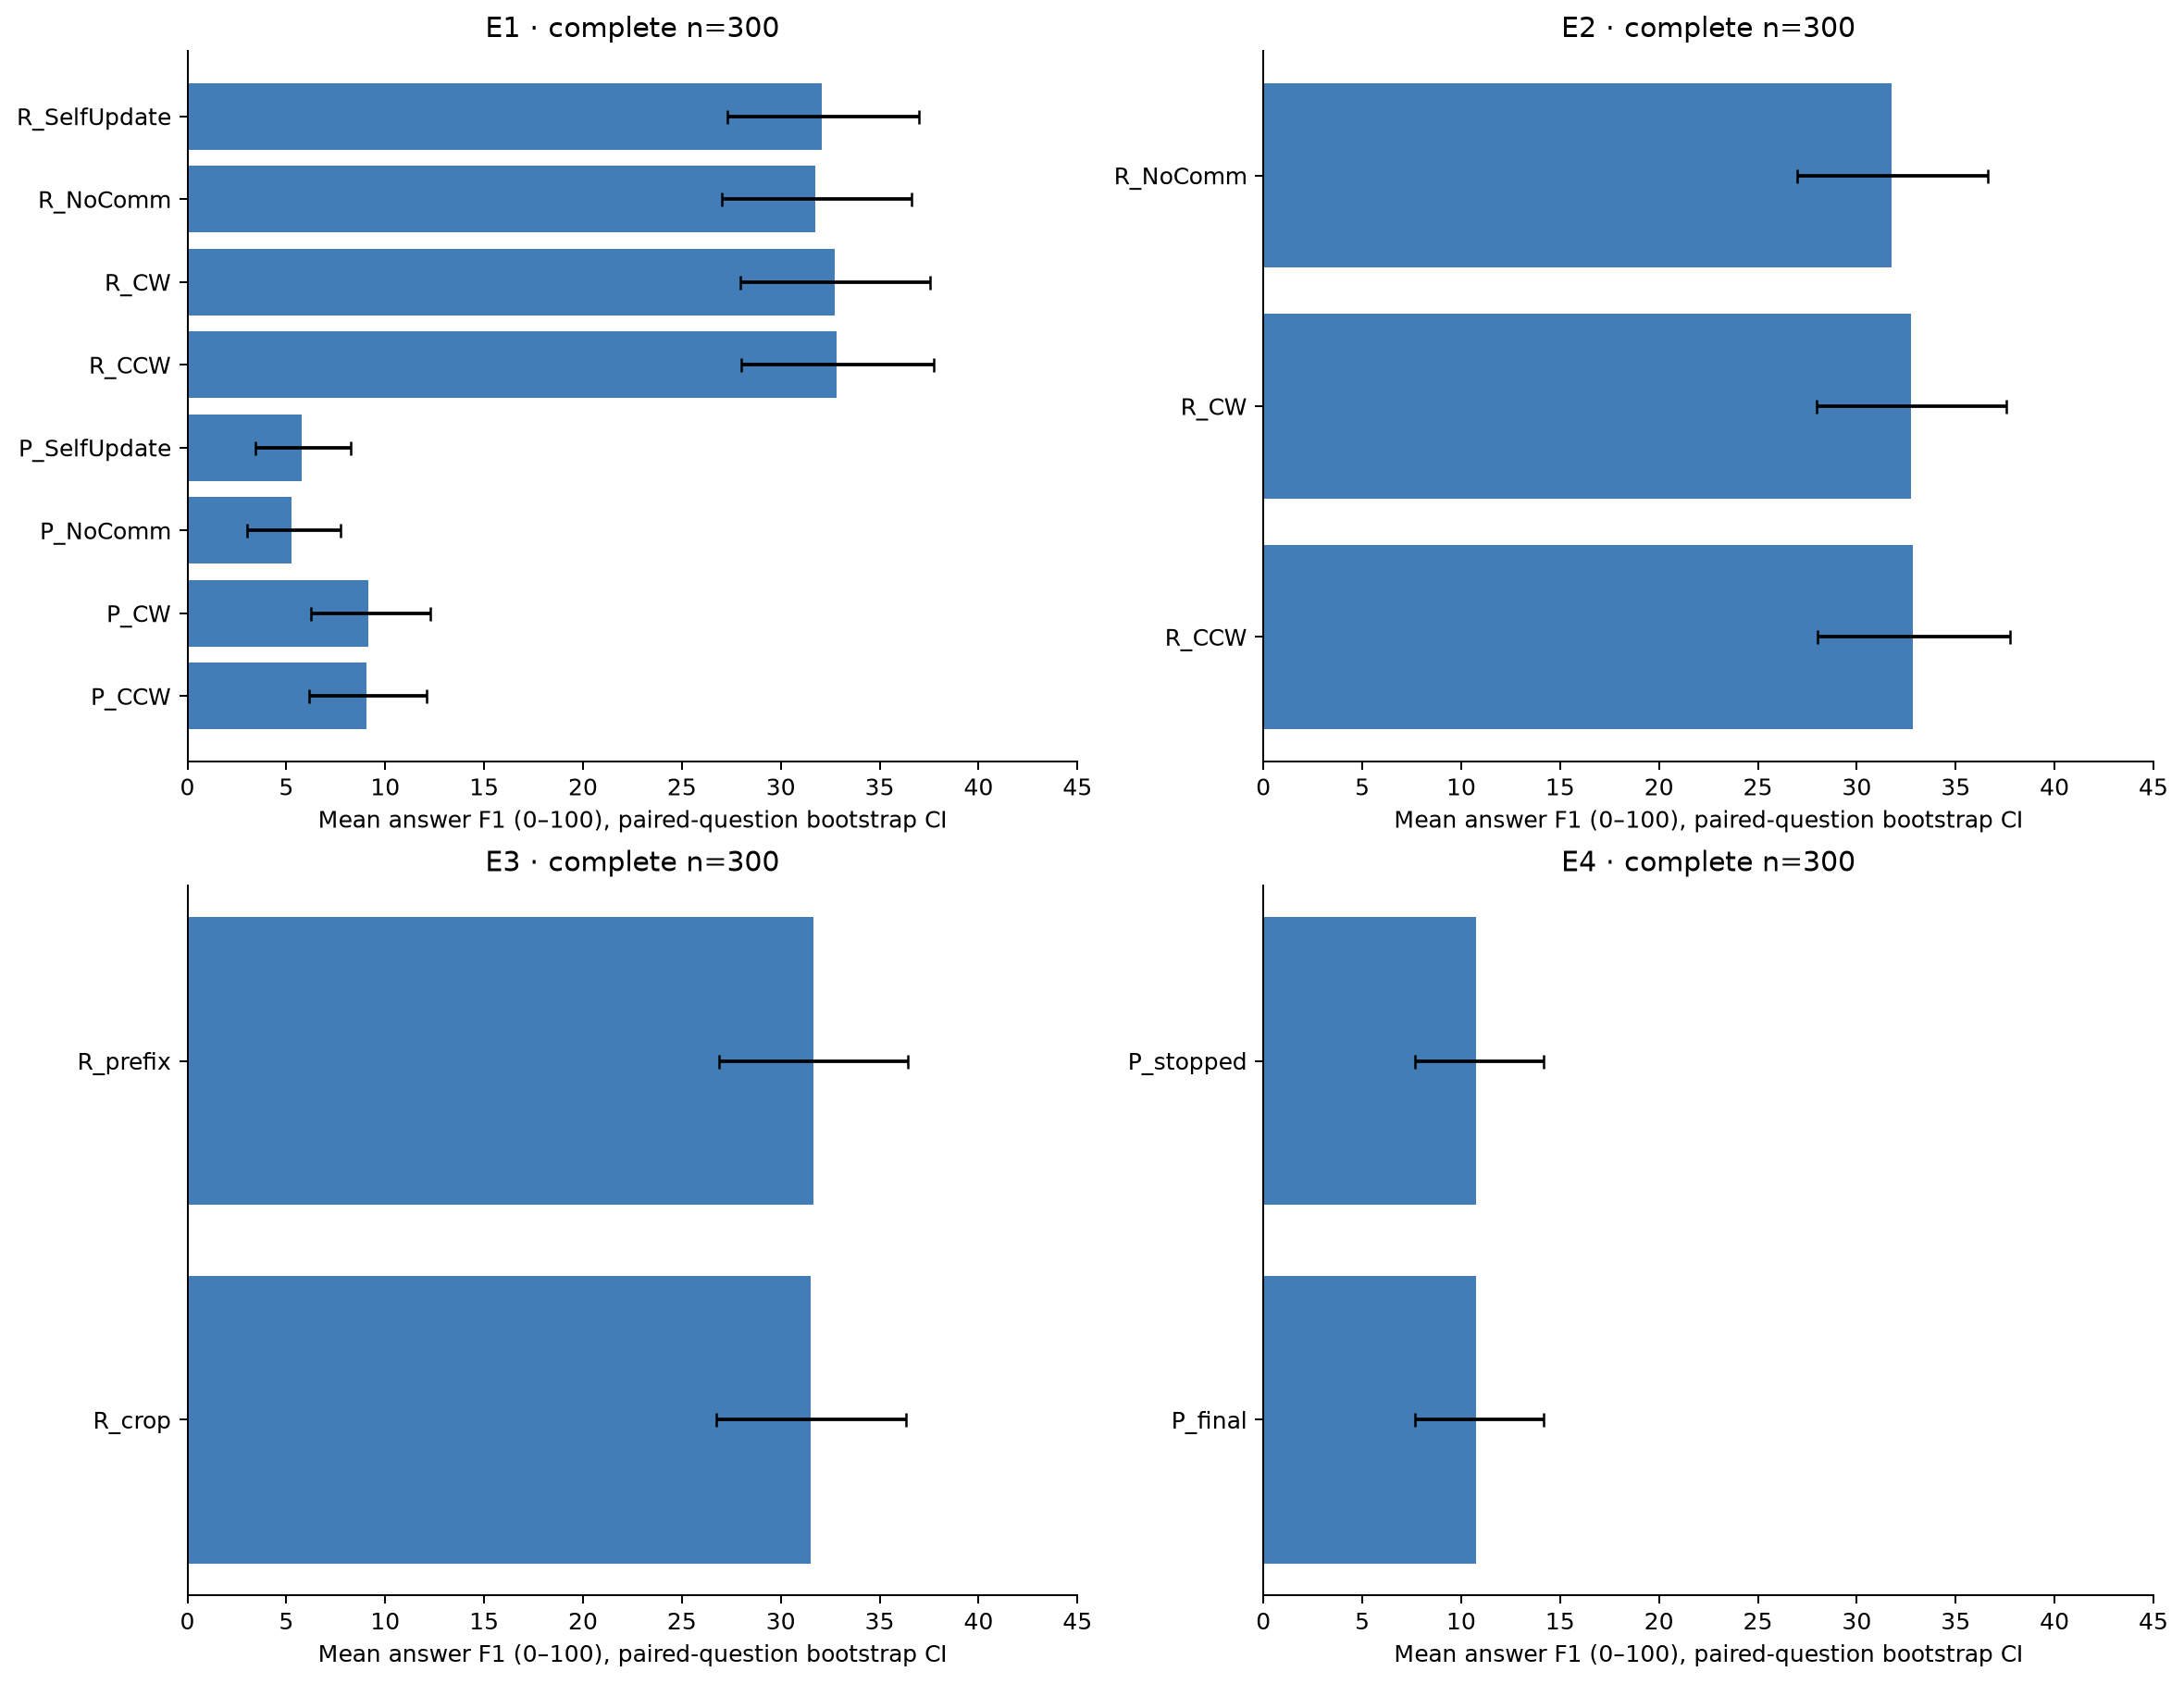

### 02 paired effects

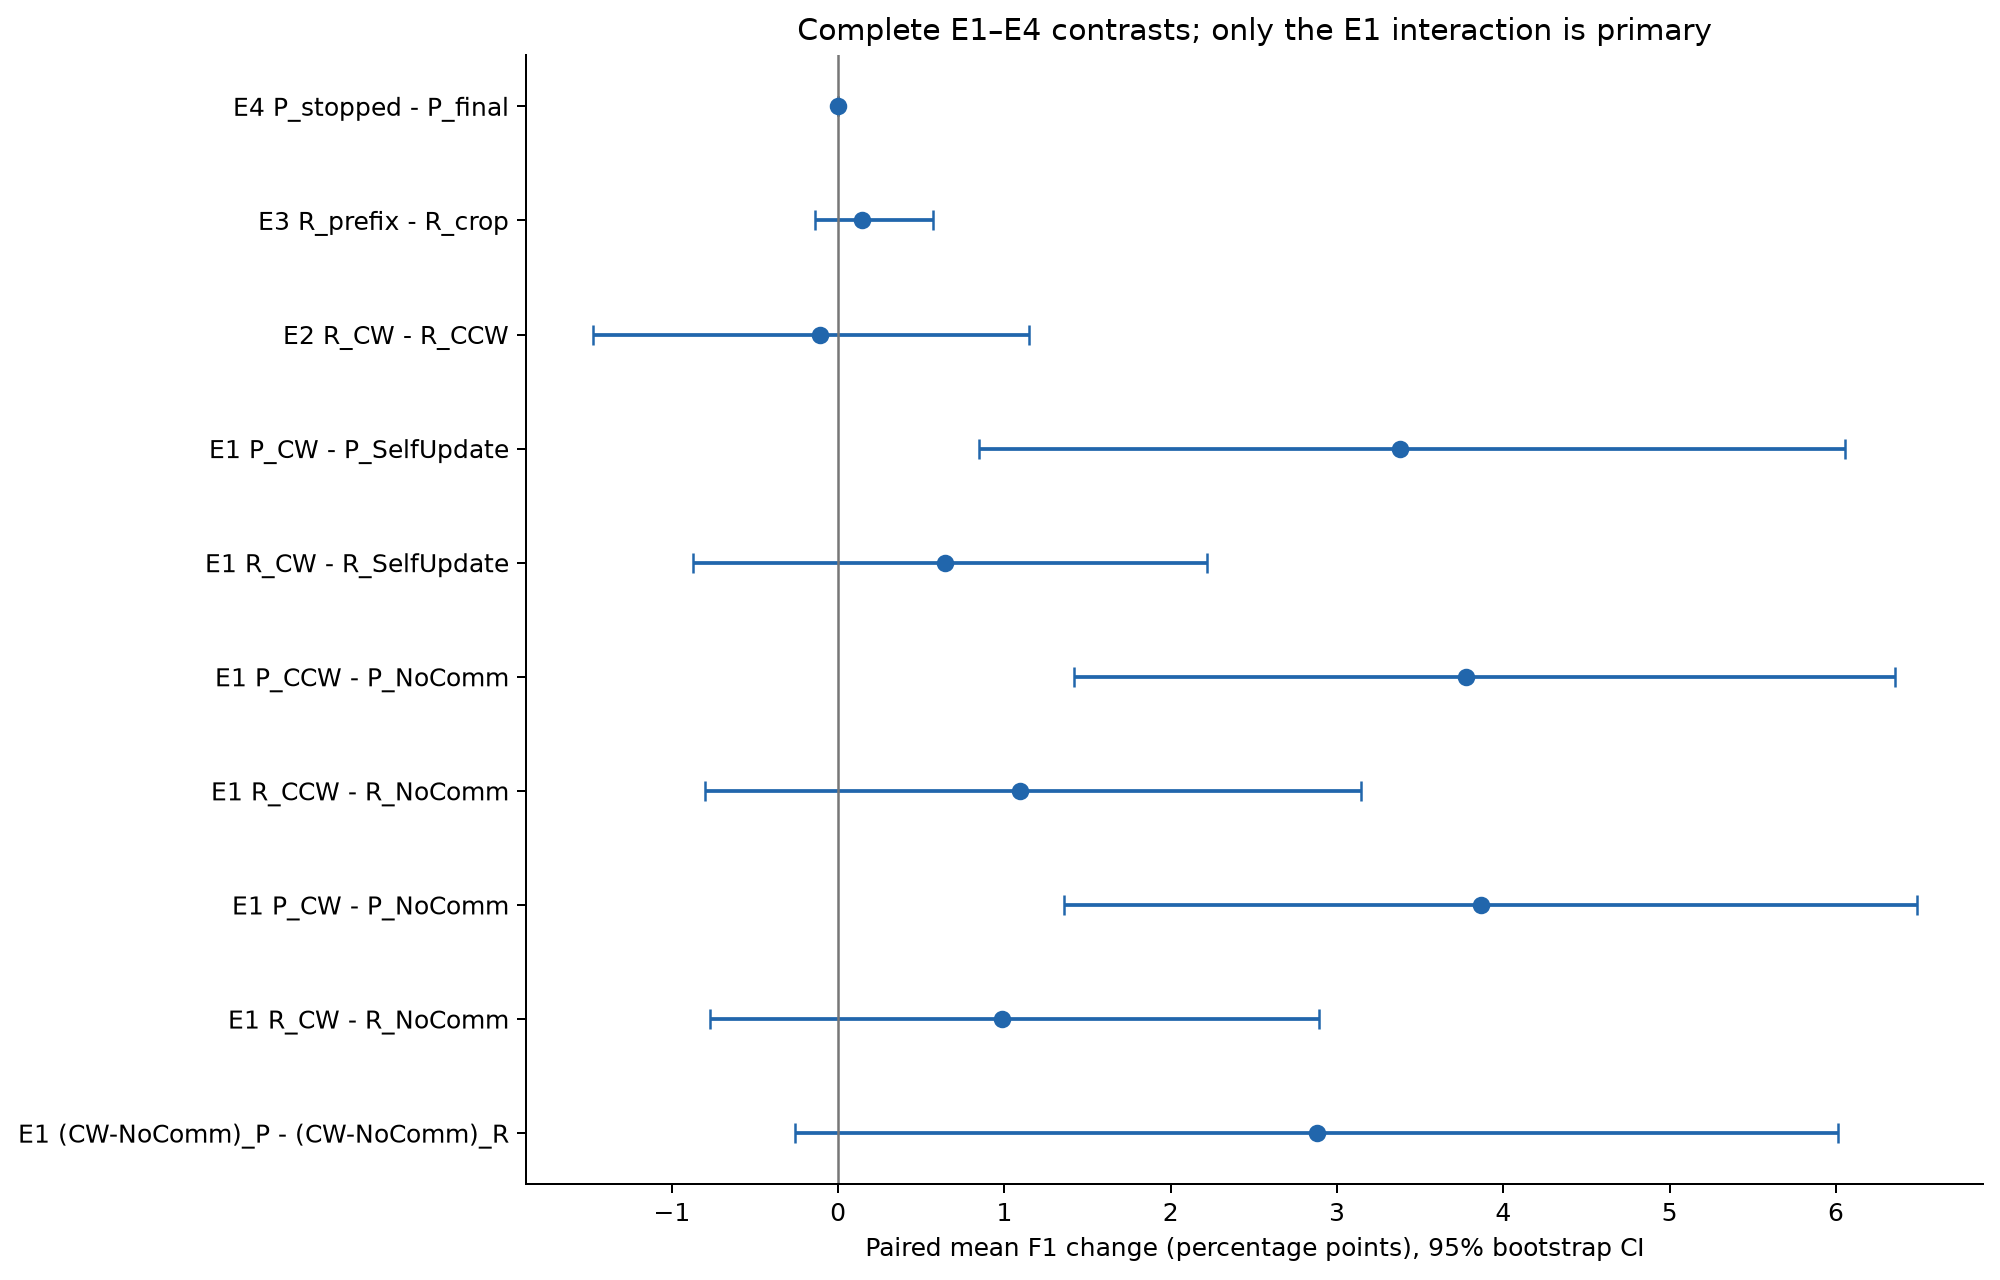

### 03 gold strata

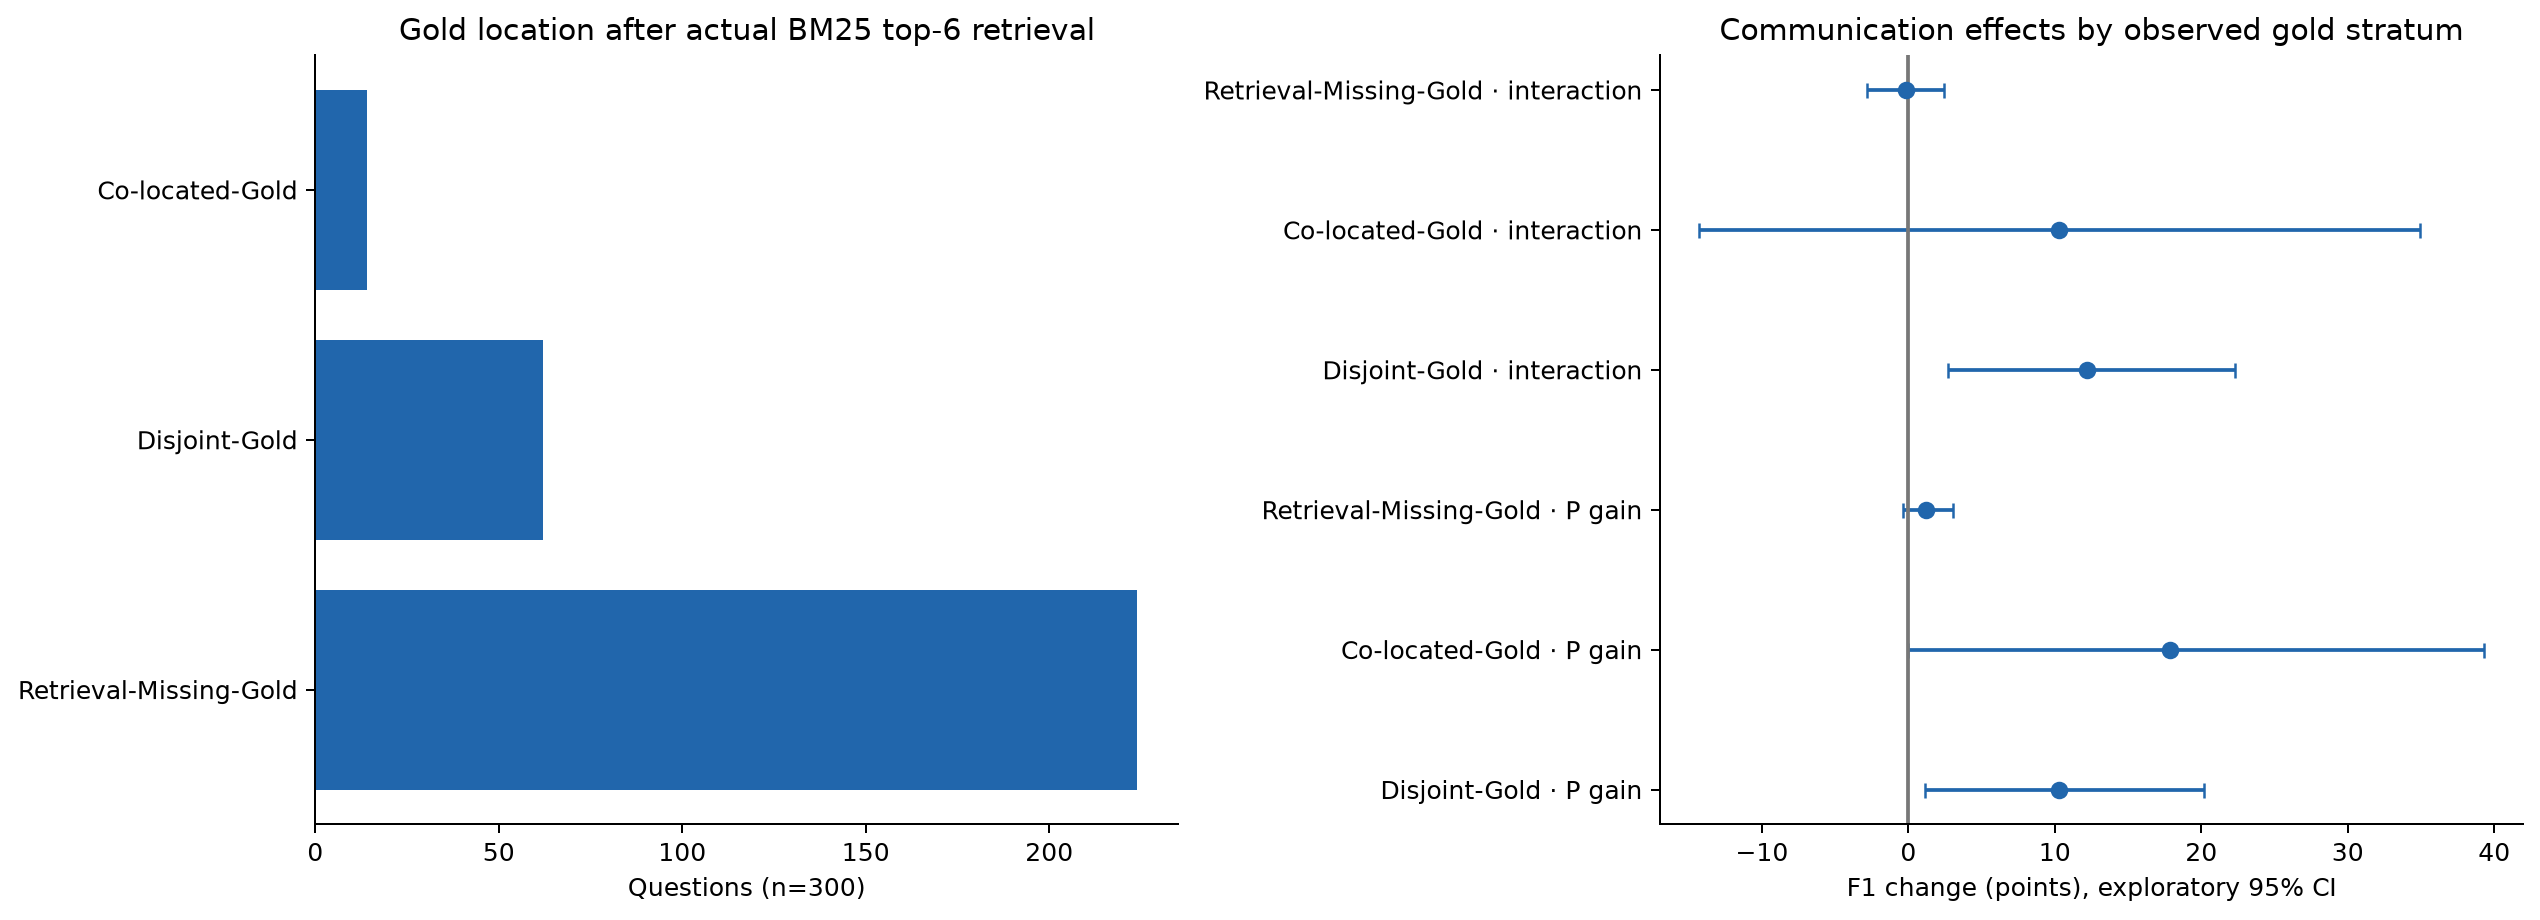

### 04 retrieval audit

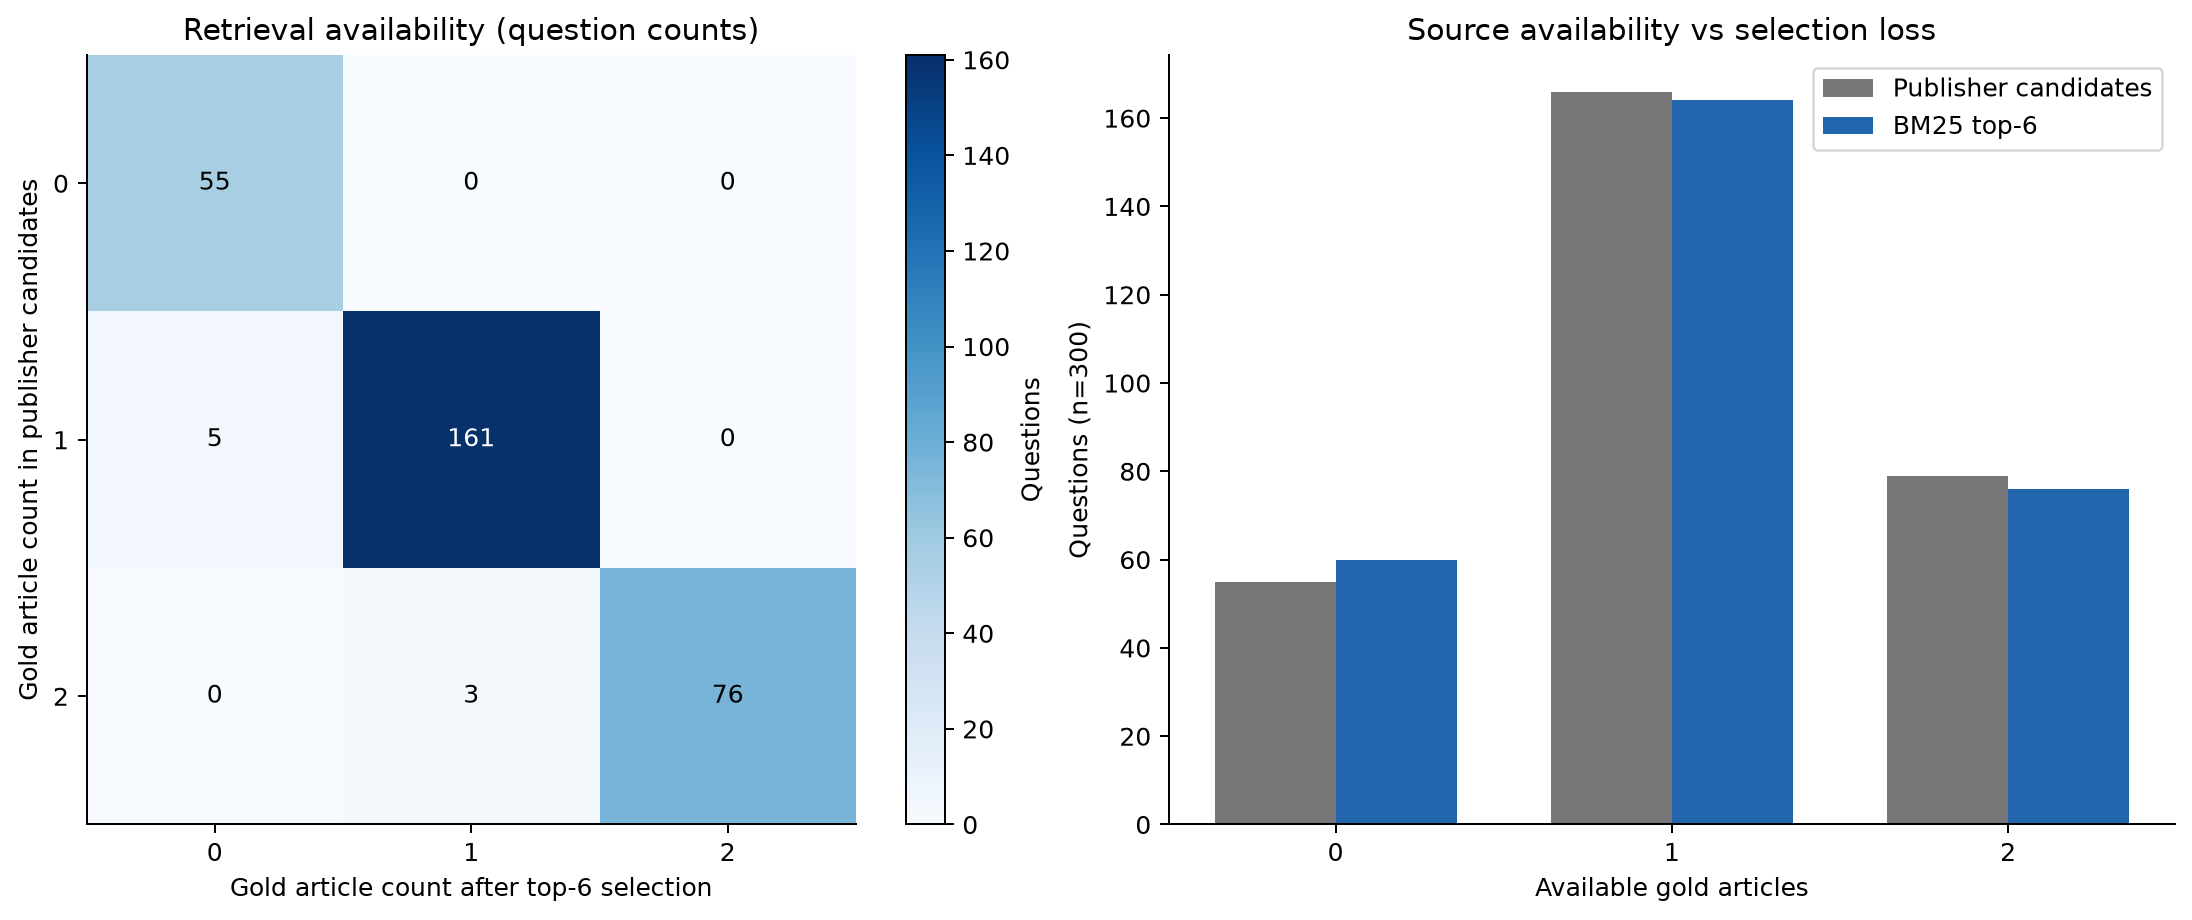

### 05 paired transitions

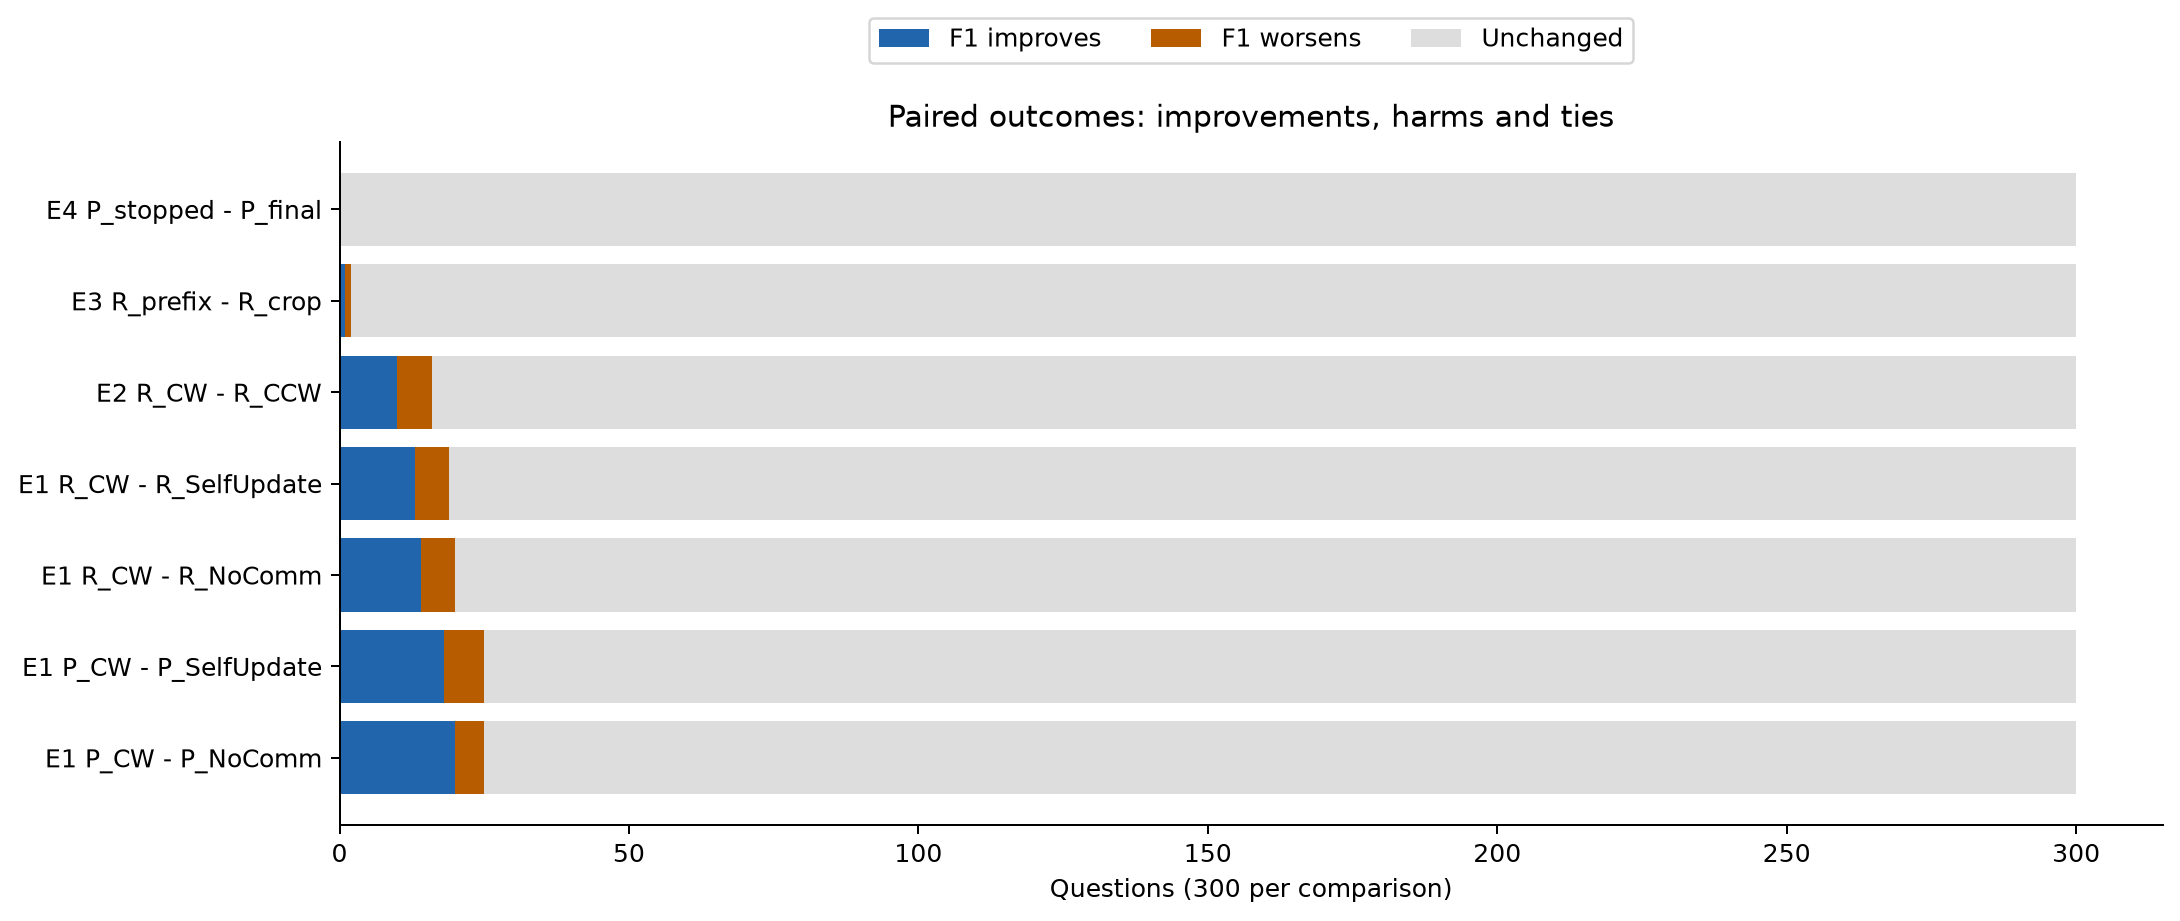

### 06 resource frontiers

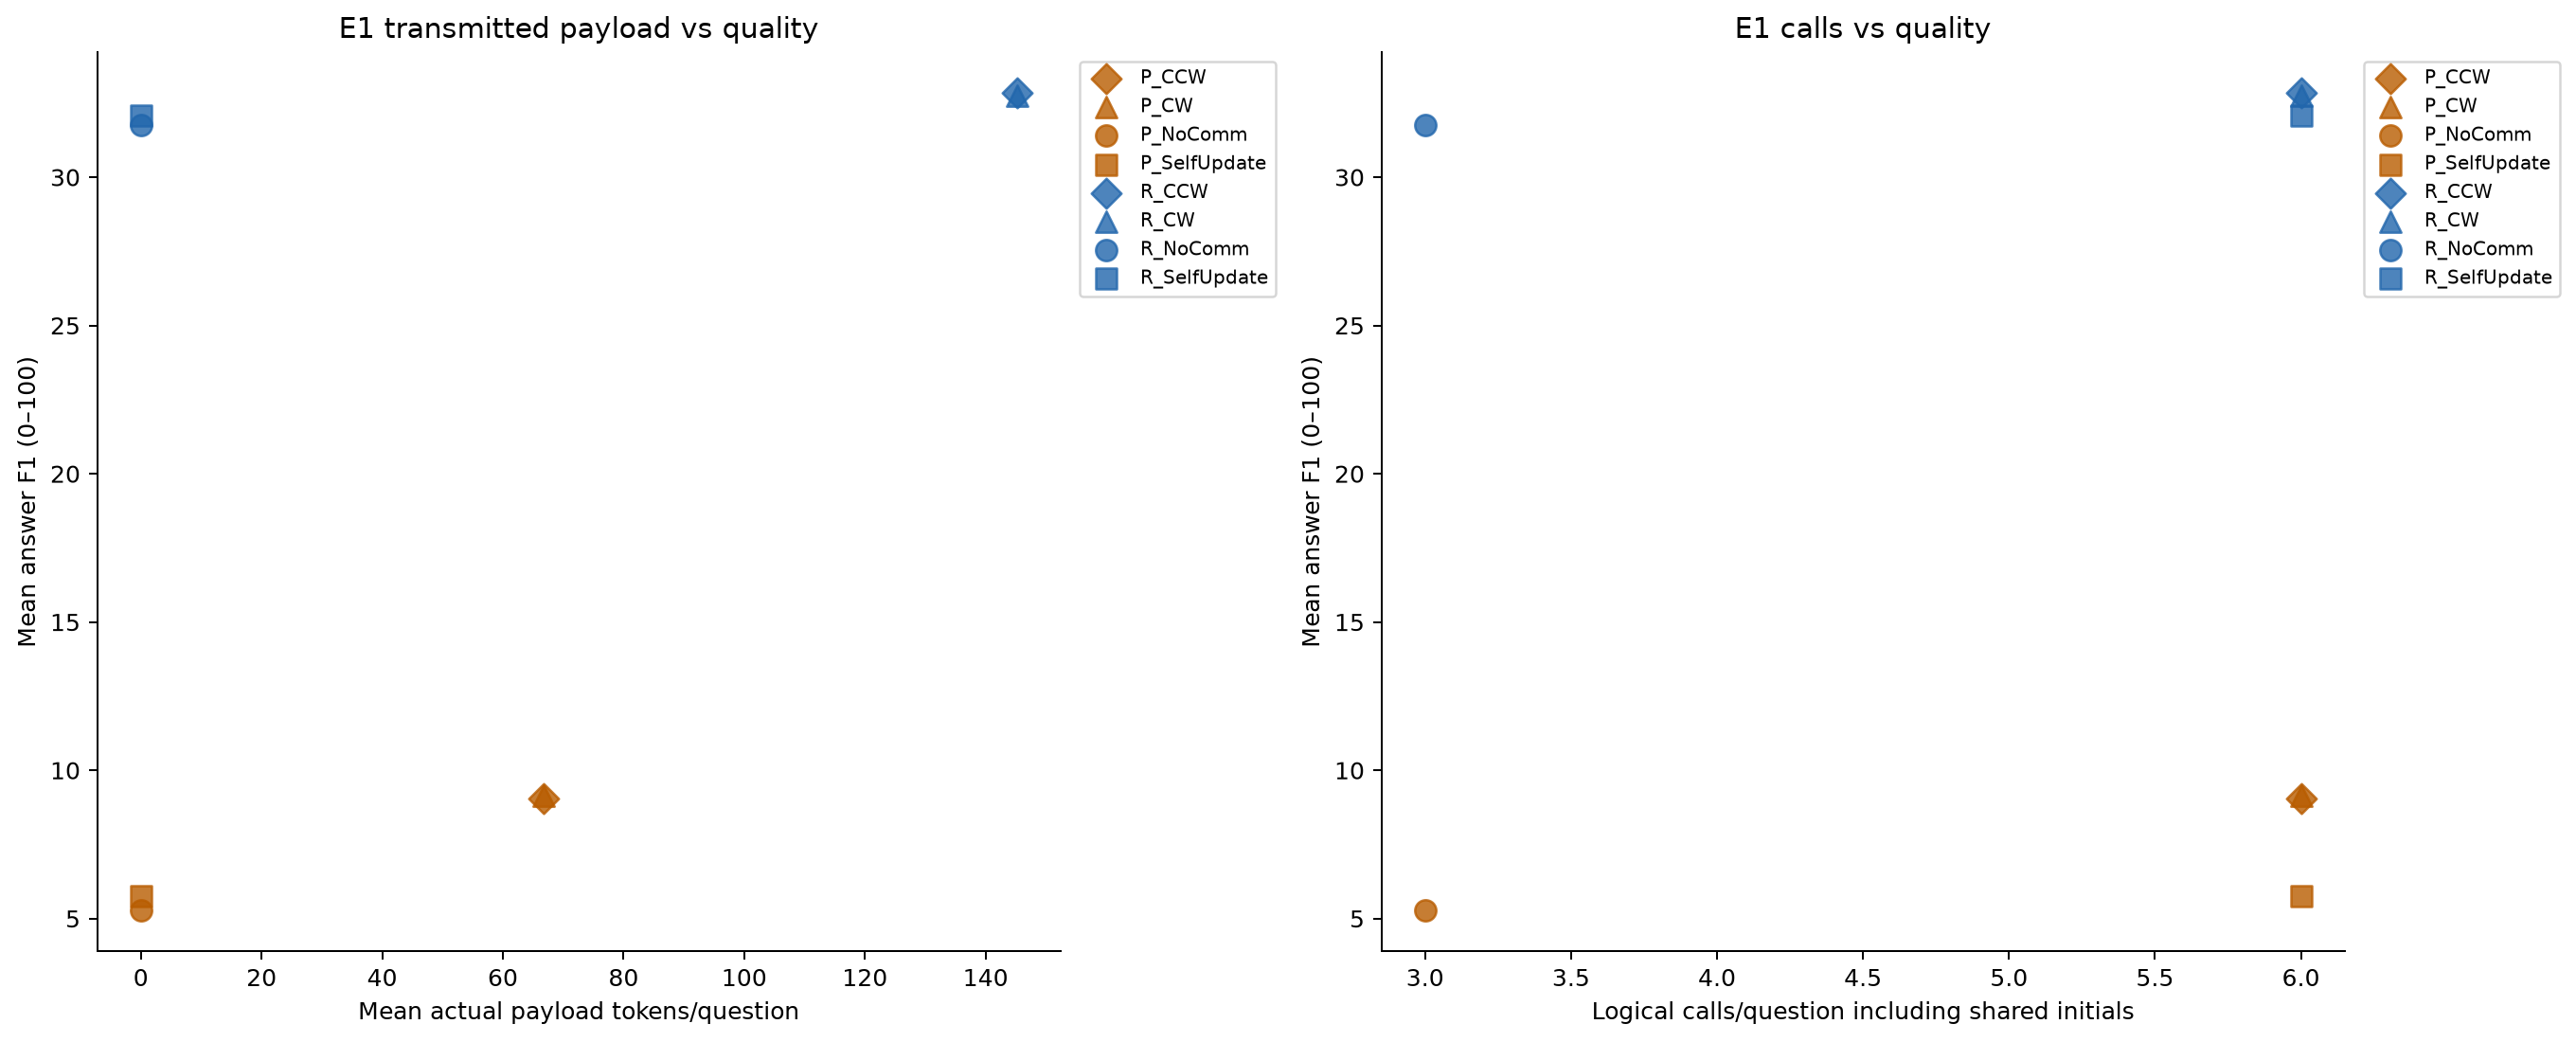

### 07 content intervention

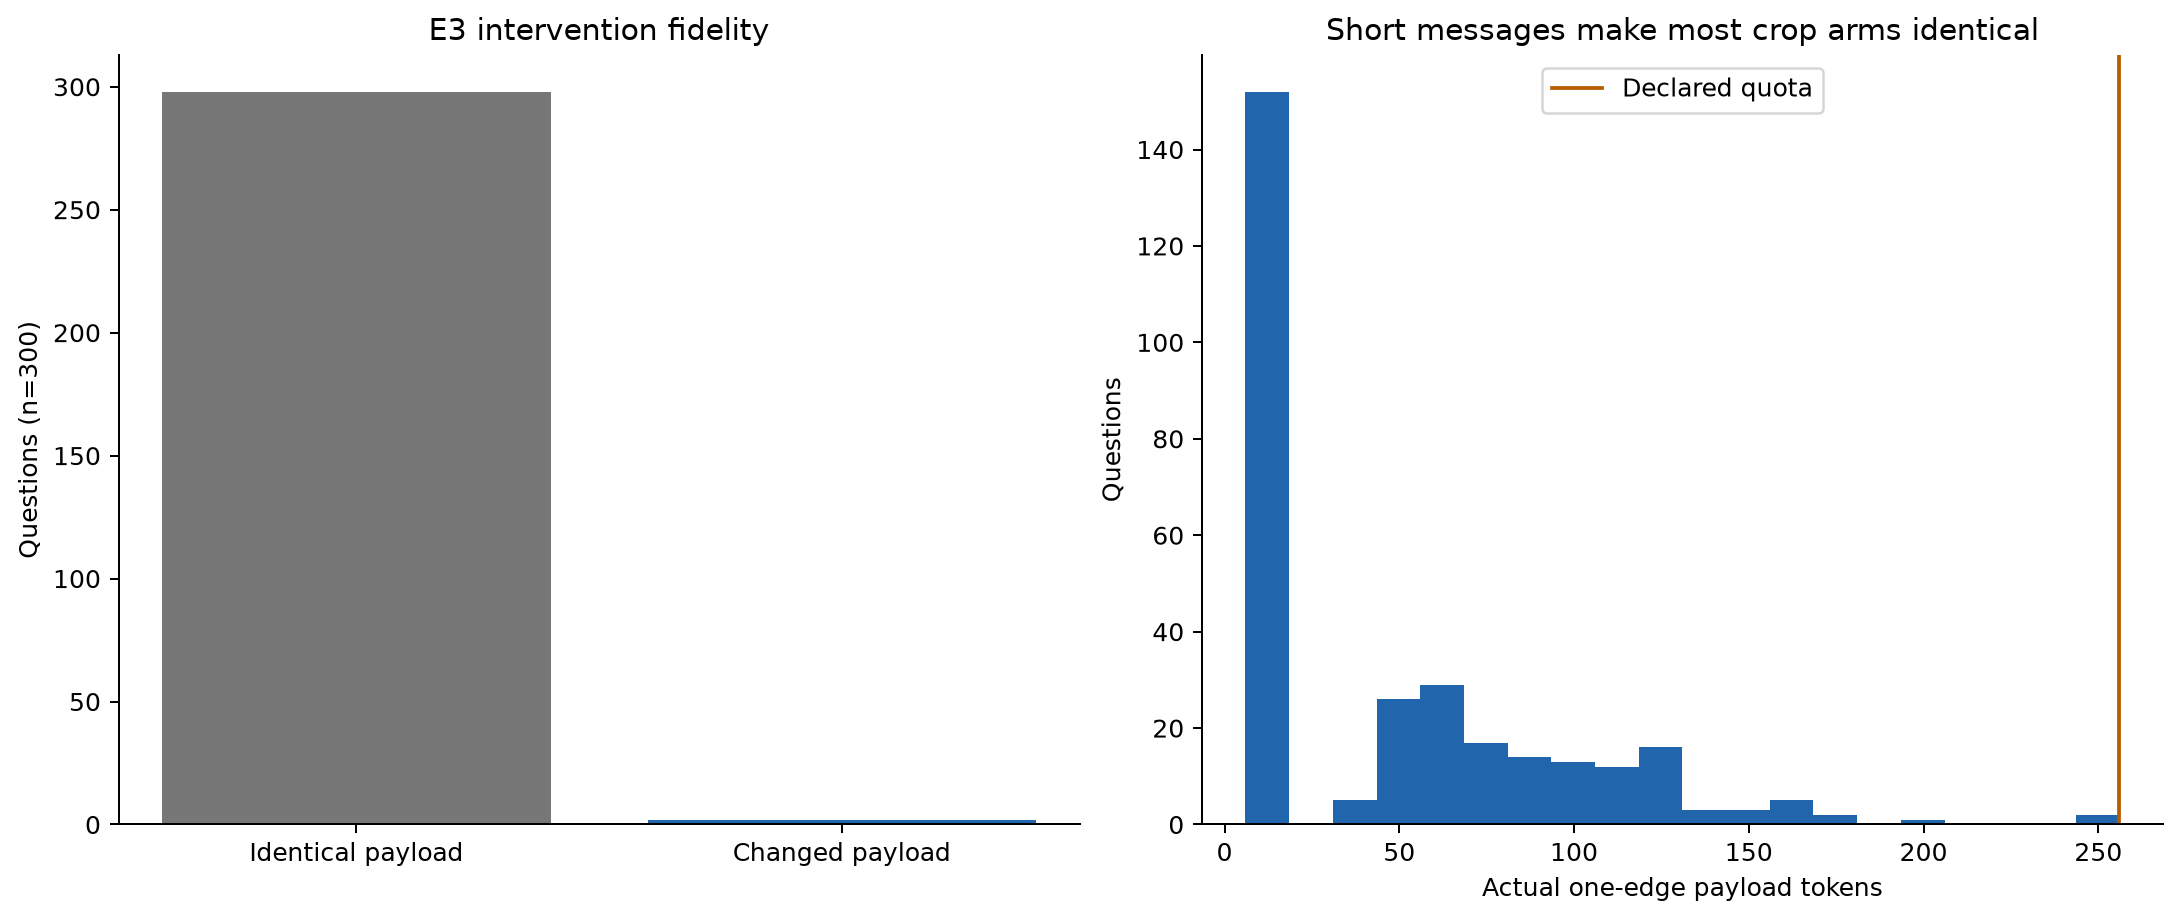

### 08 stopping trajectory

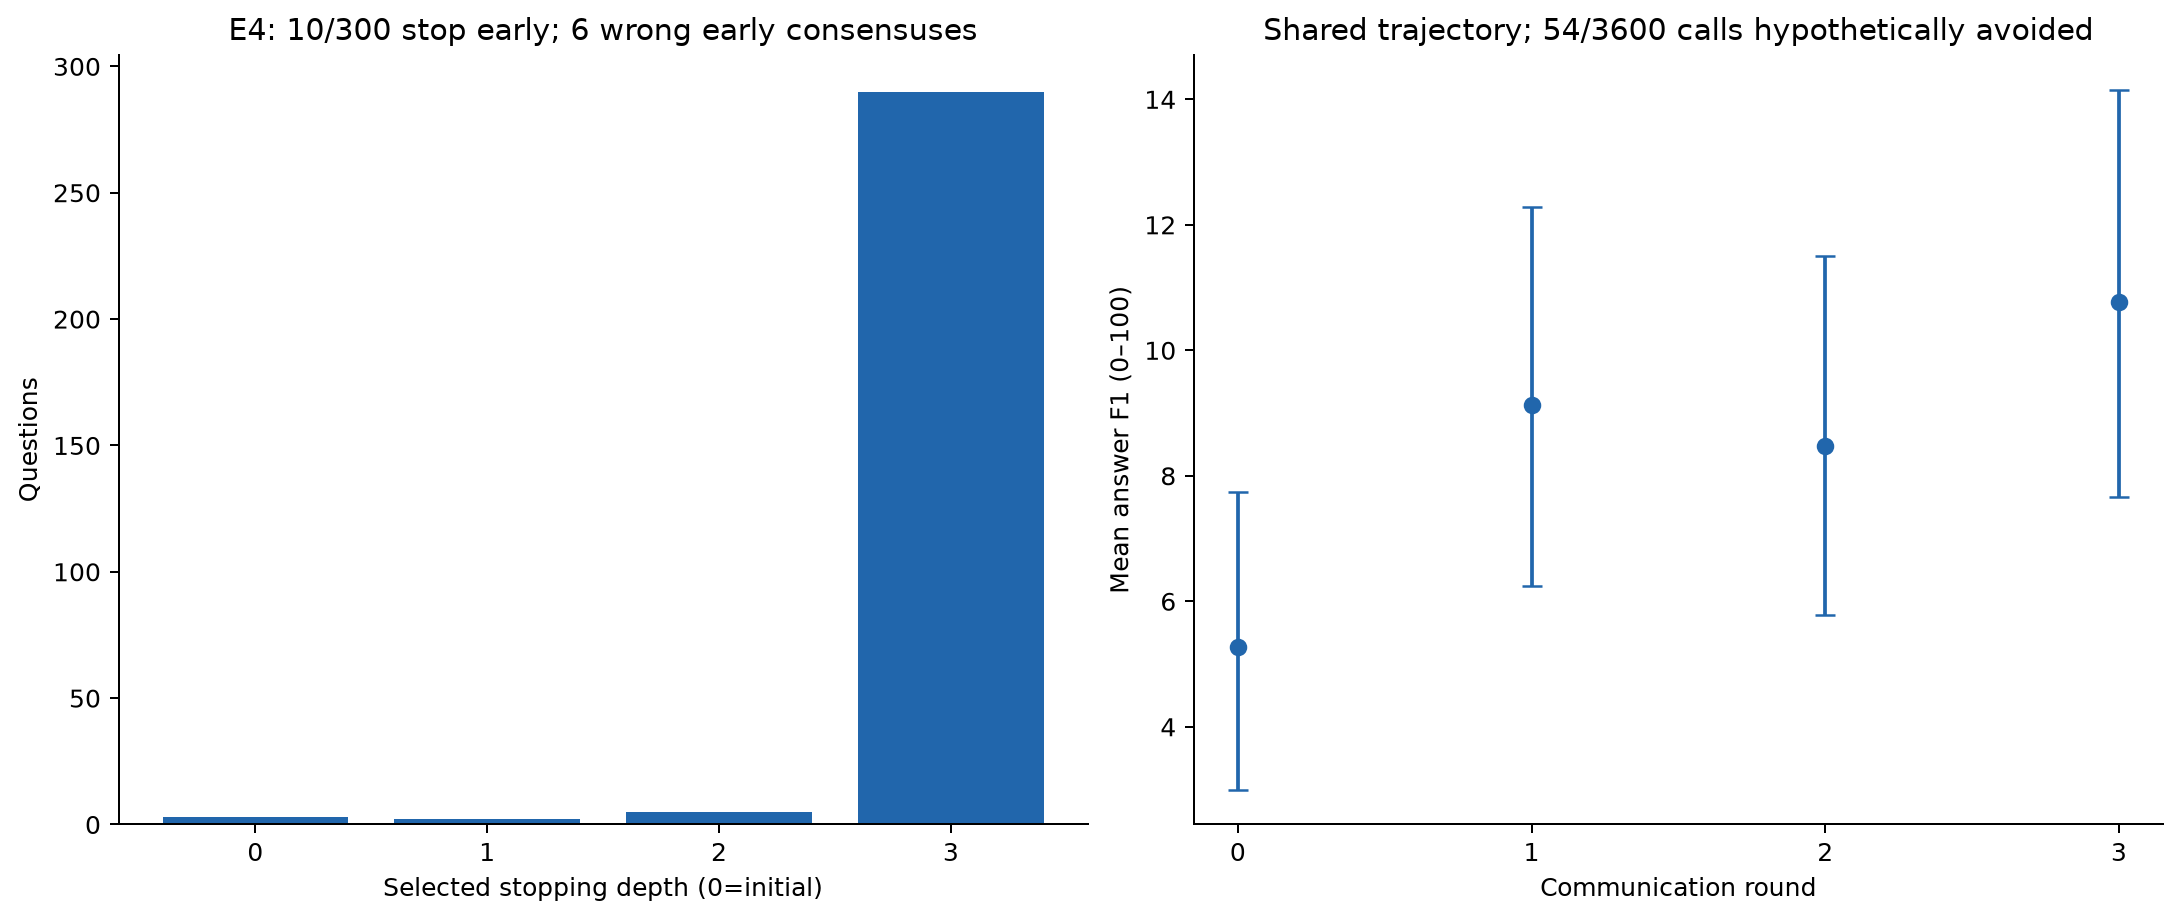

### 09 controller training

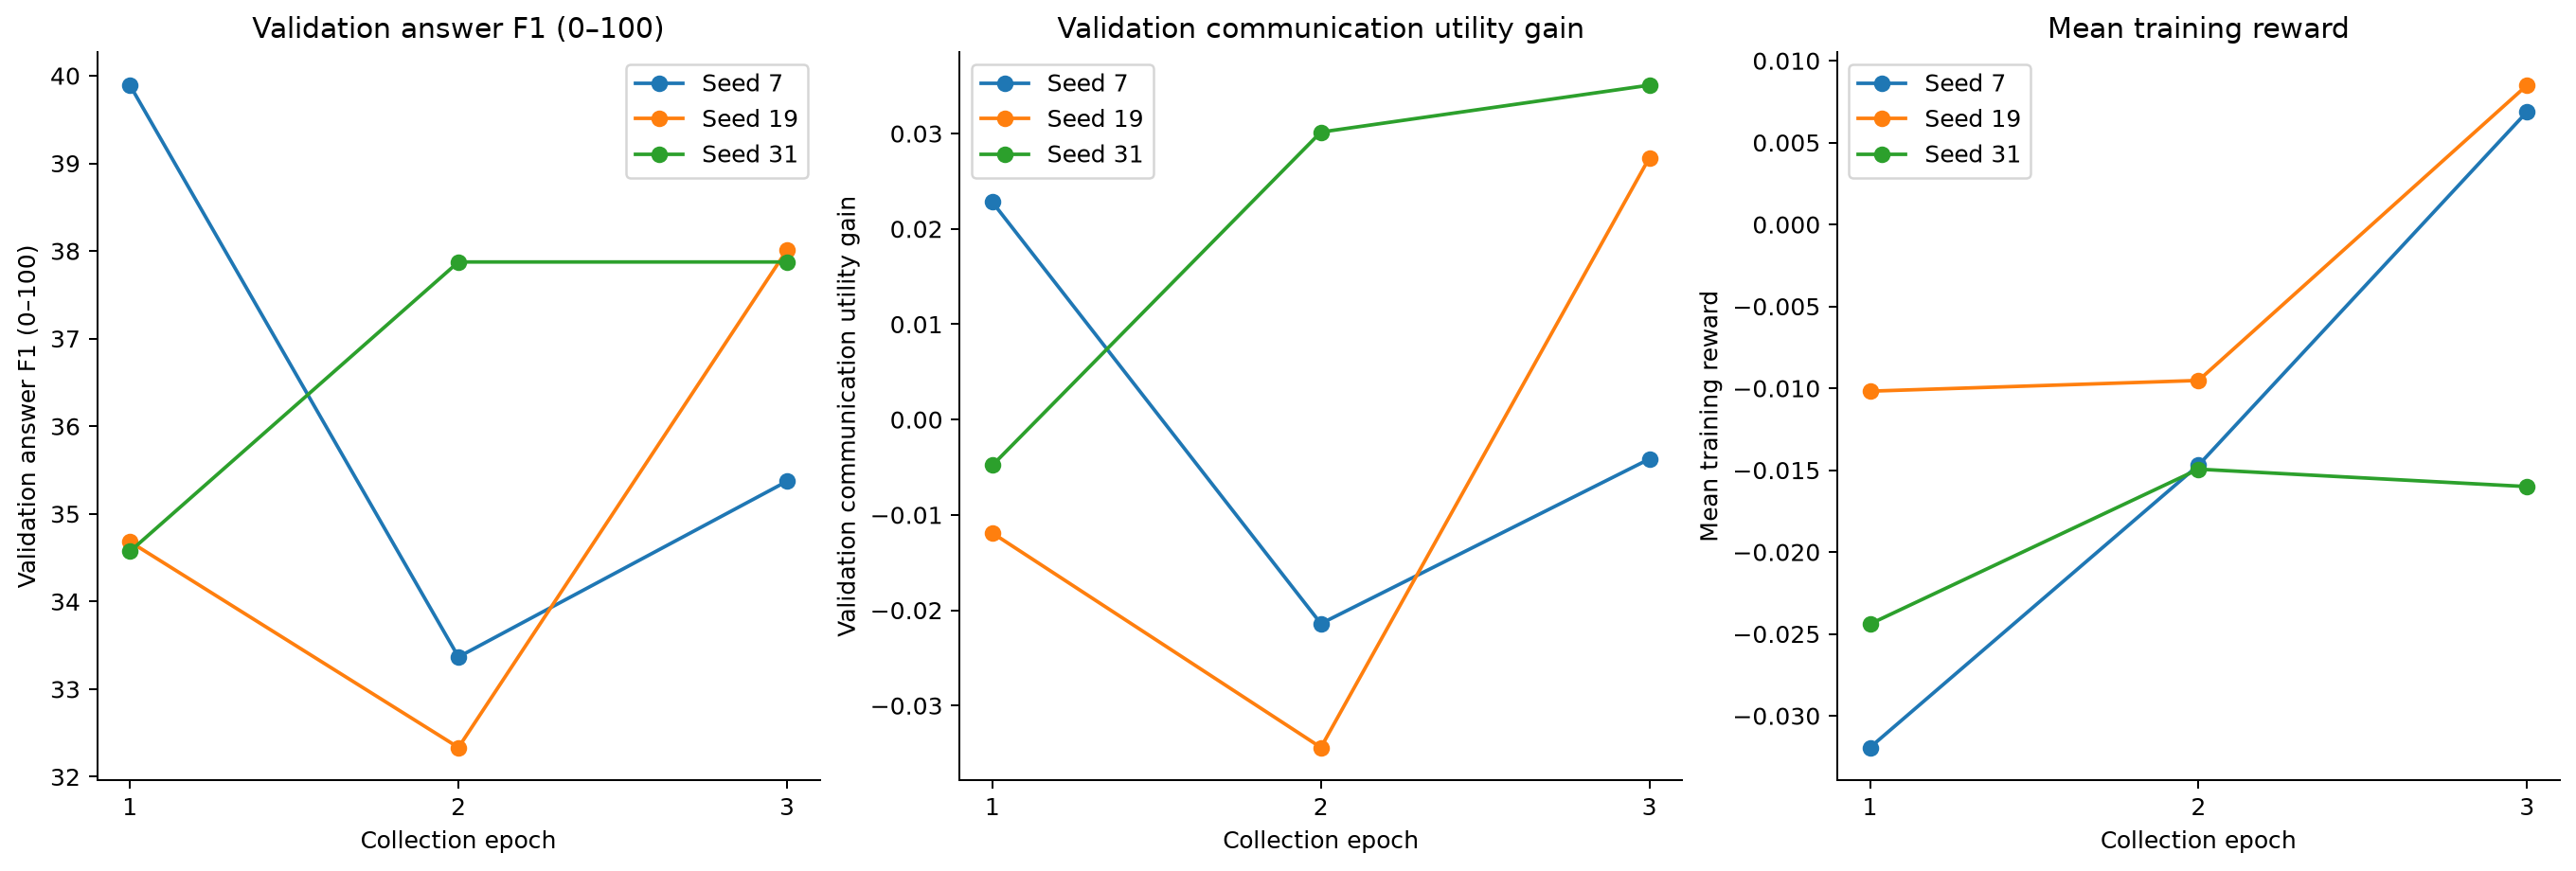

### 10 E5 partial quality

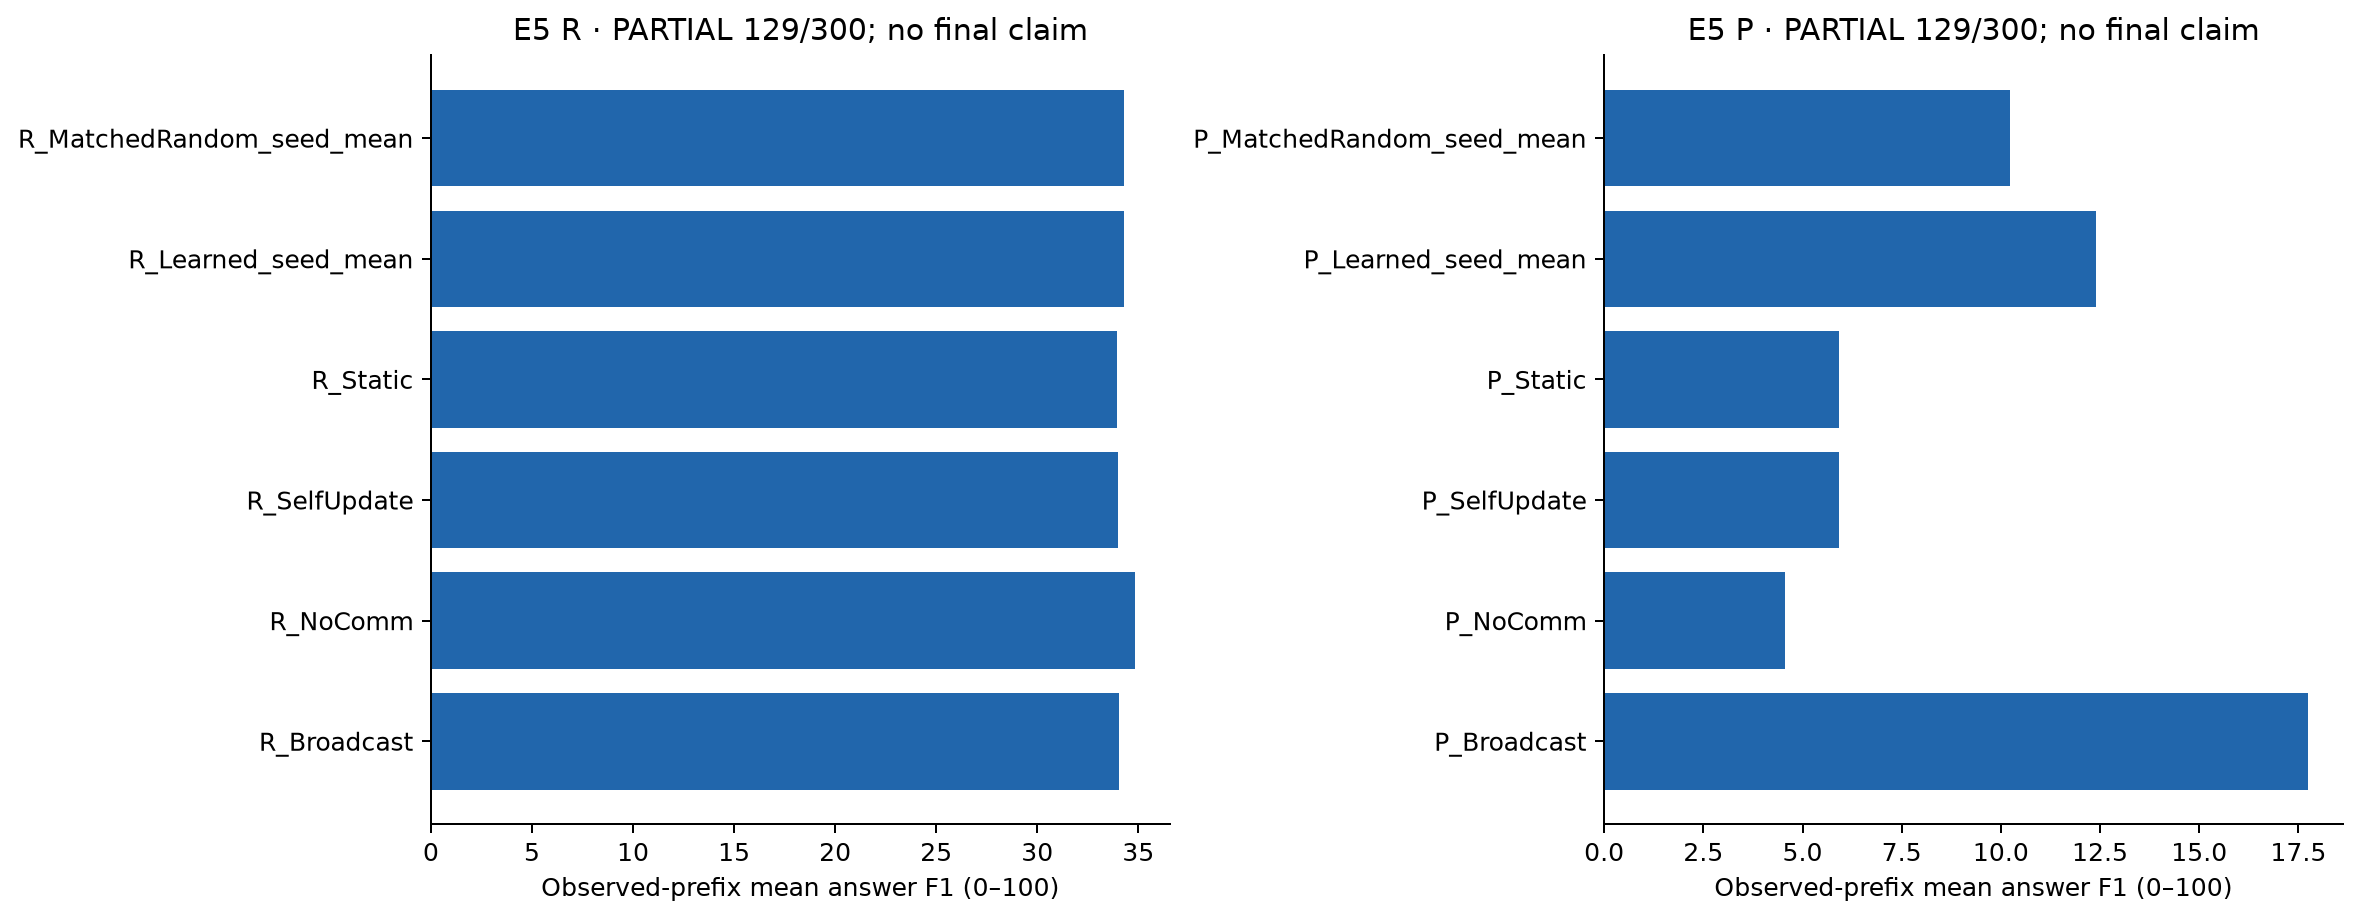

### 11 E5 partial action adaptivity

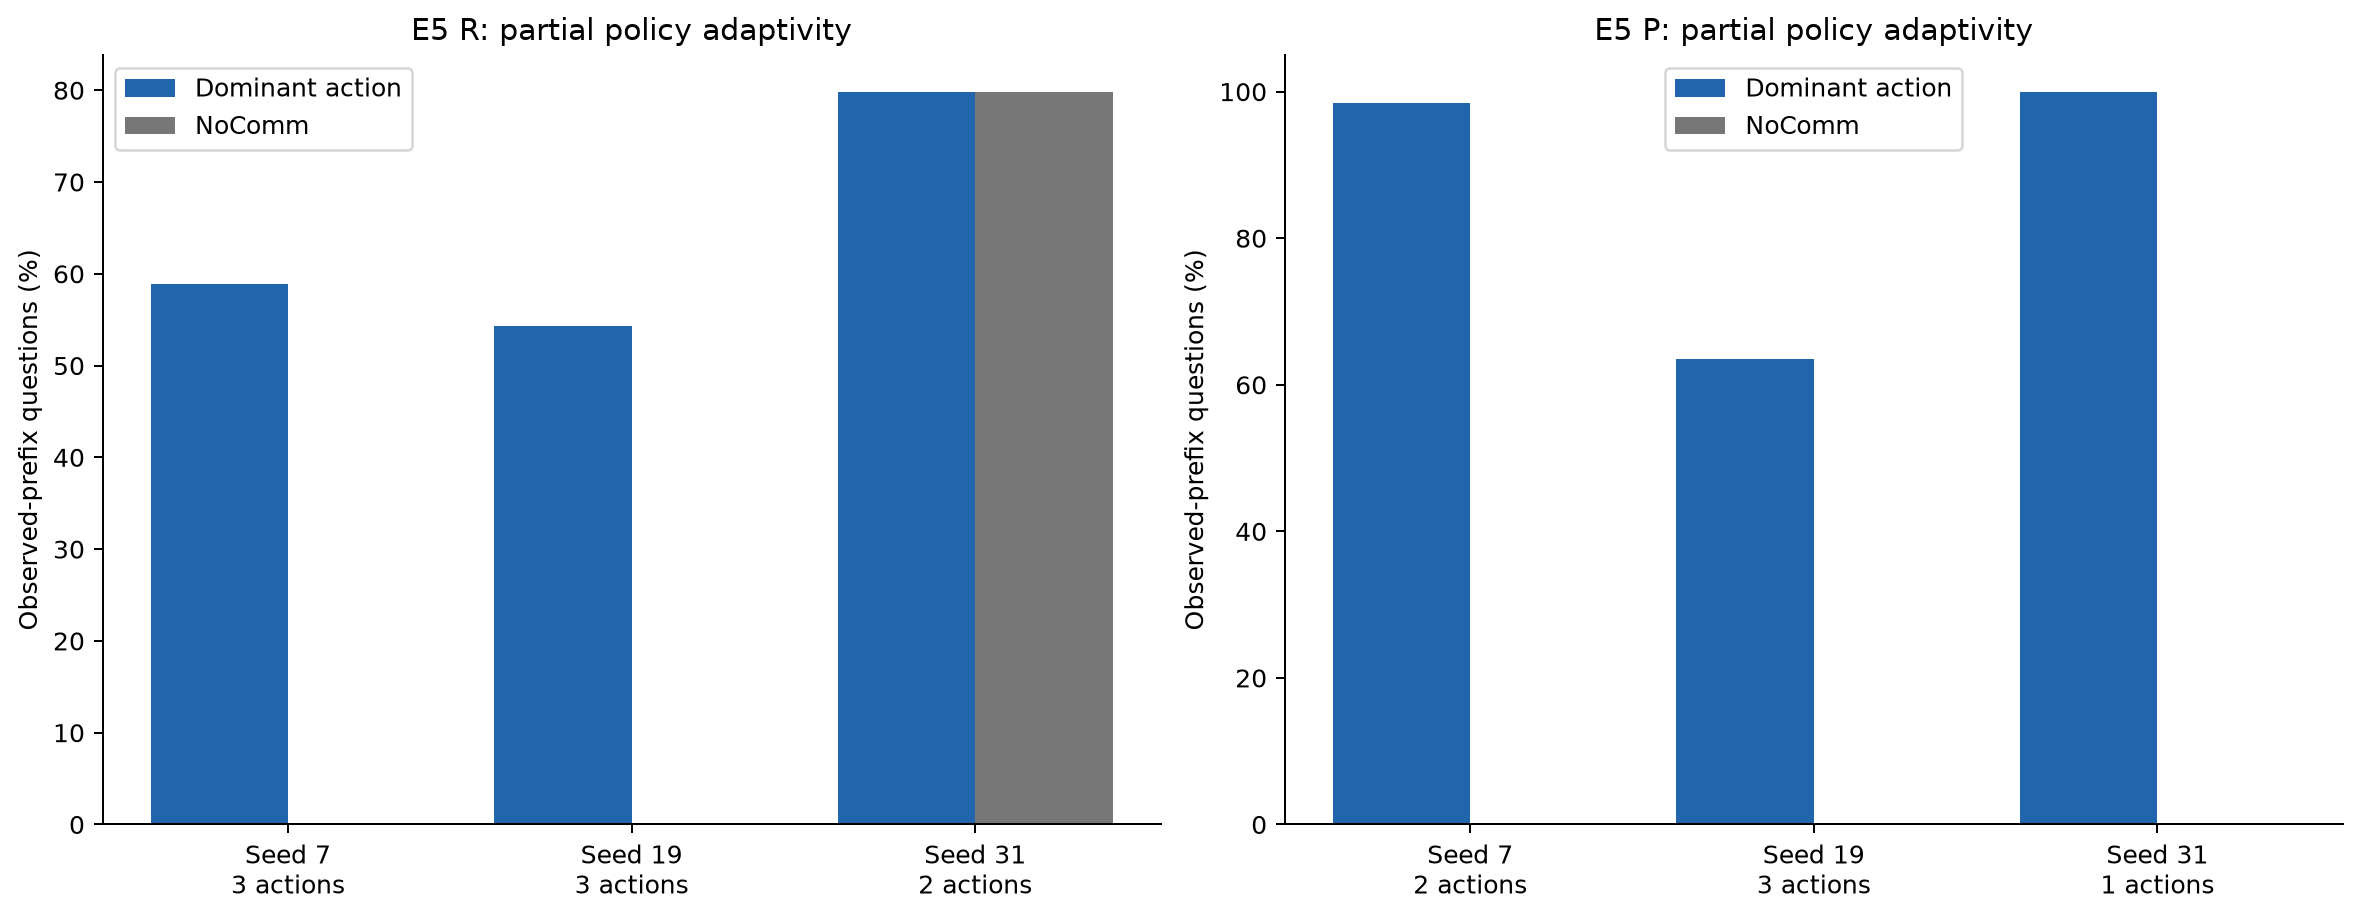

### 12 latency and accounting

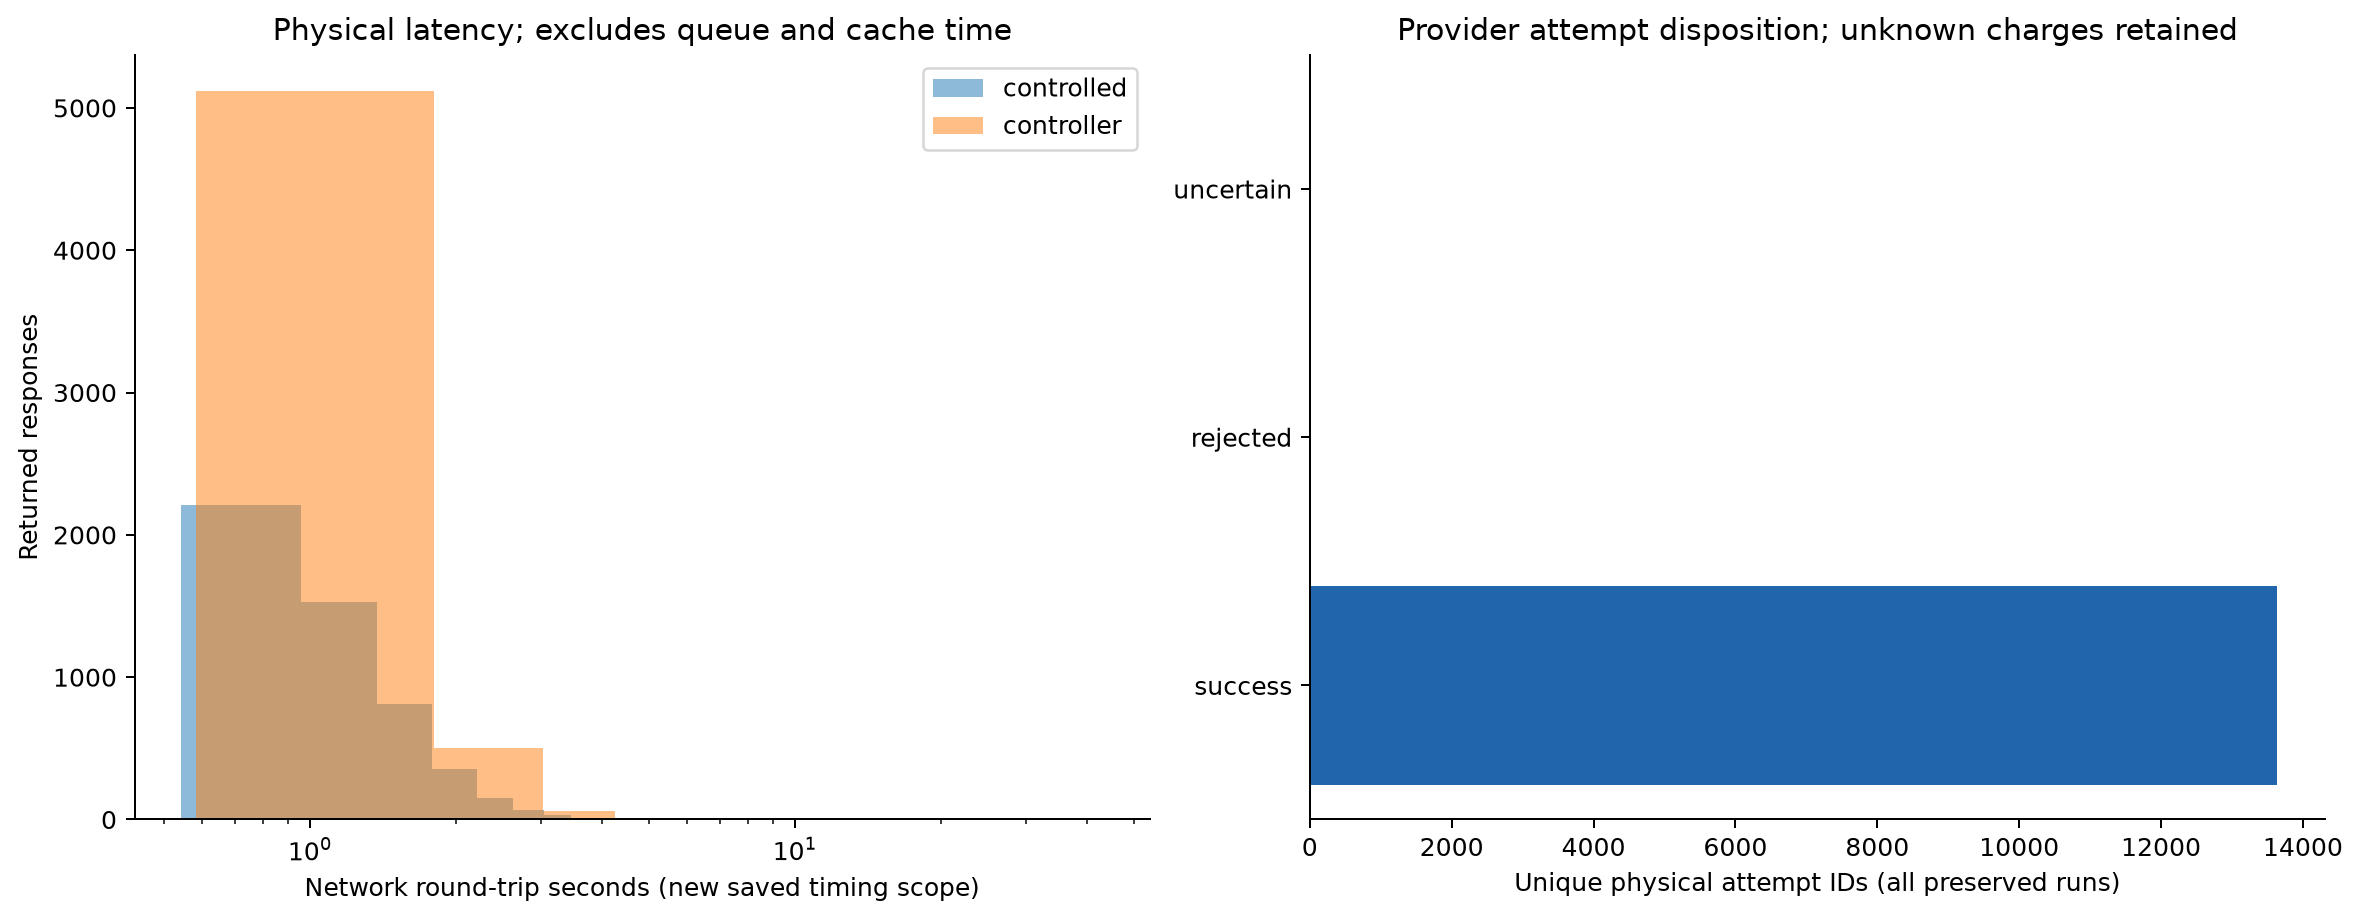

### 13 E5 partial paired effects

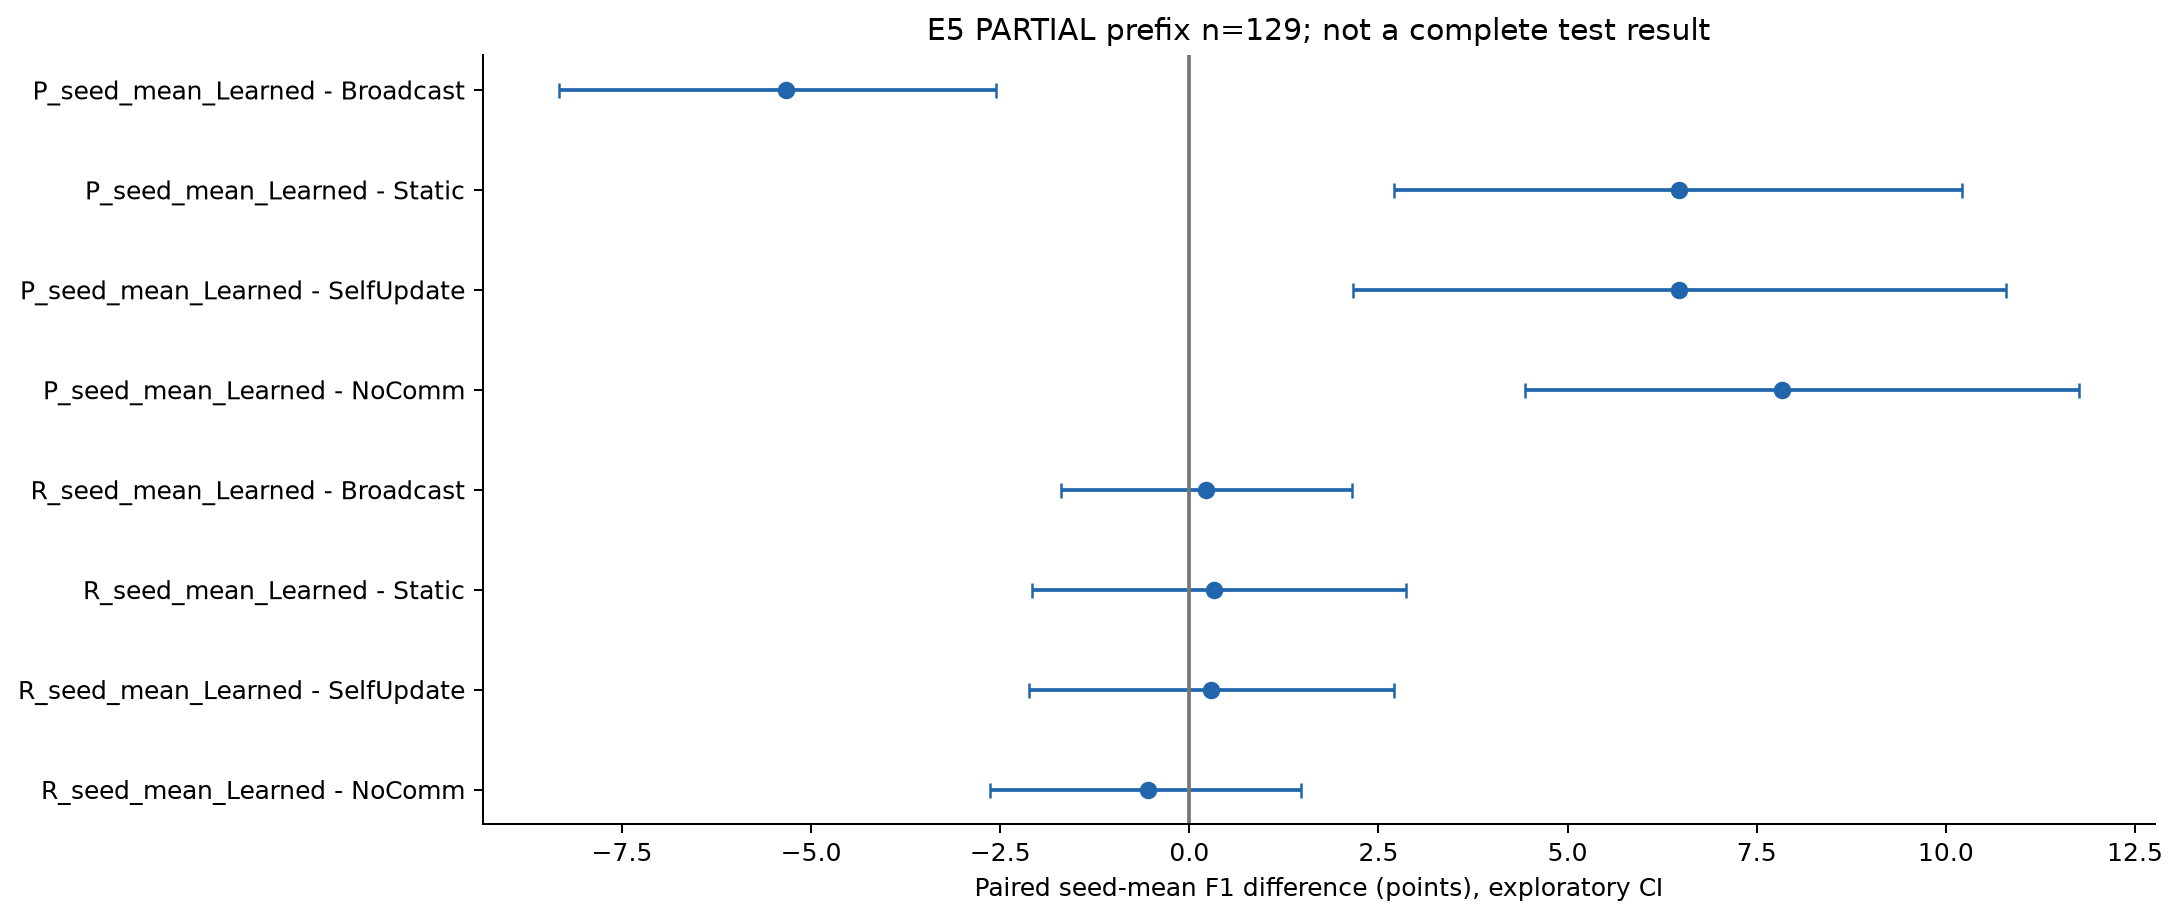

### 14 optimizer diagnostics

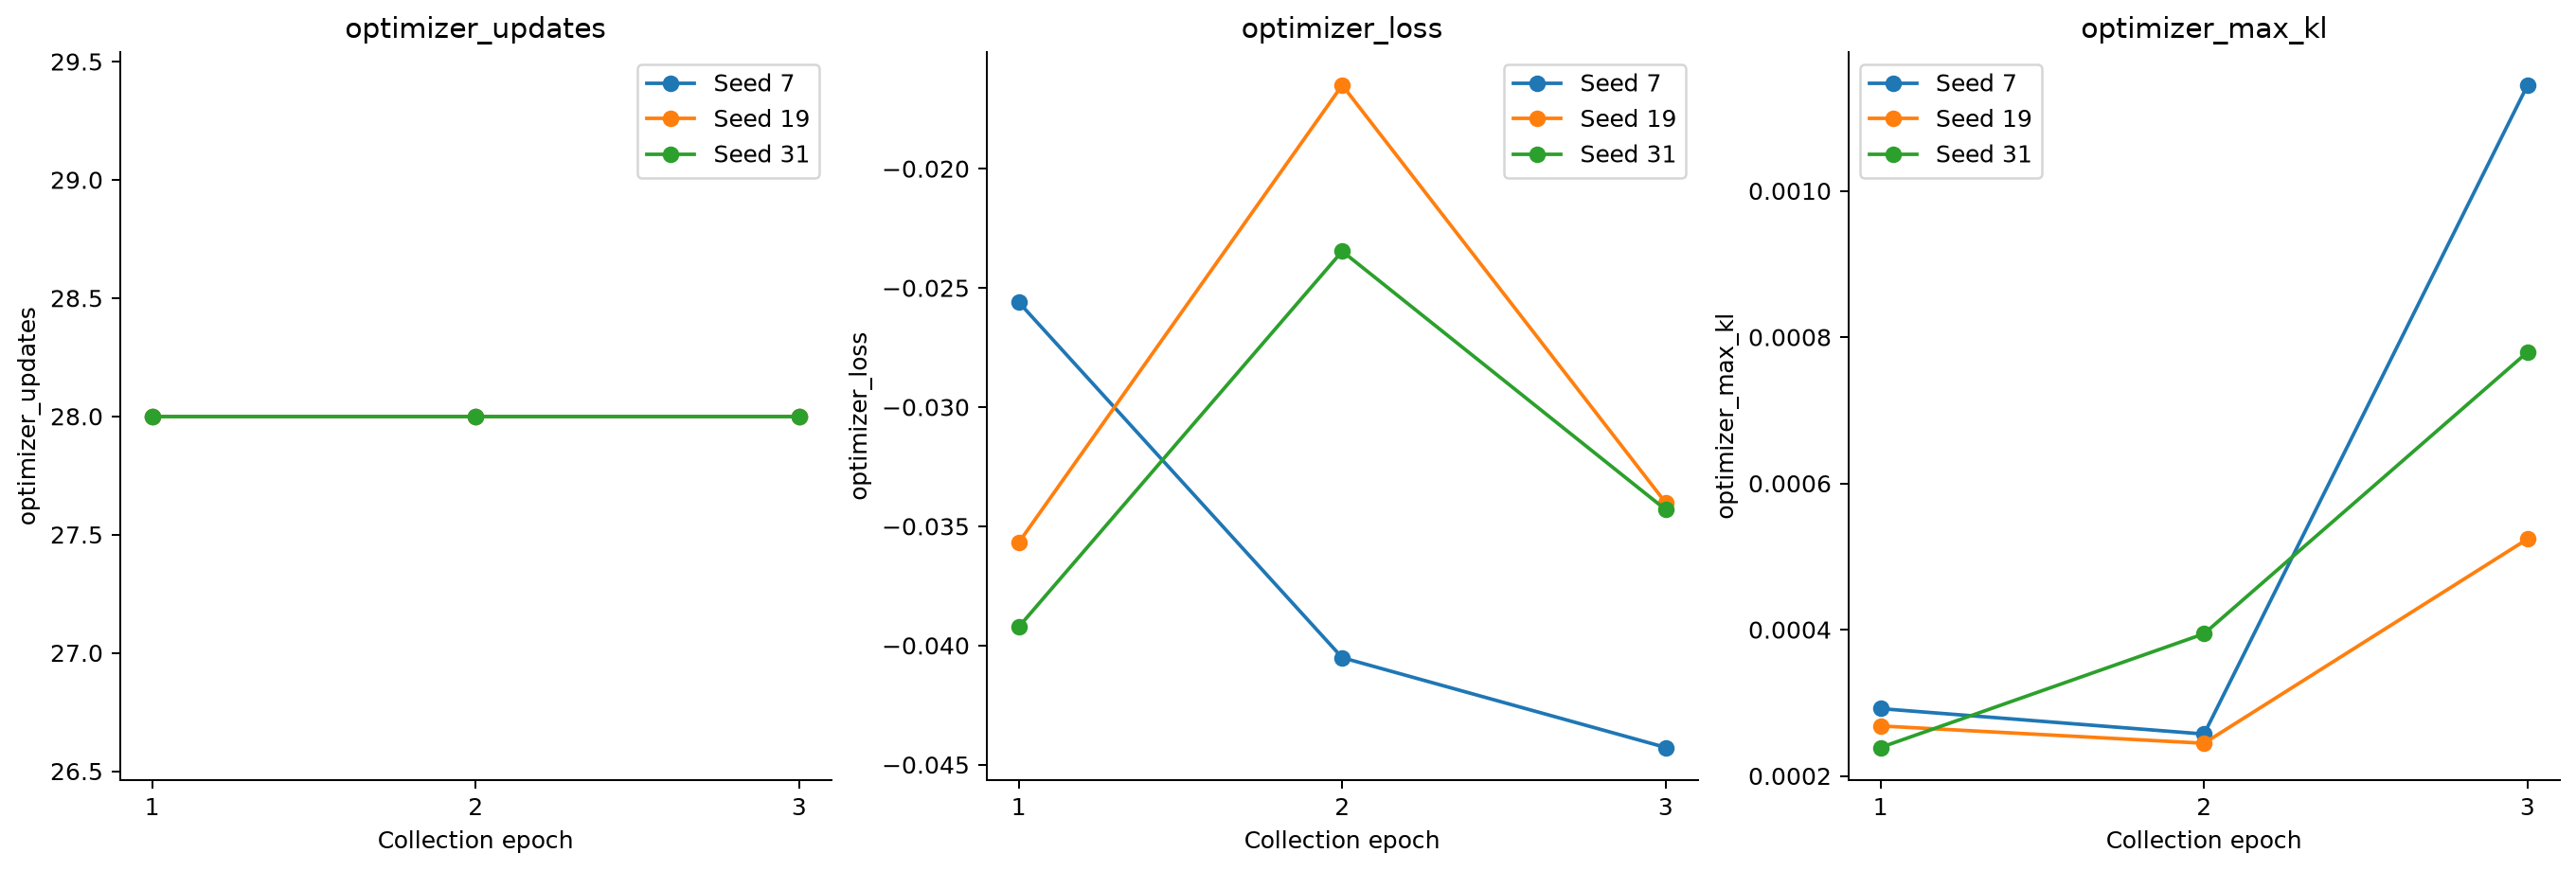

In [7]:
for path in sorted((REVIEW/'figures').glob('*.png')):
    if not path.name.startswith('metric_'):
        display(Markdown('### '+path.stem.replace('_',' ')))
        display(Image(filename=str(path),width=1100))

## Individual scalar-metric figures

These include evidence-label coverage, supporting/joint-label F1/EM, calls, token usage, refusals, invalid citations, cache reads, availability and abstention rates. Token plots use observed counts only; see missing-n columns.

### metric all support available

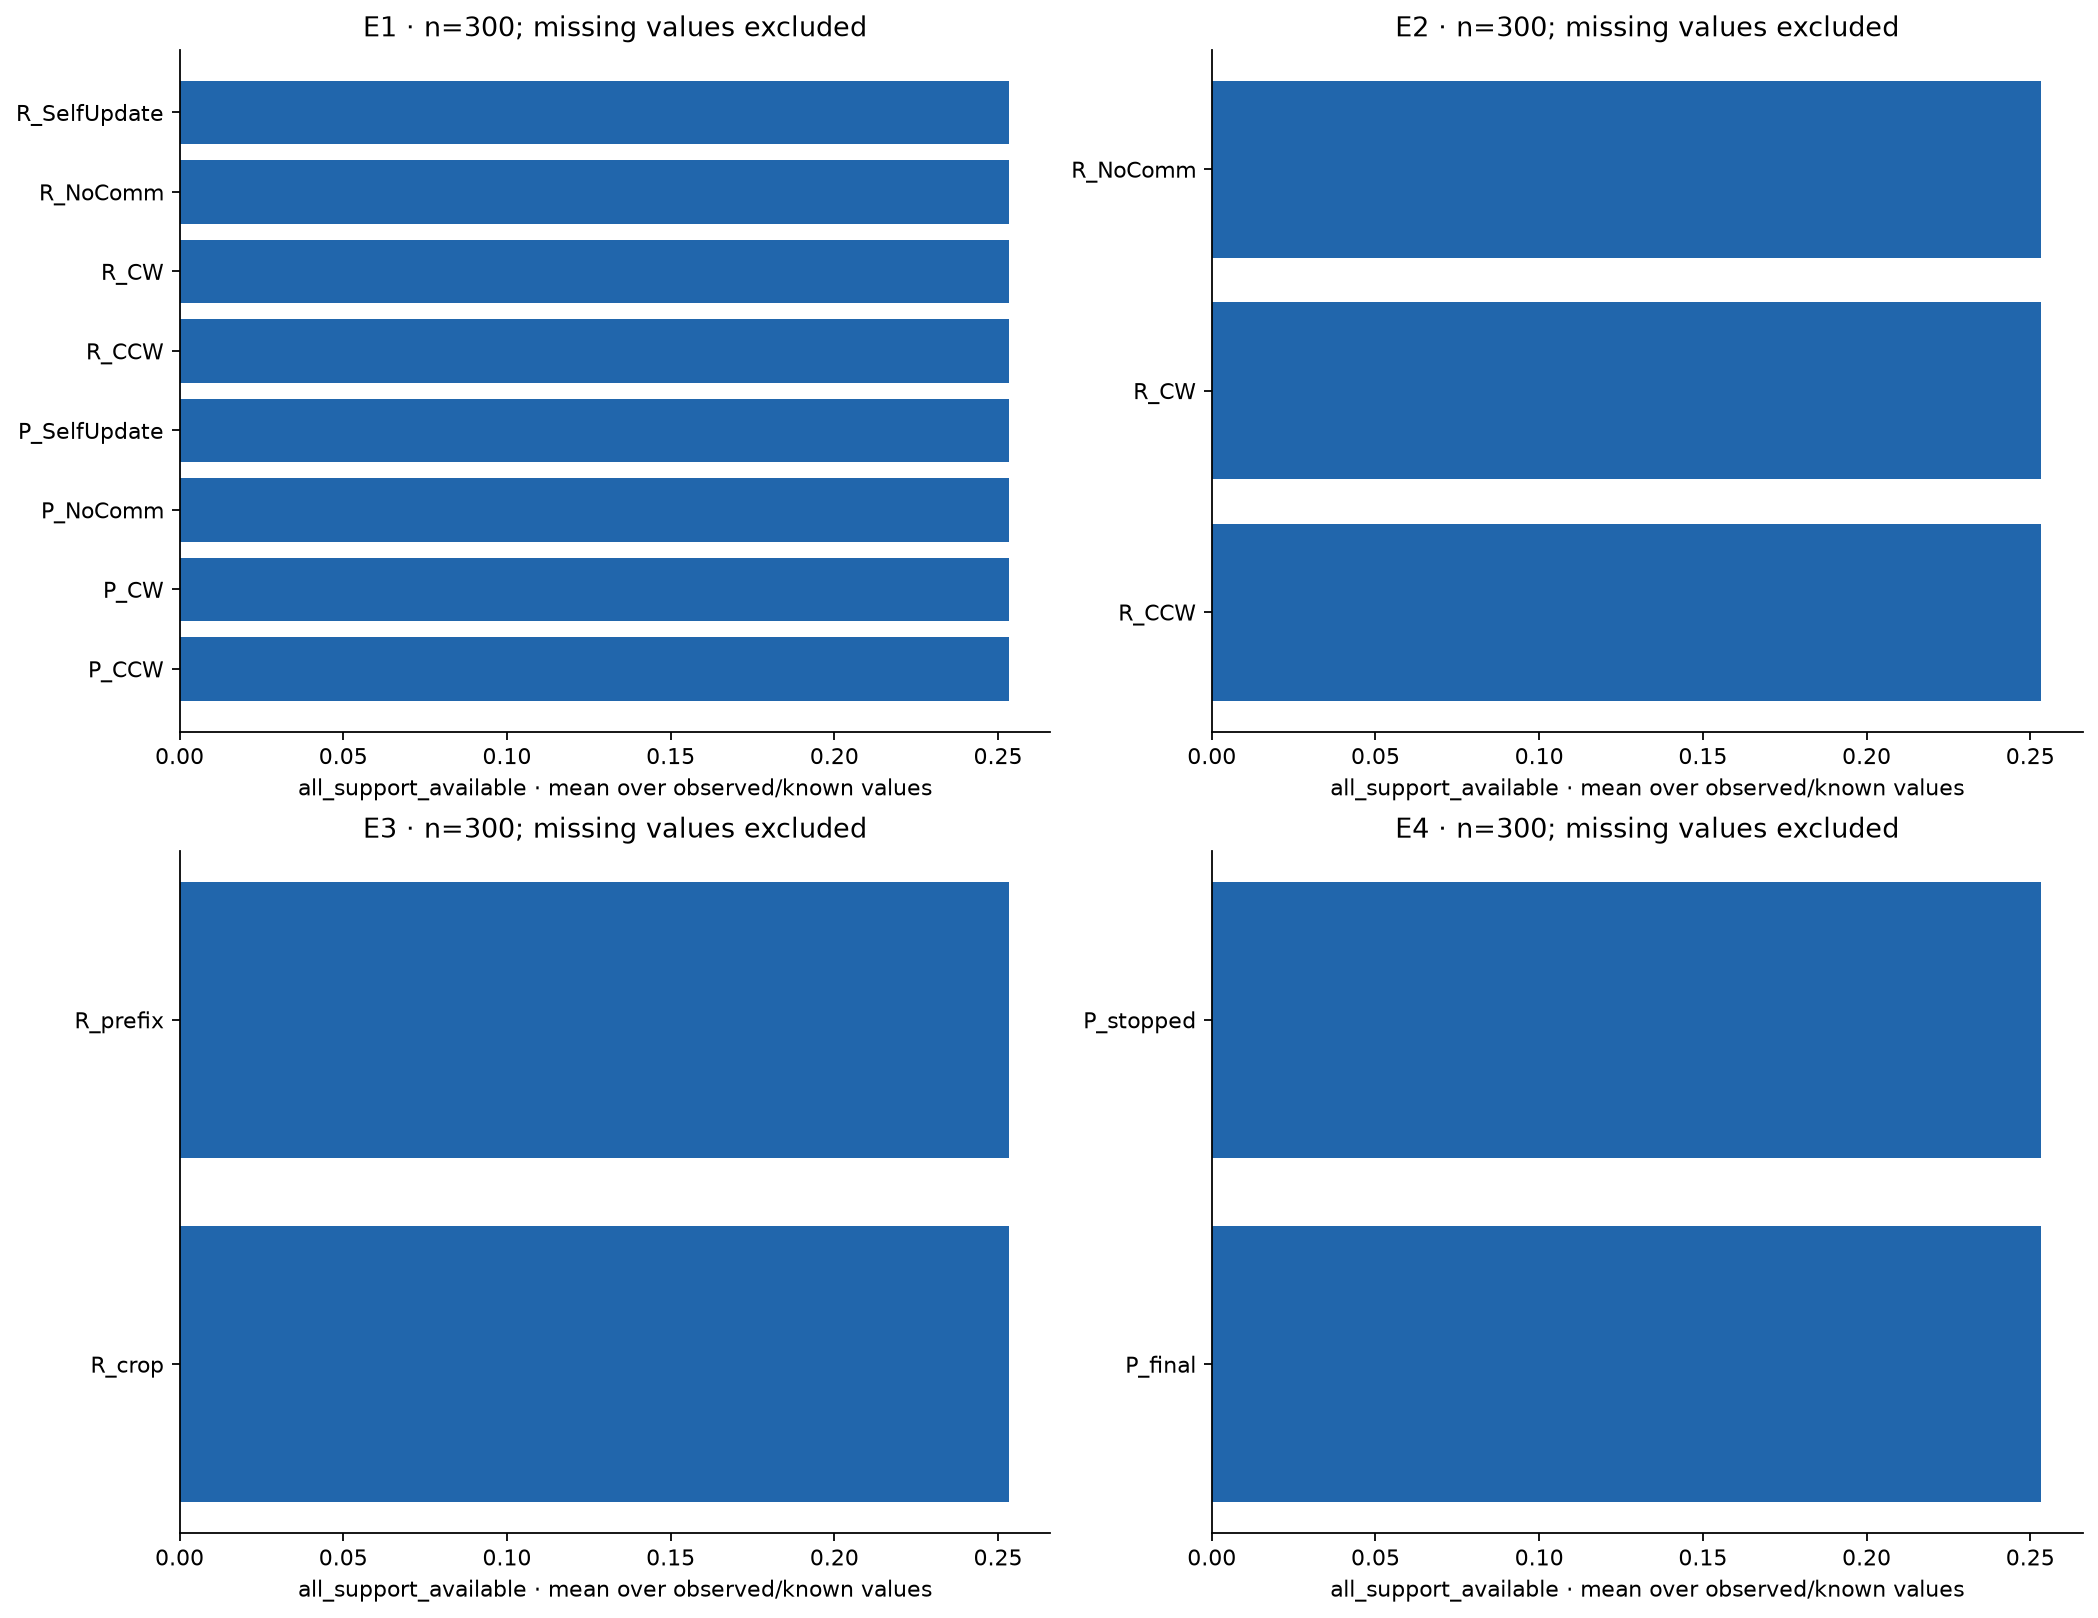

### metric answer support precision

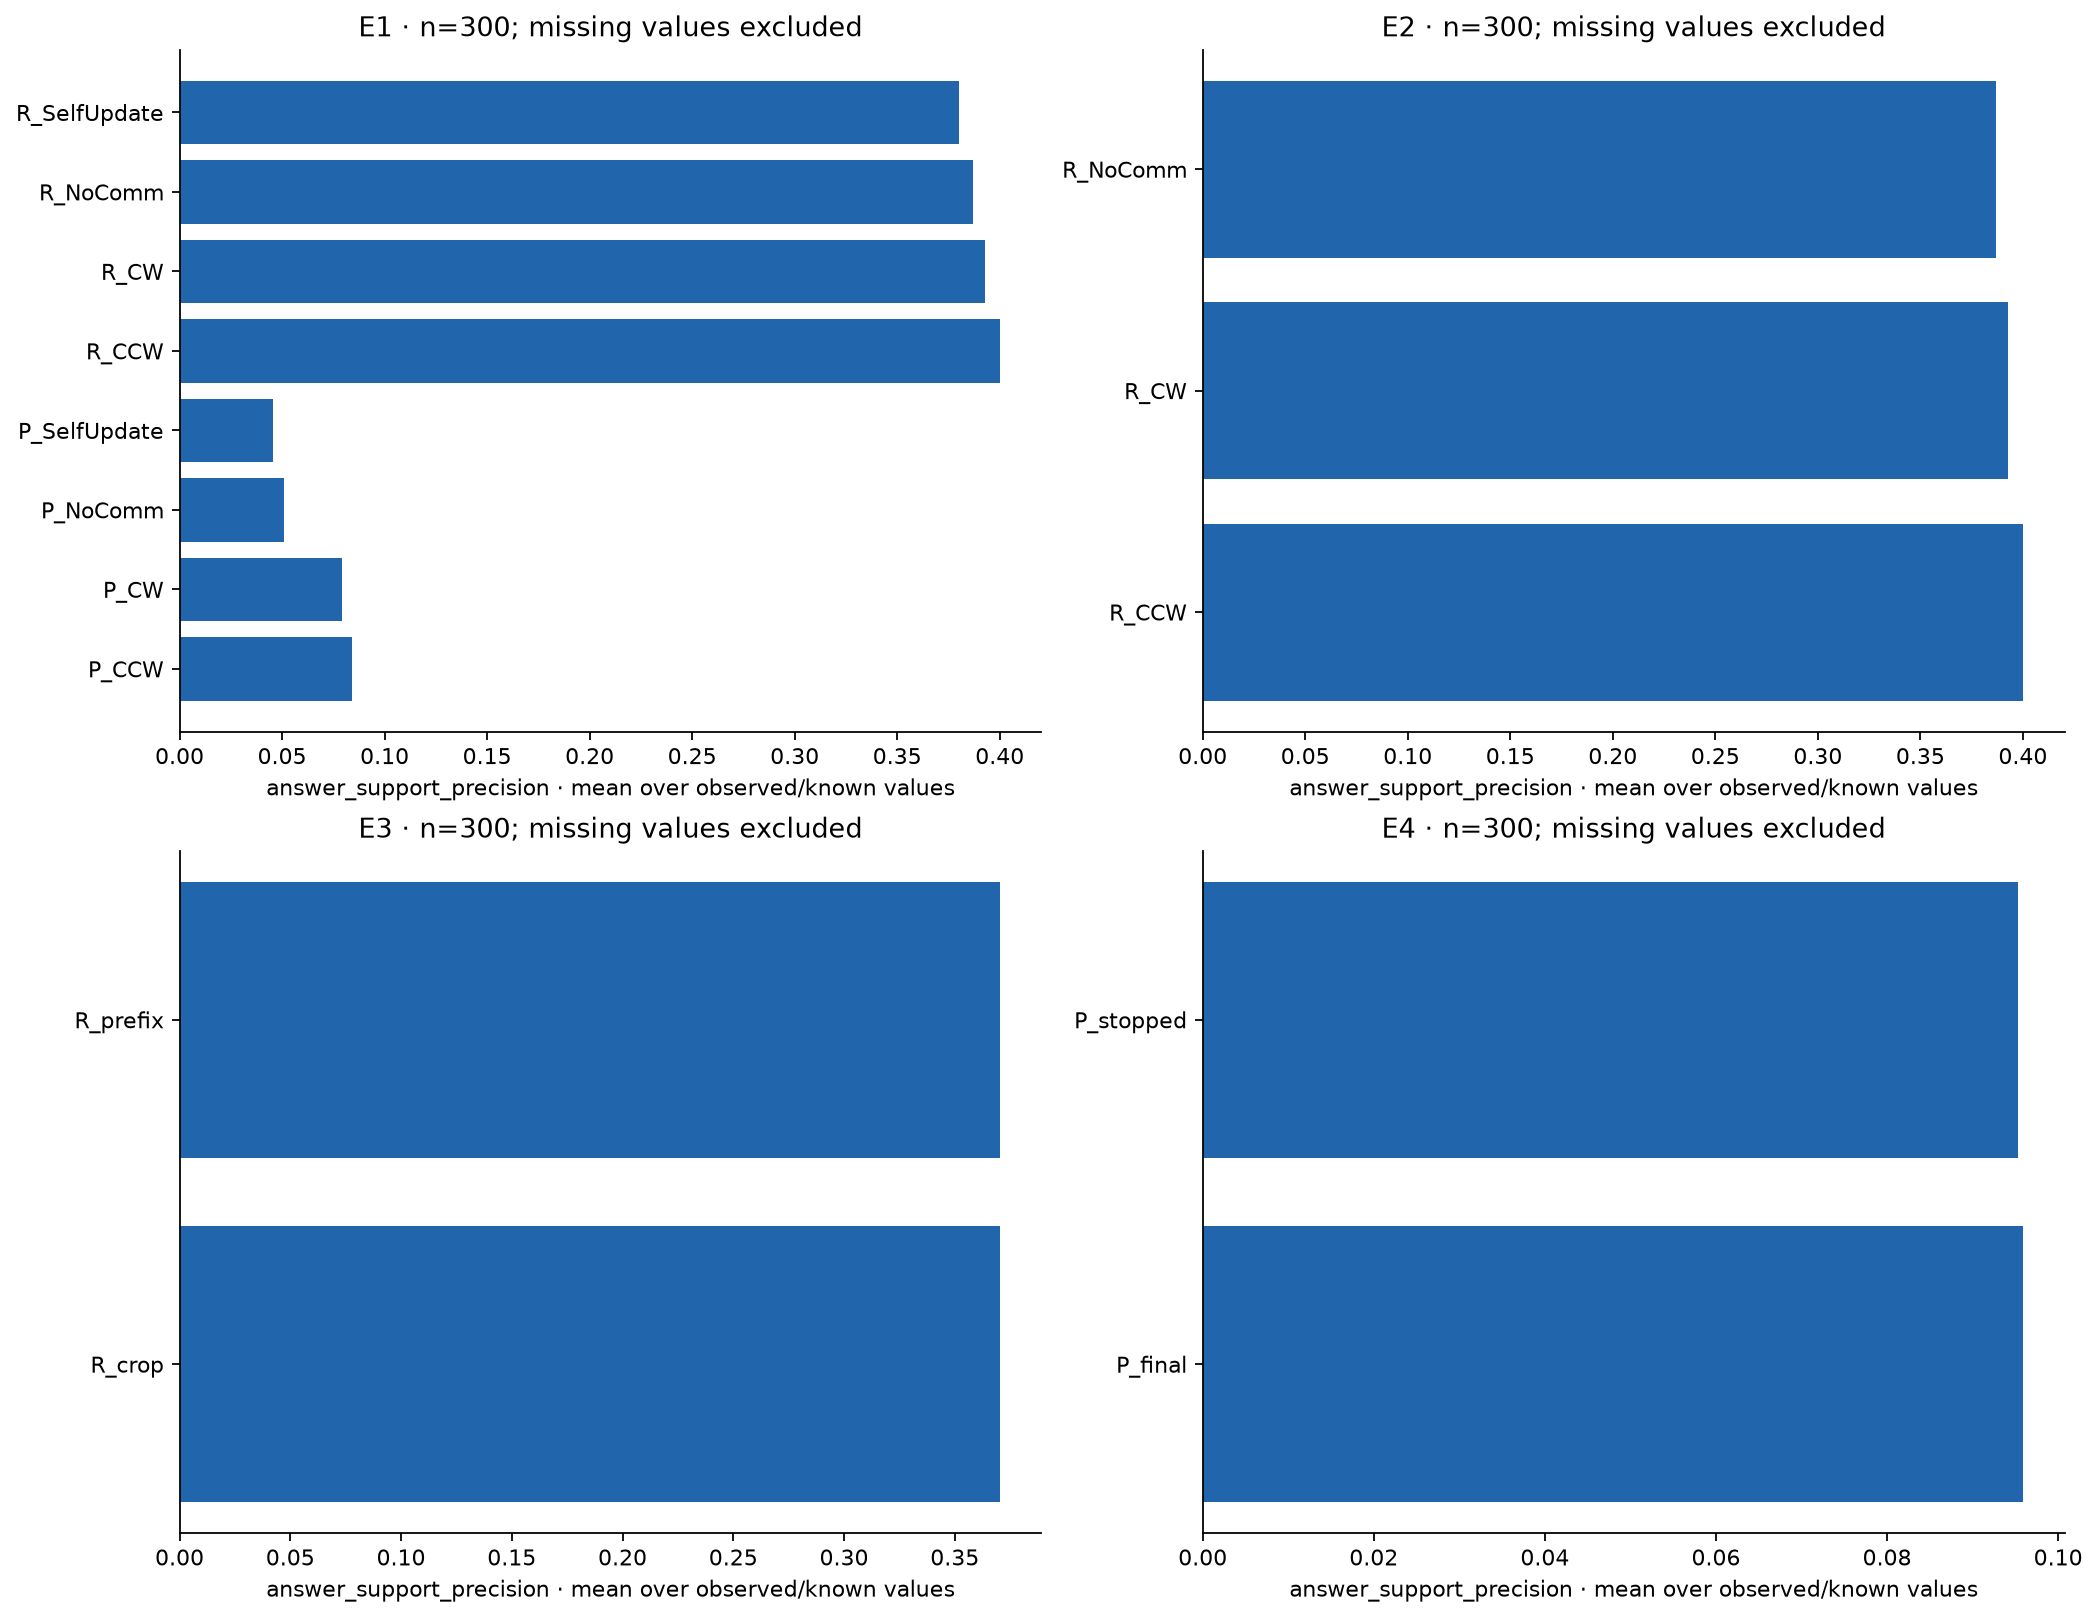

### metric answer support recall

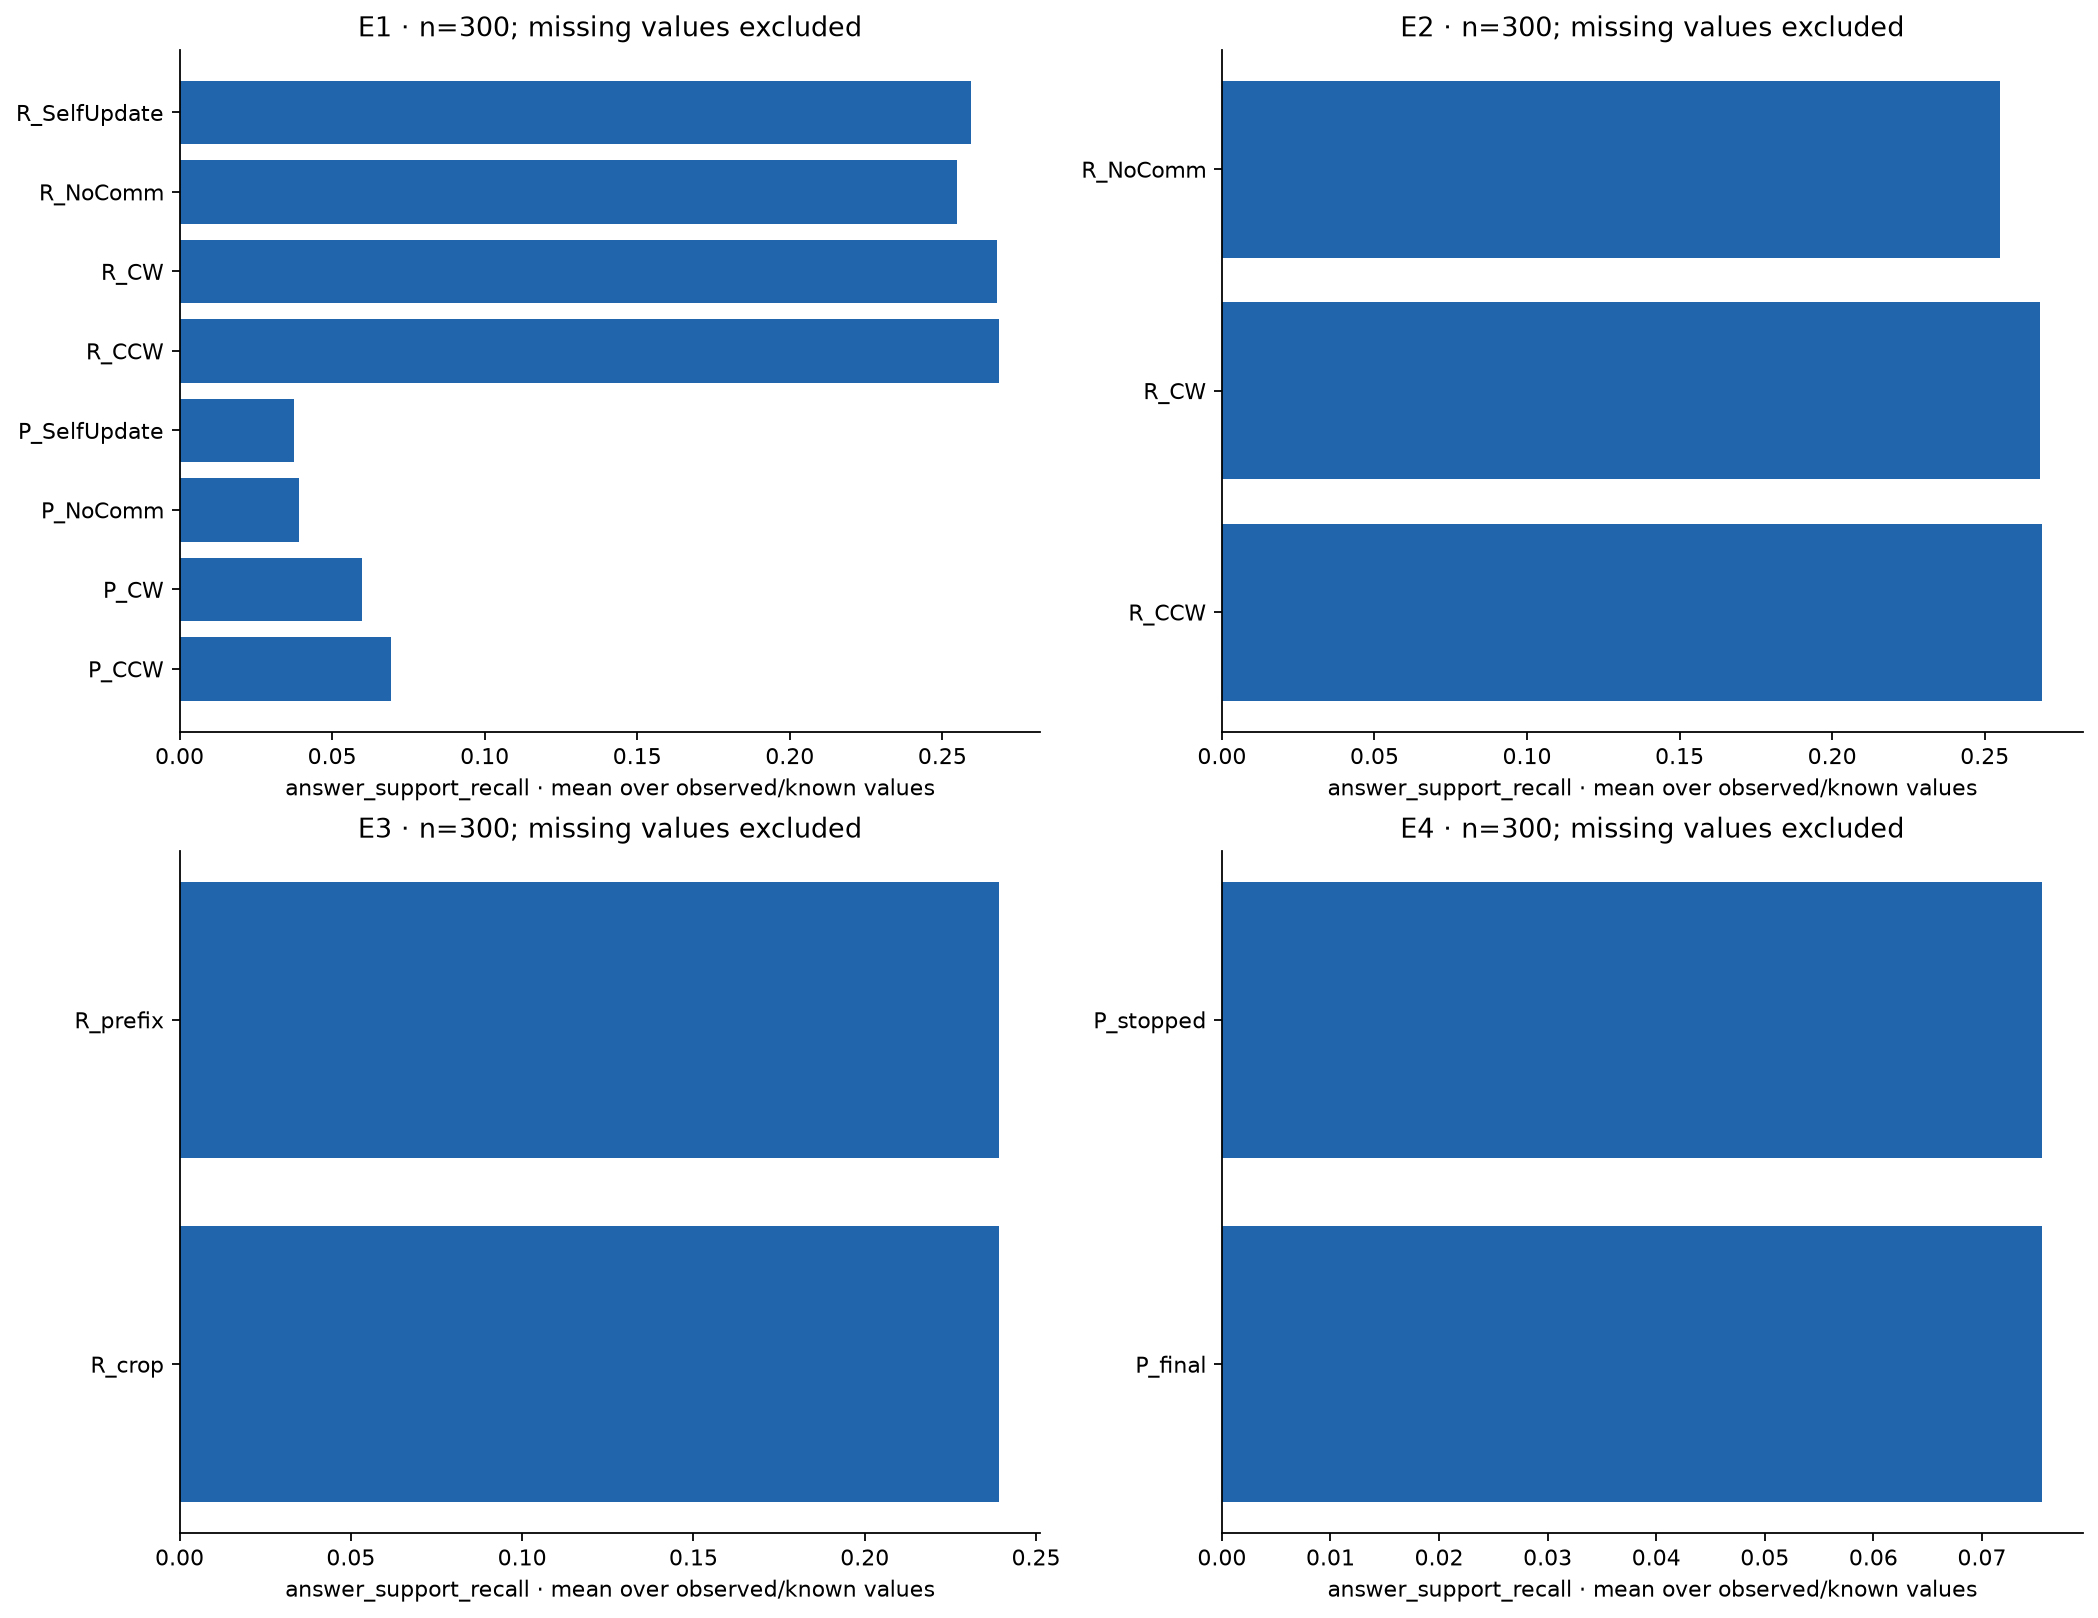

### metric cache reads this execution

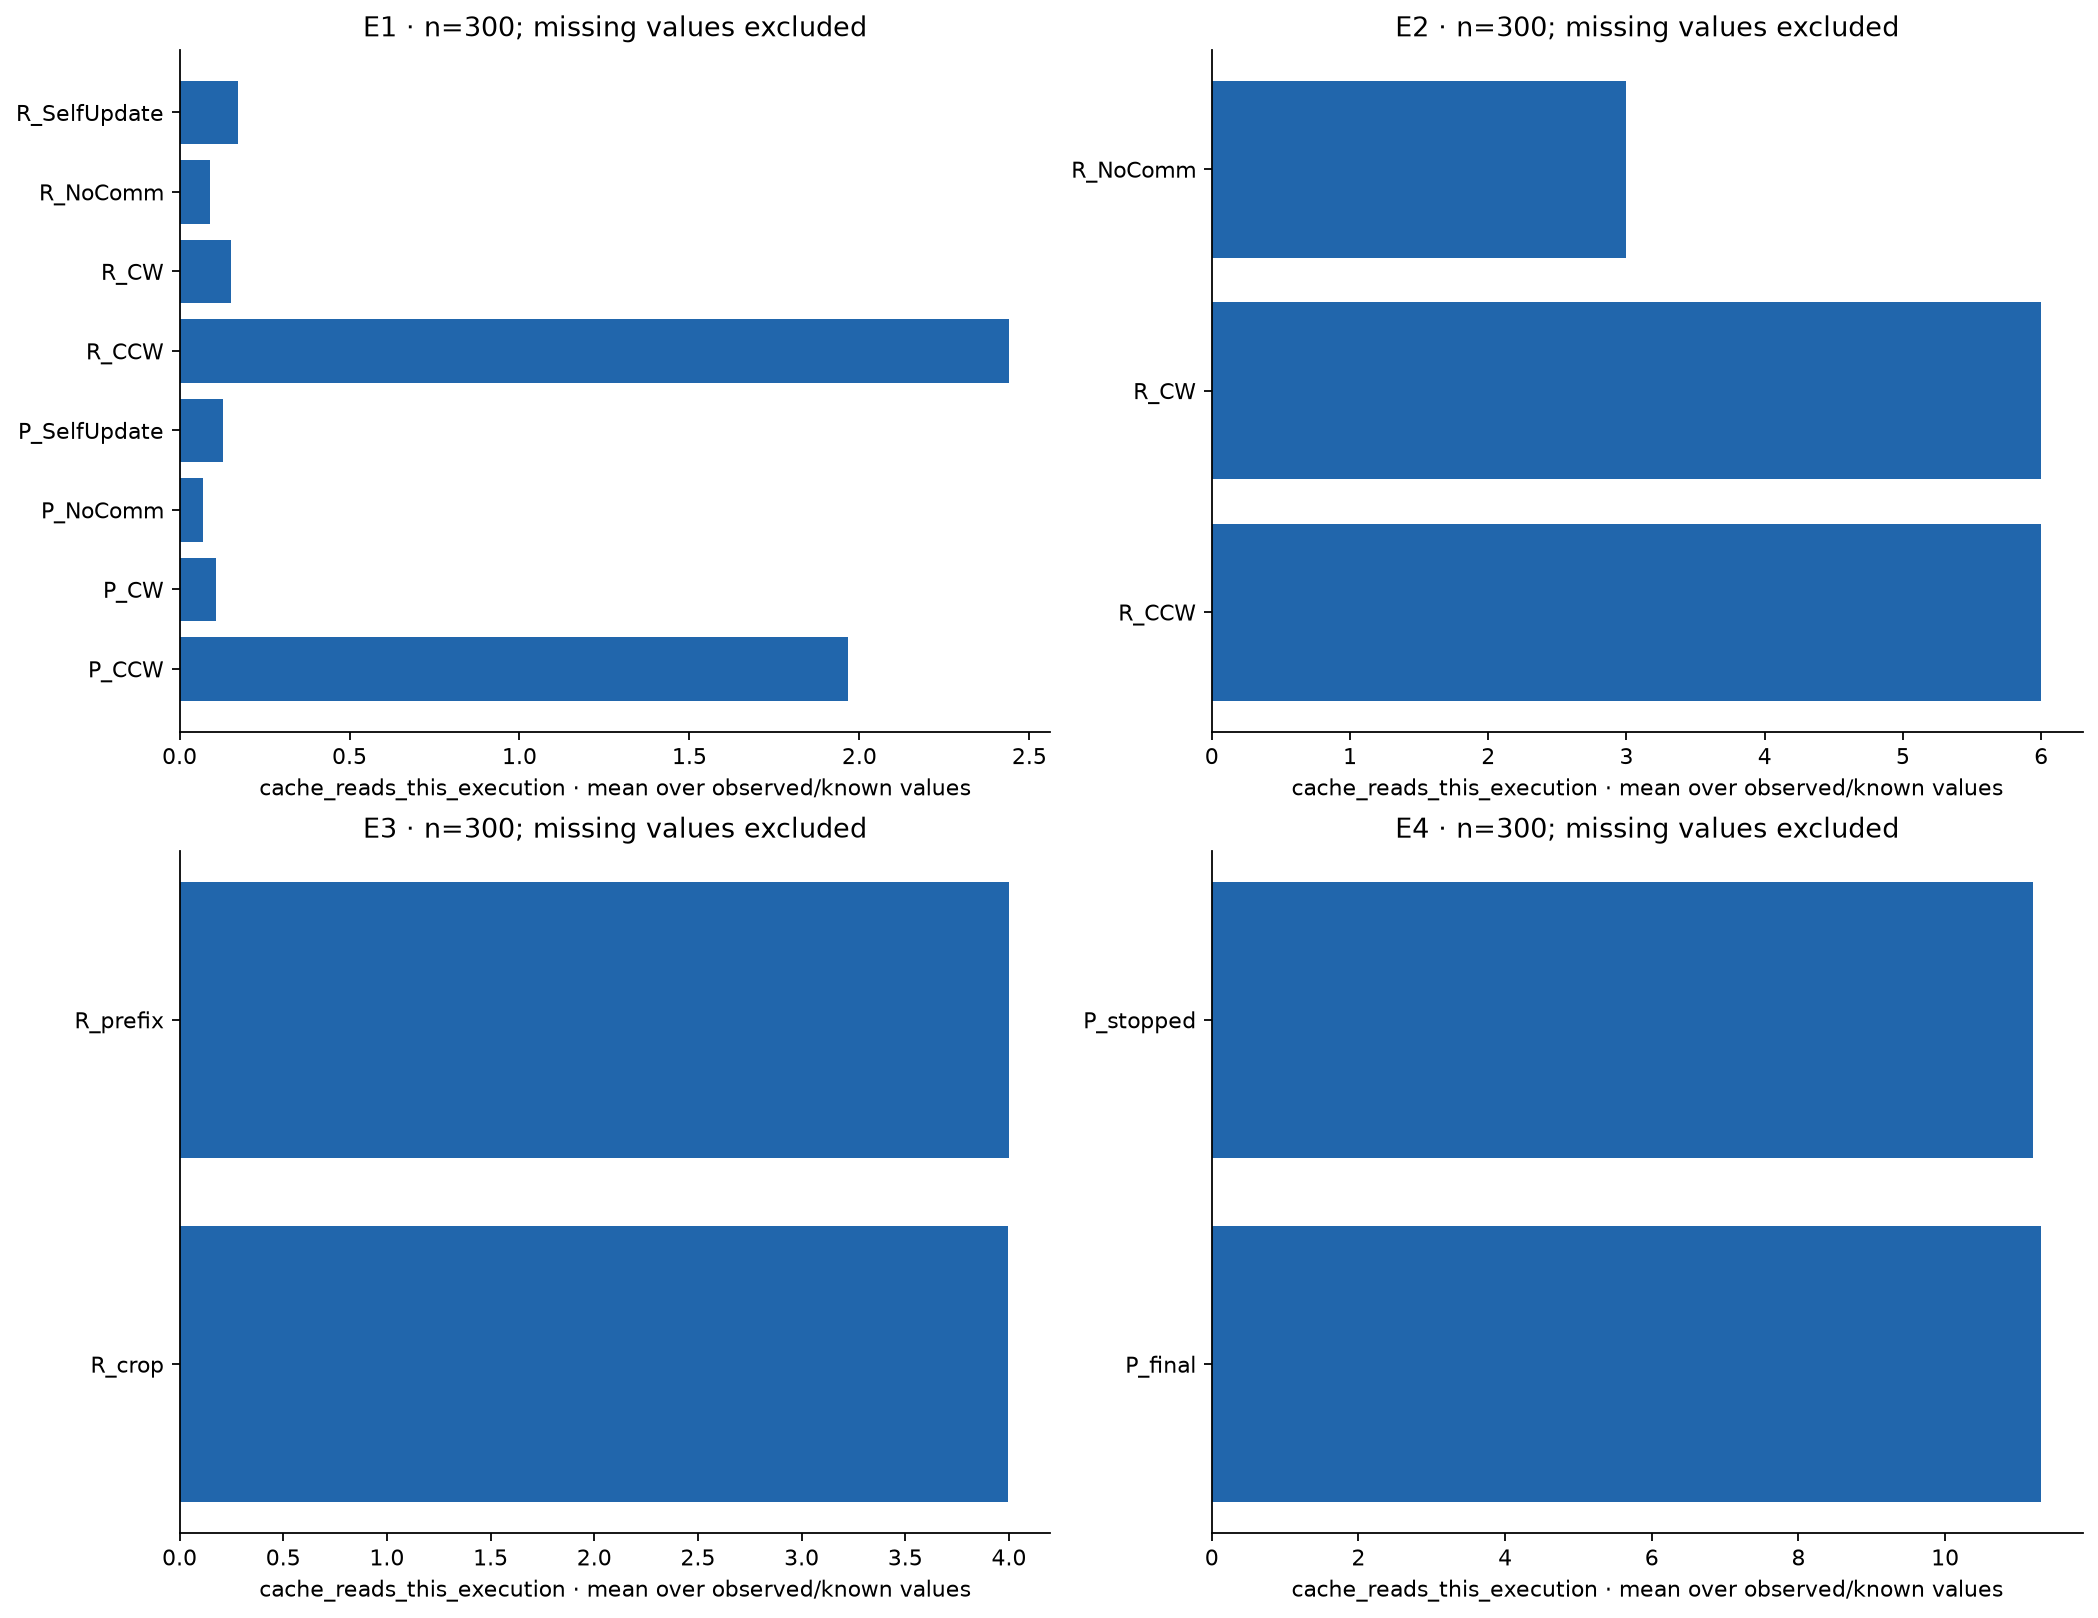

### metric explicit empty abstention

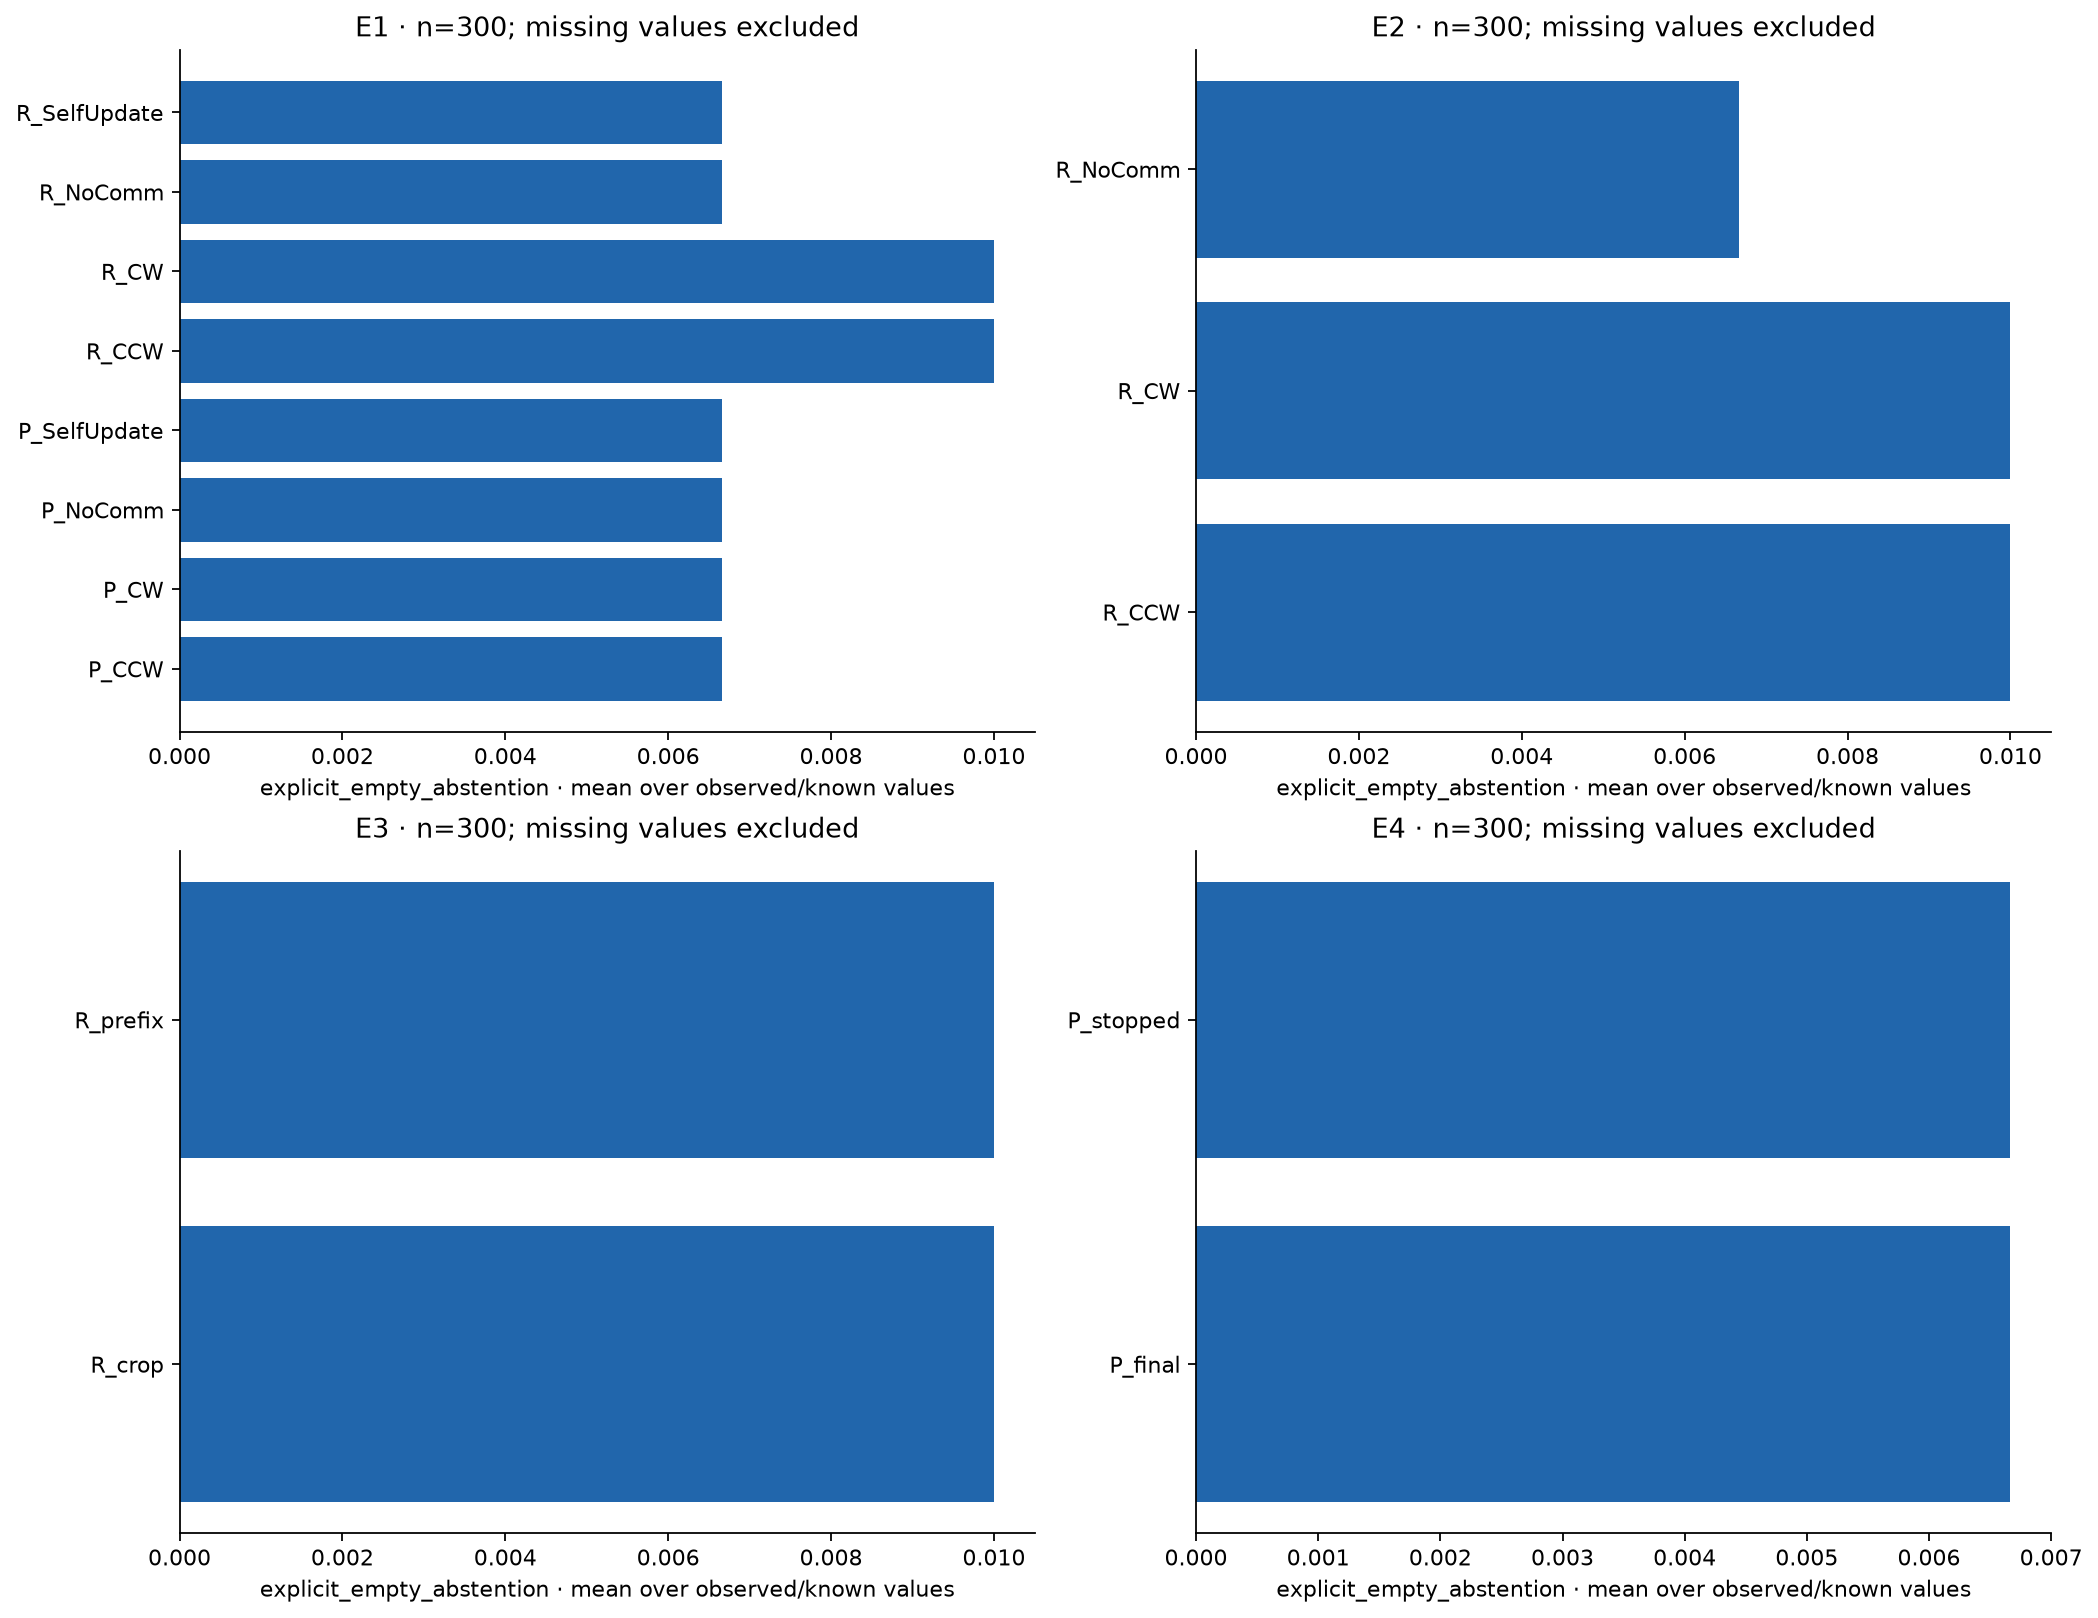

### metric input tokens

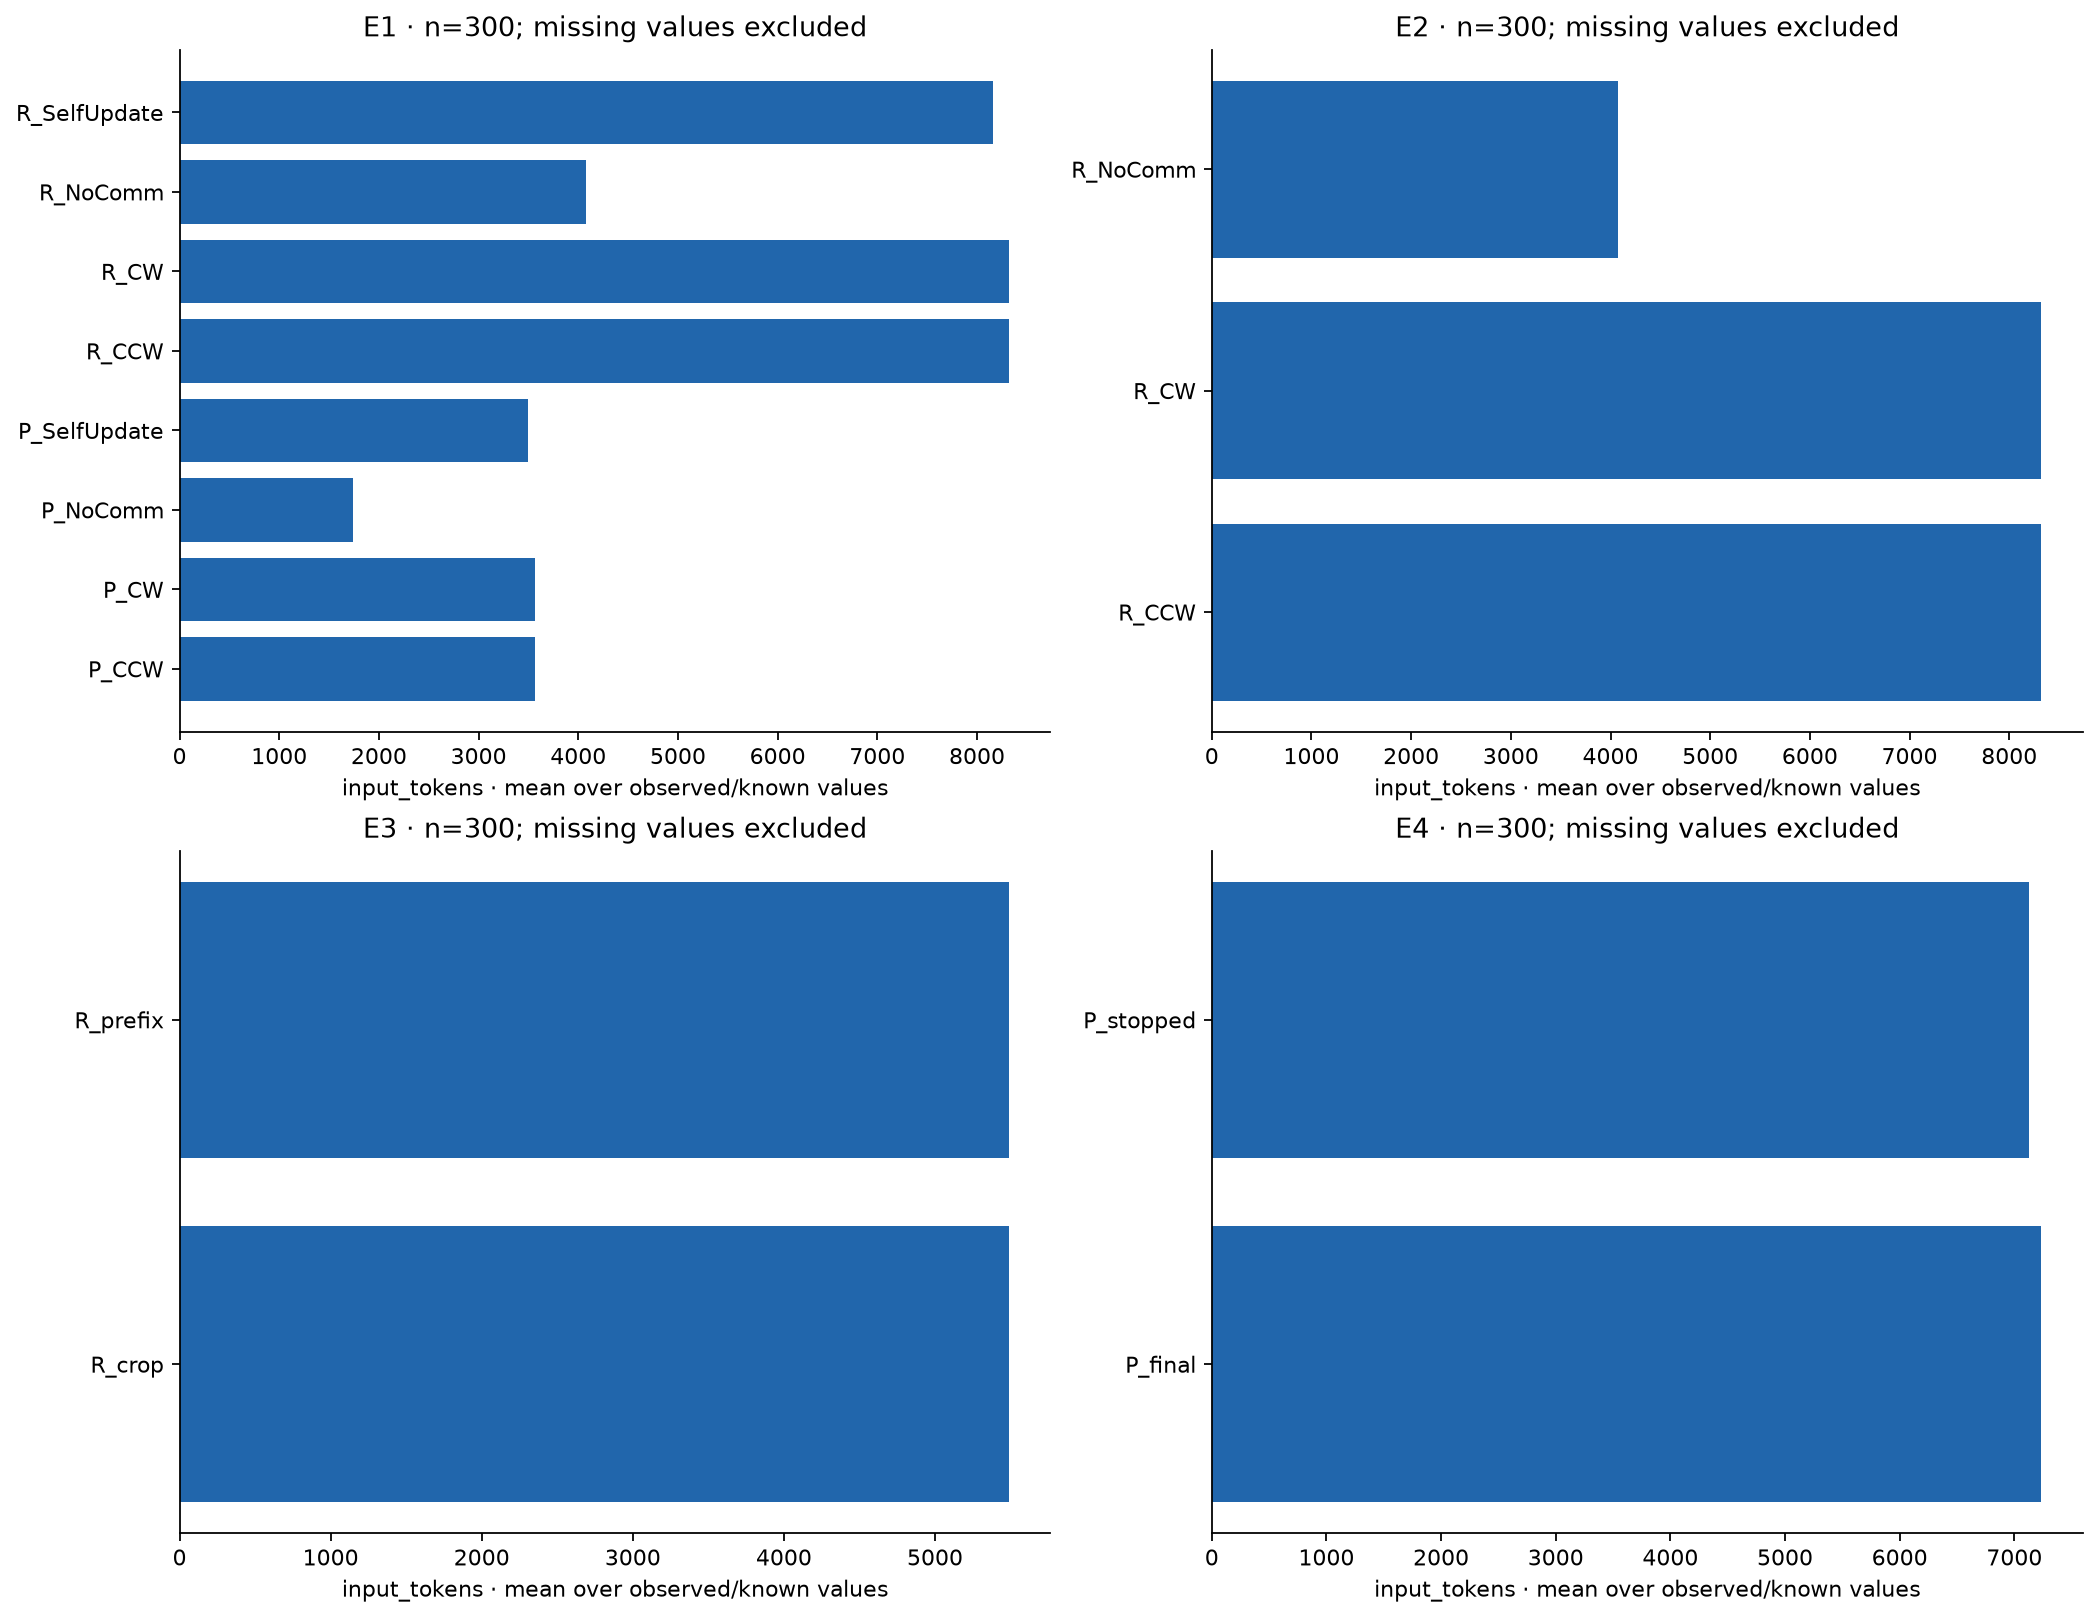

### metric invalid citation count

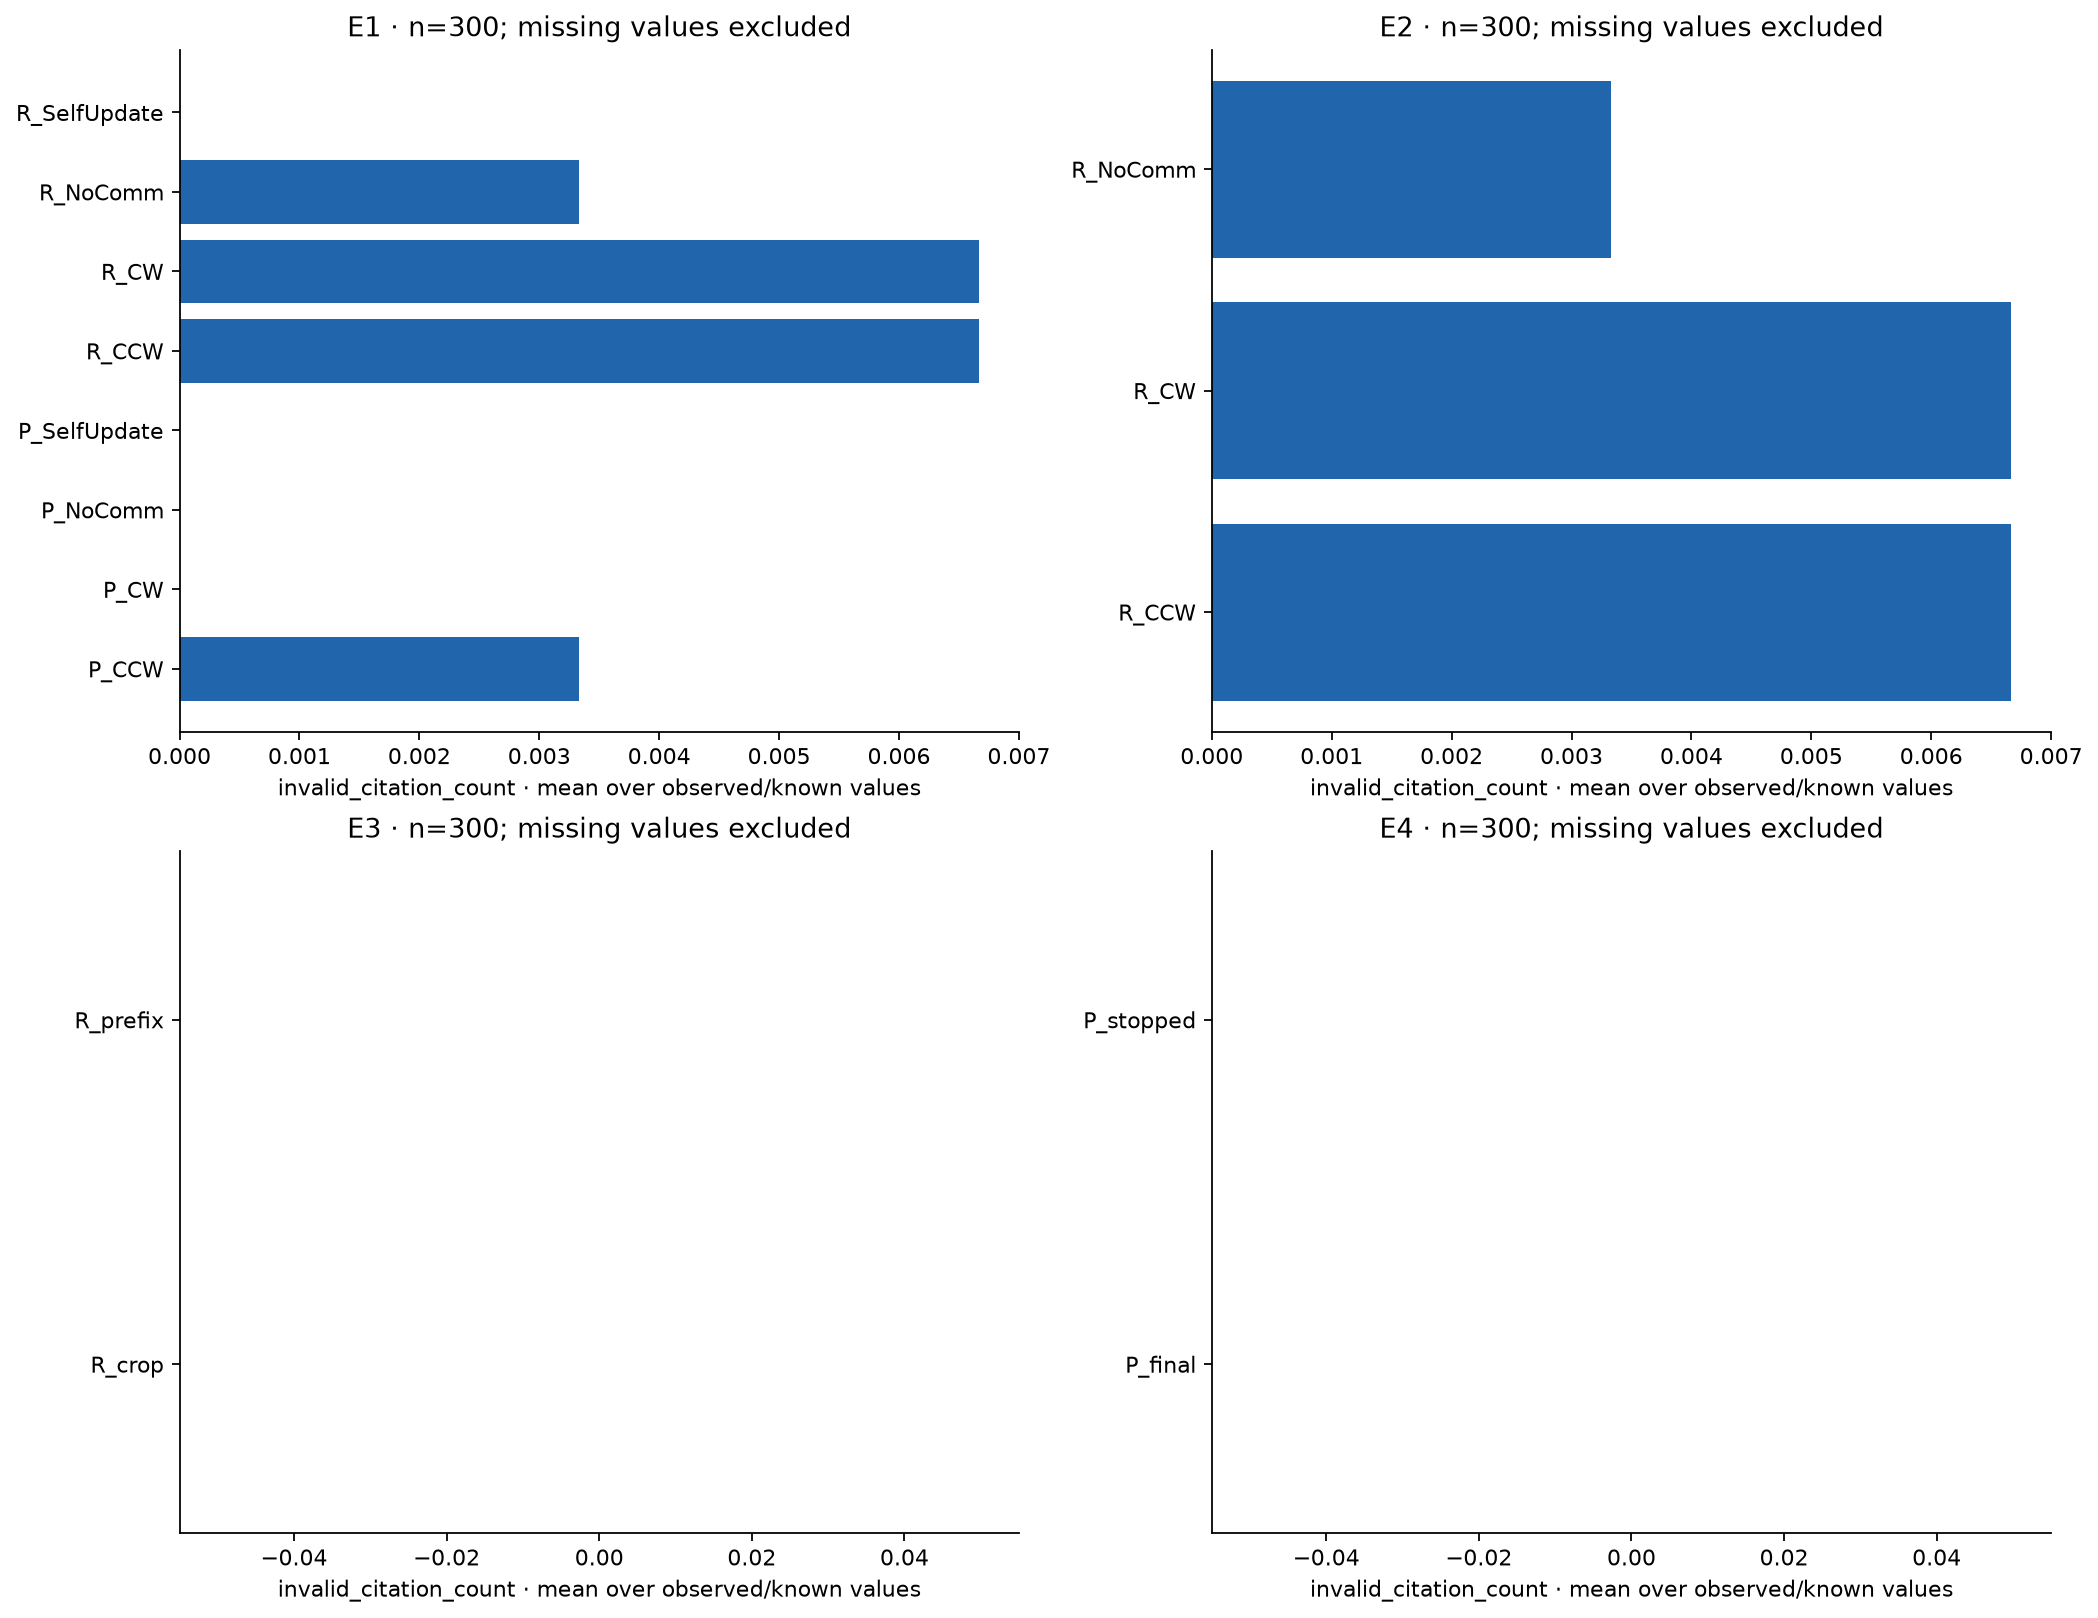

### metric label joint em

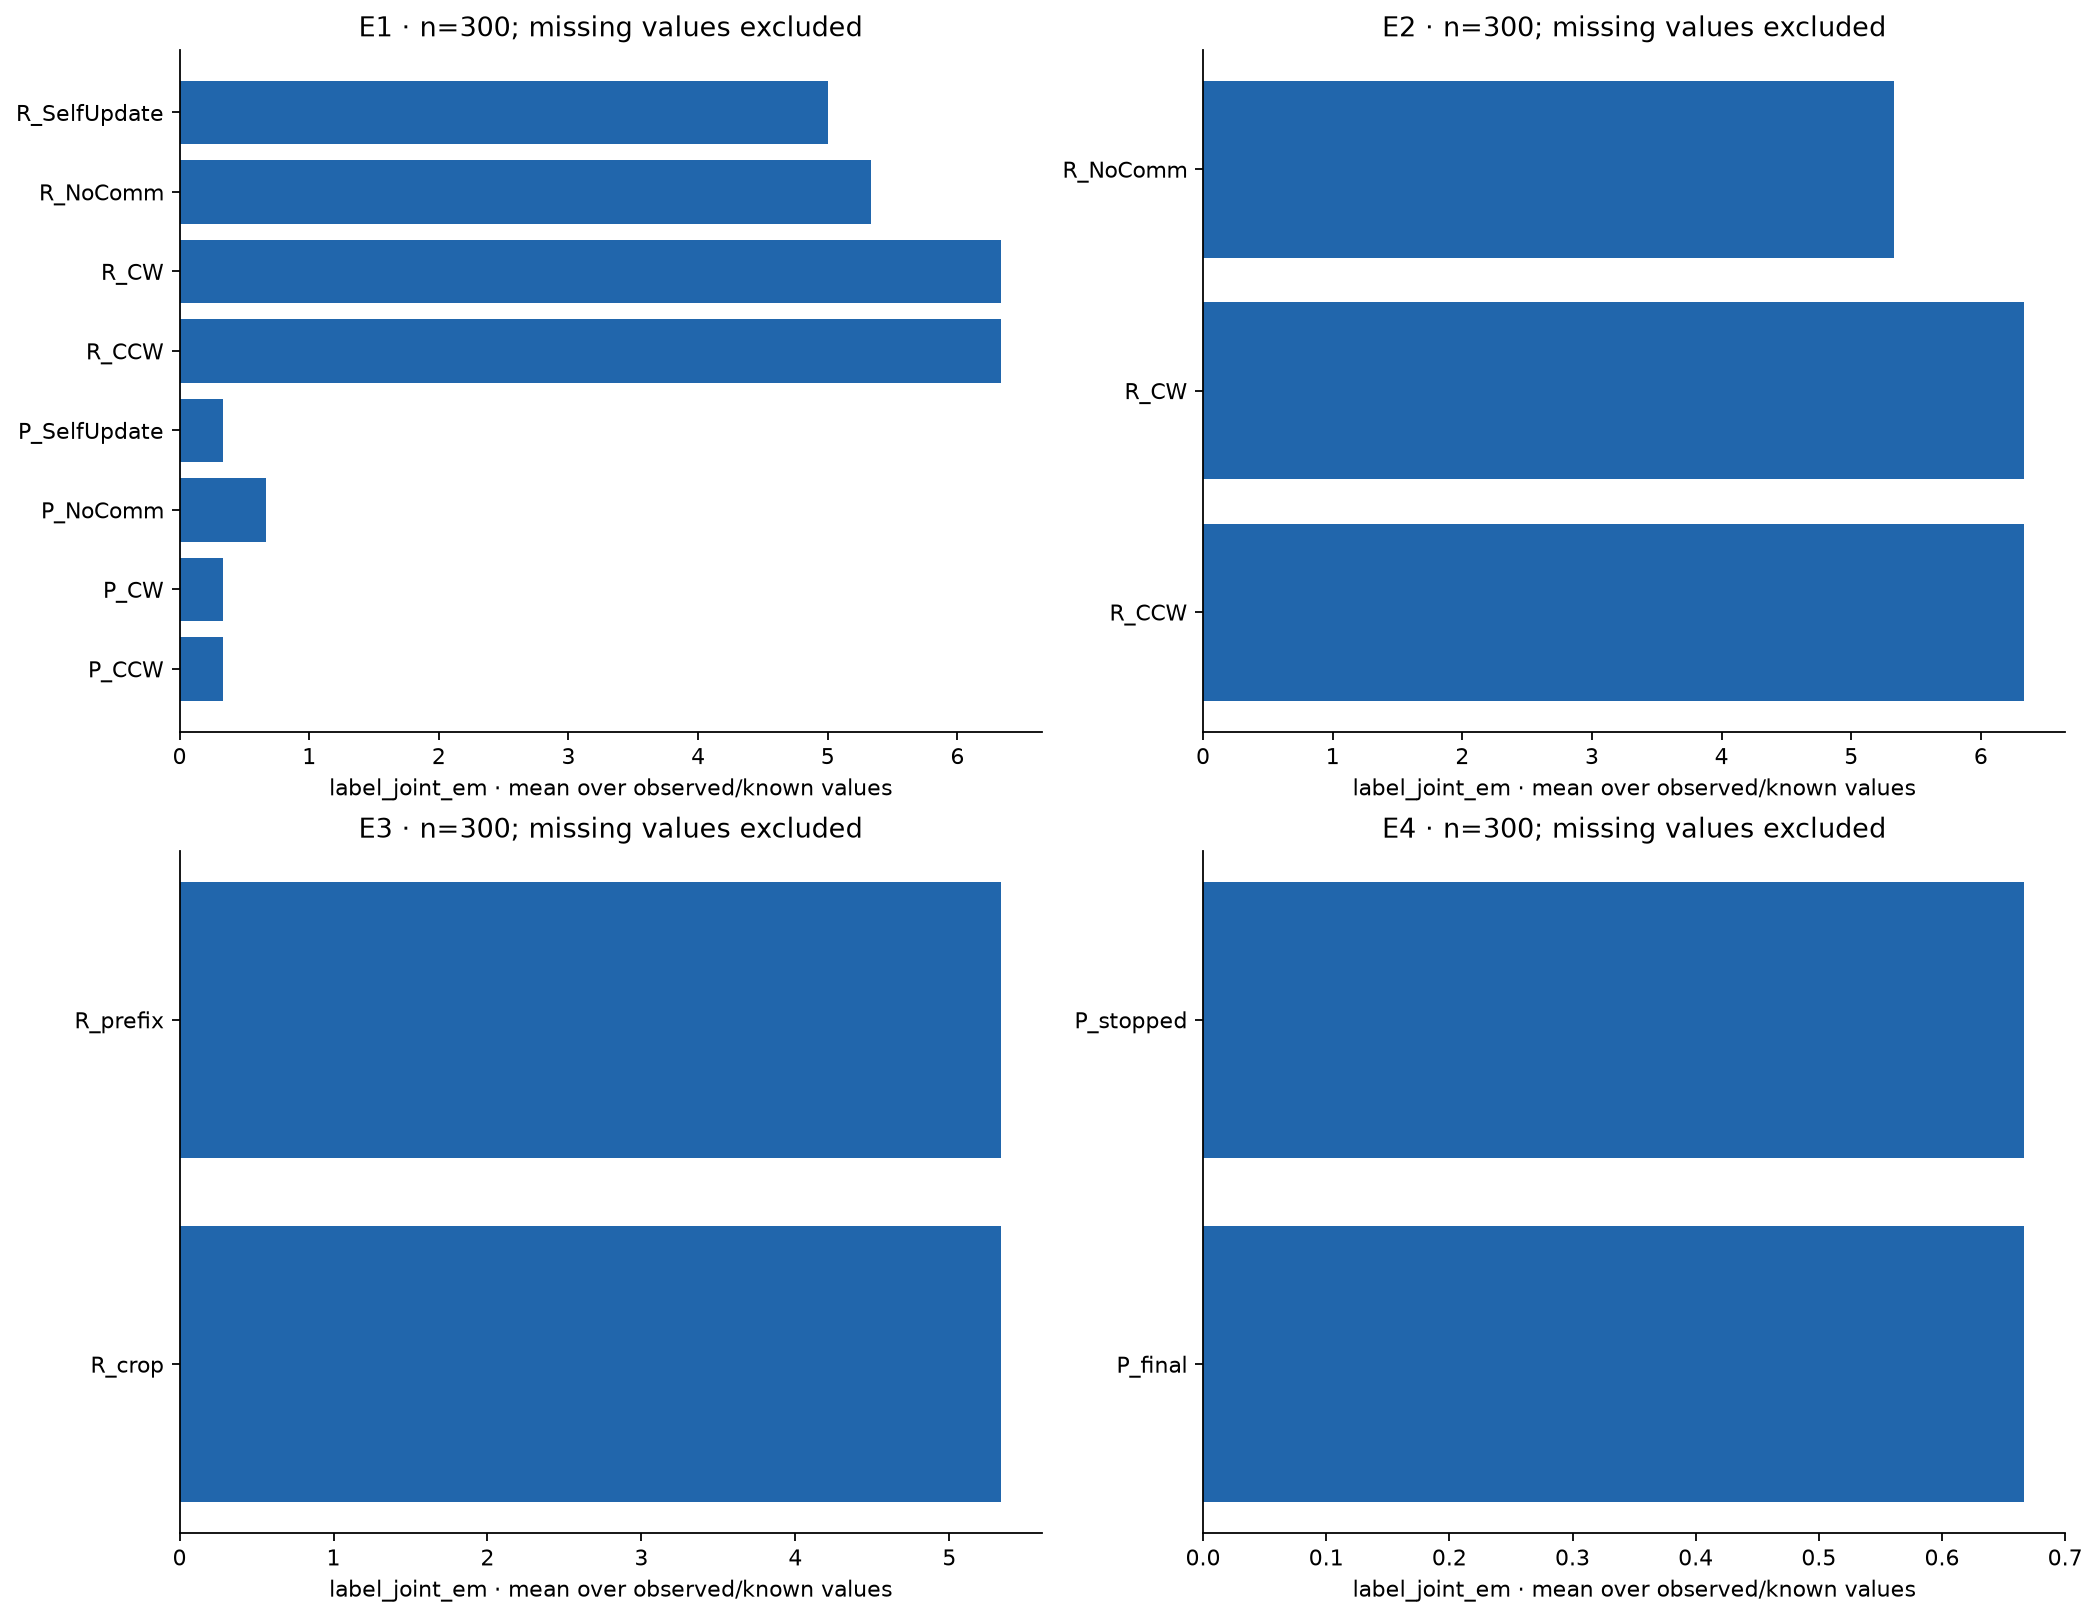

### metric label joint f1

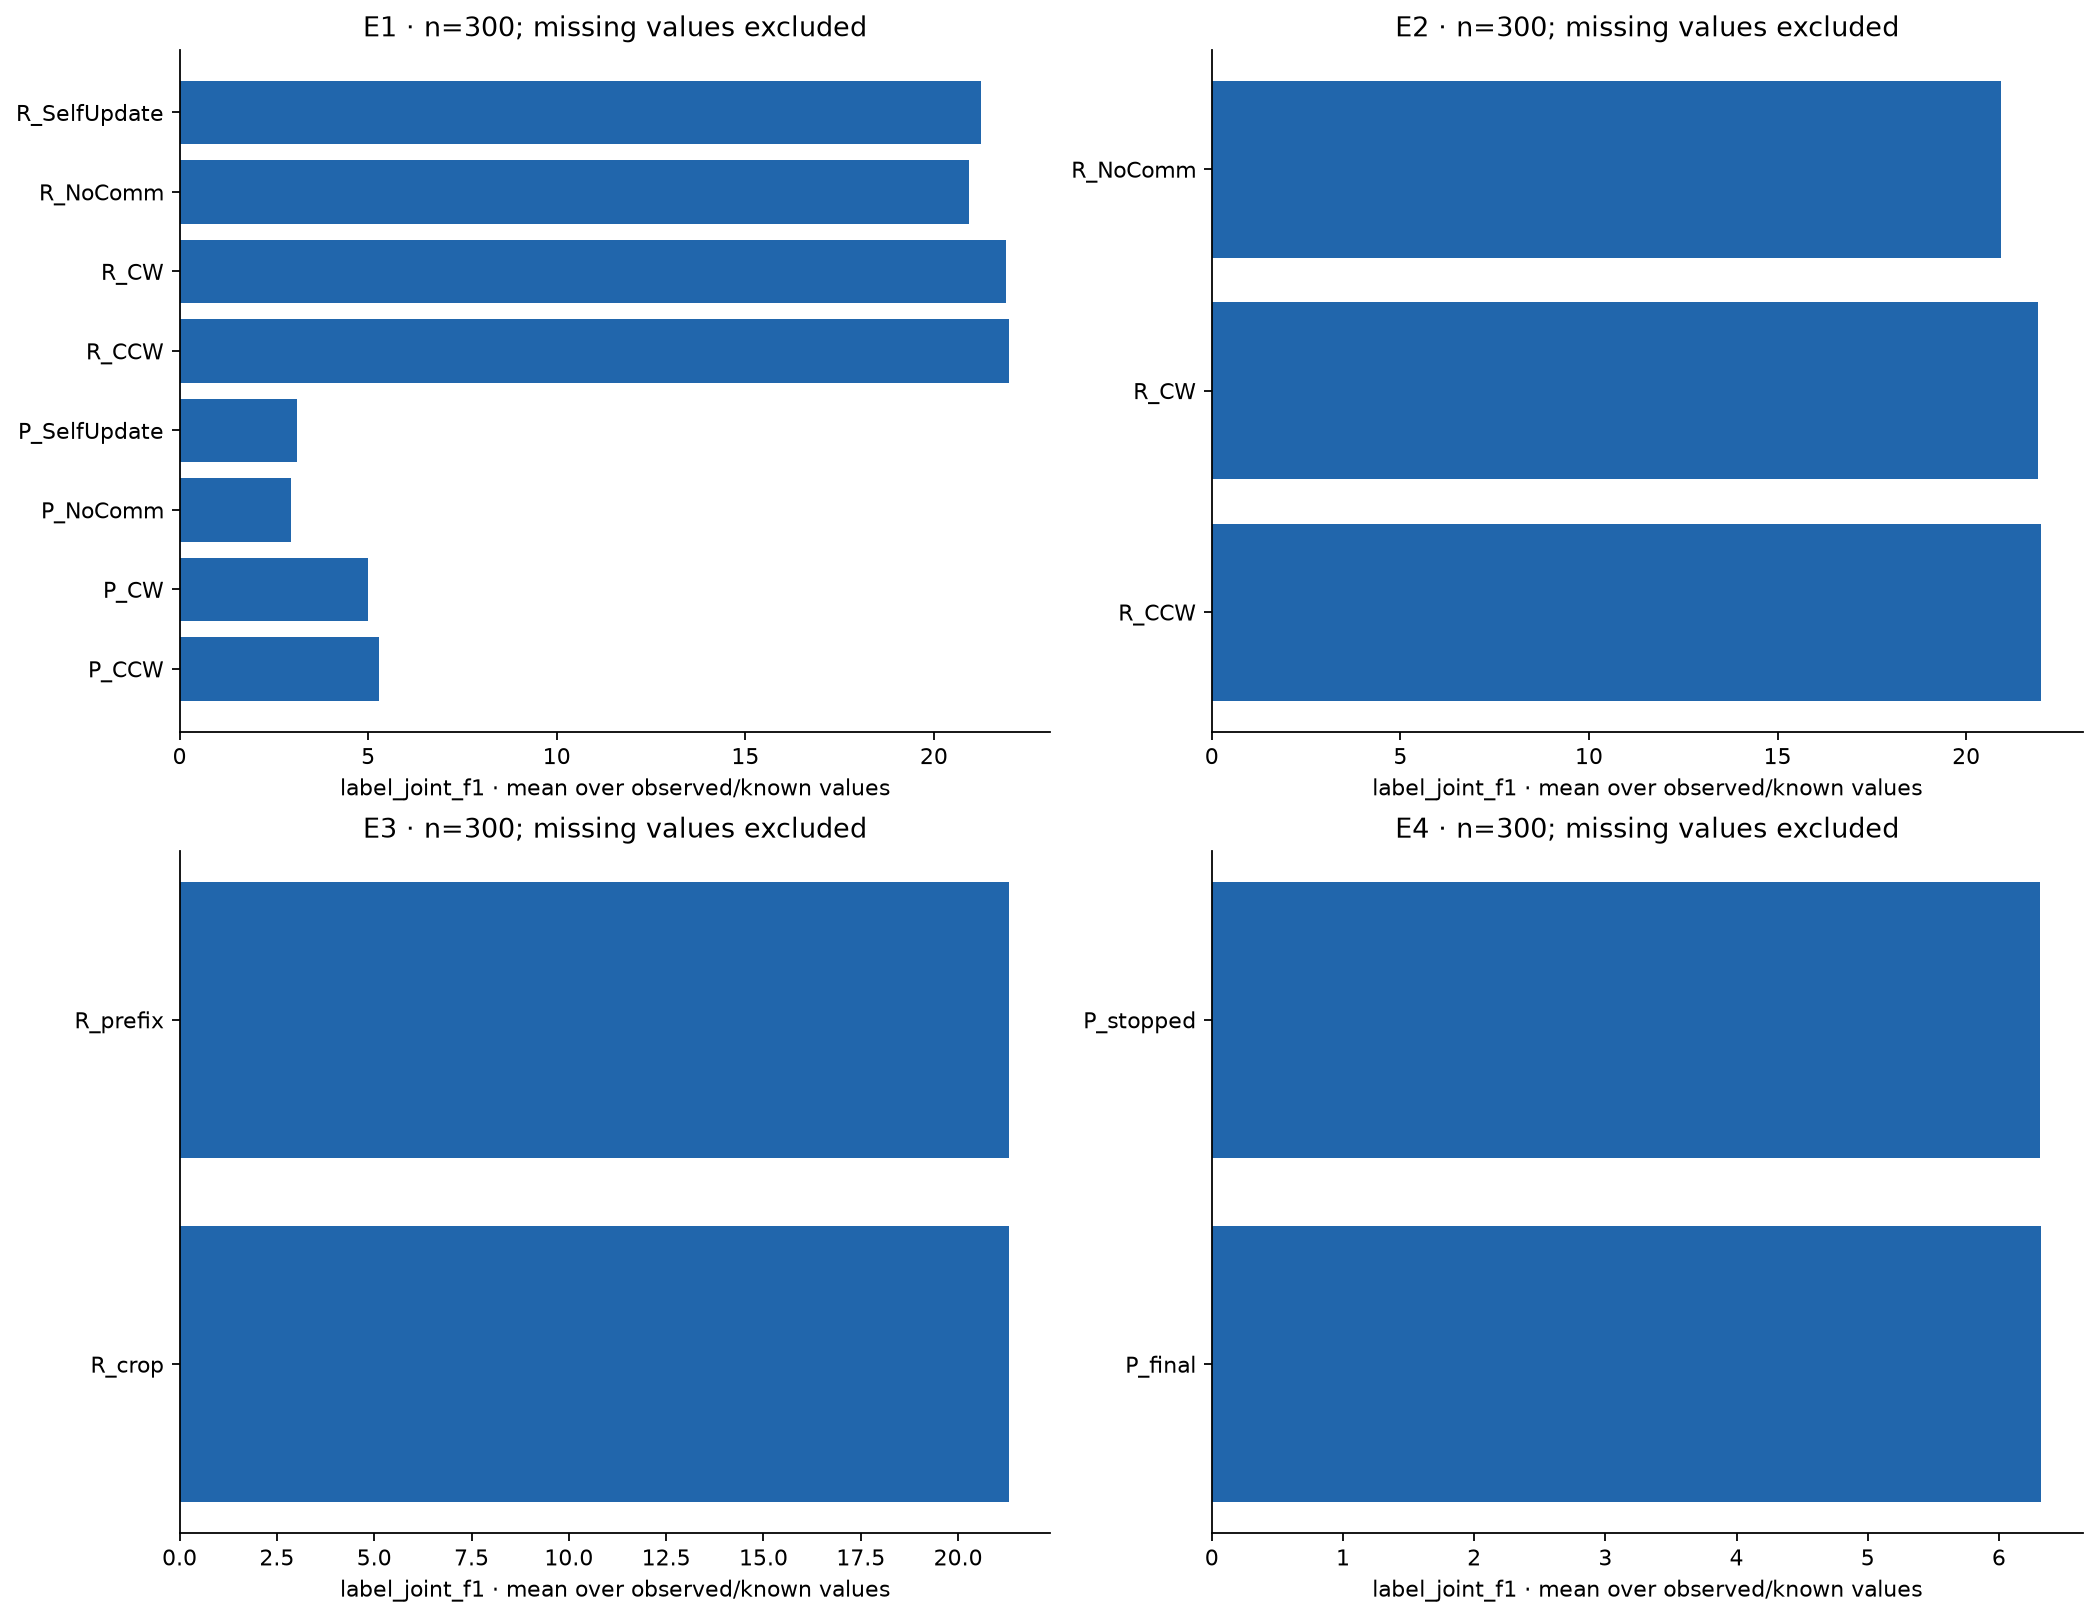

### metric logical calls

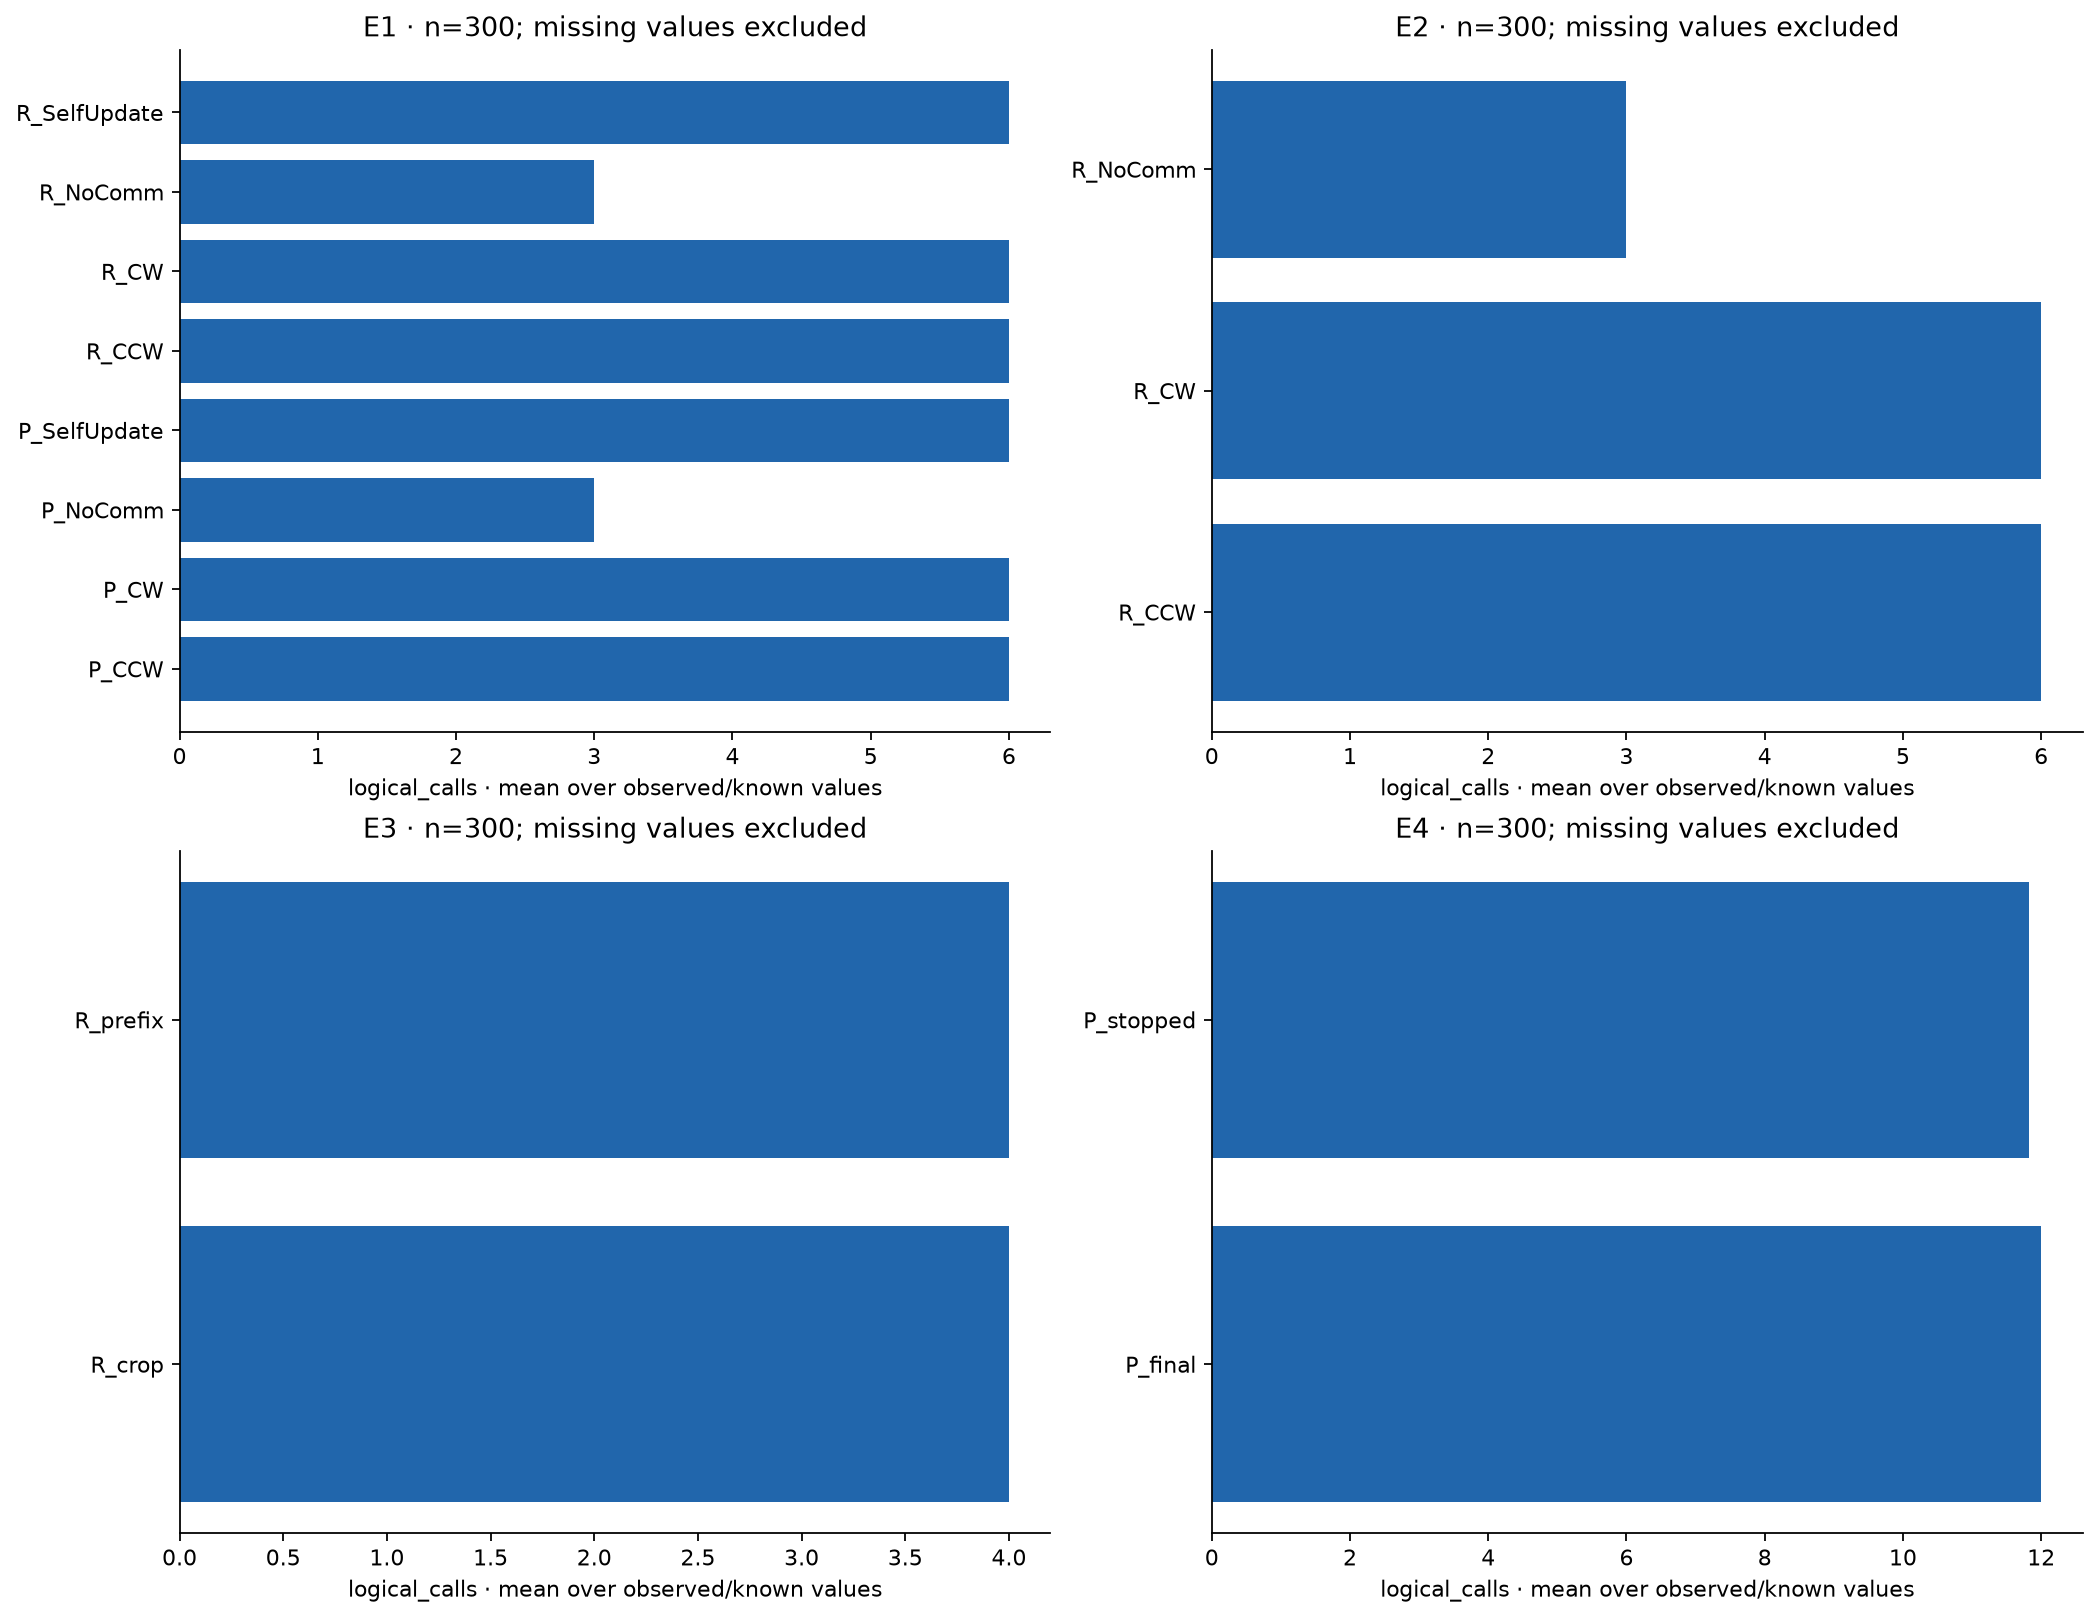

### metric new support facts delivered

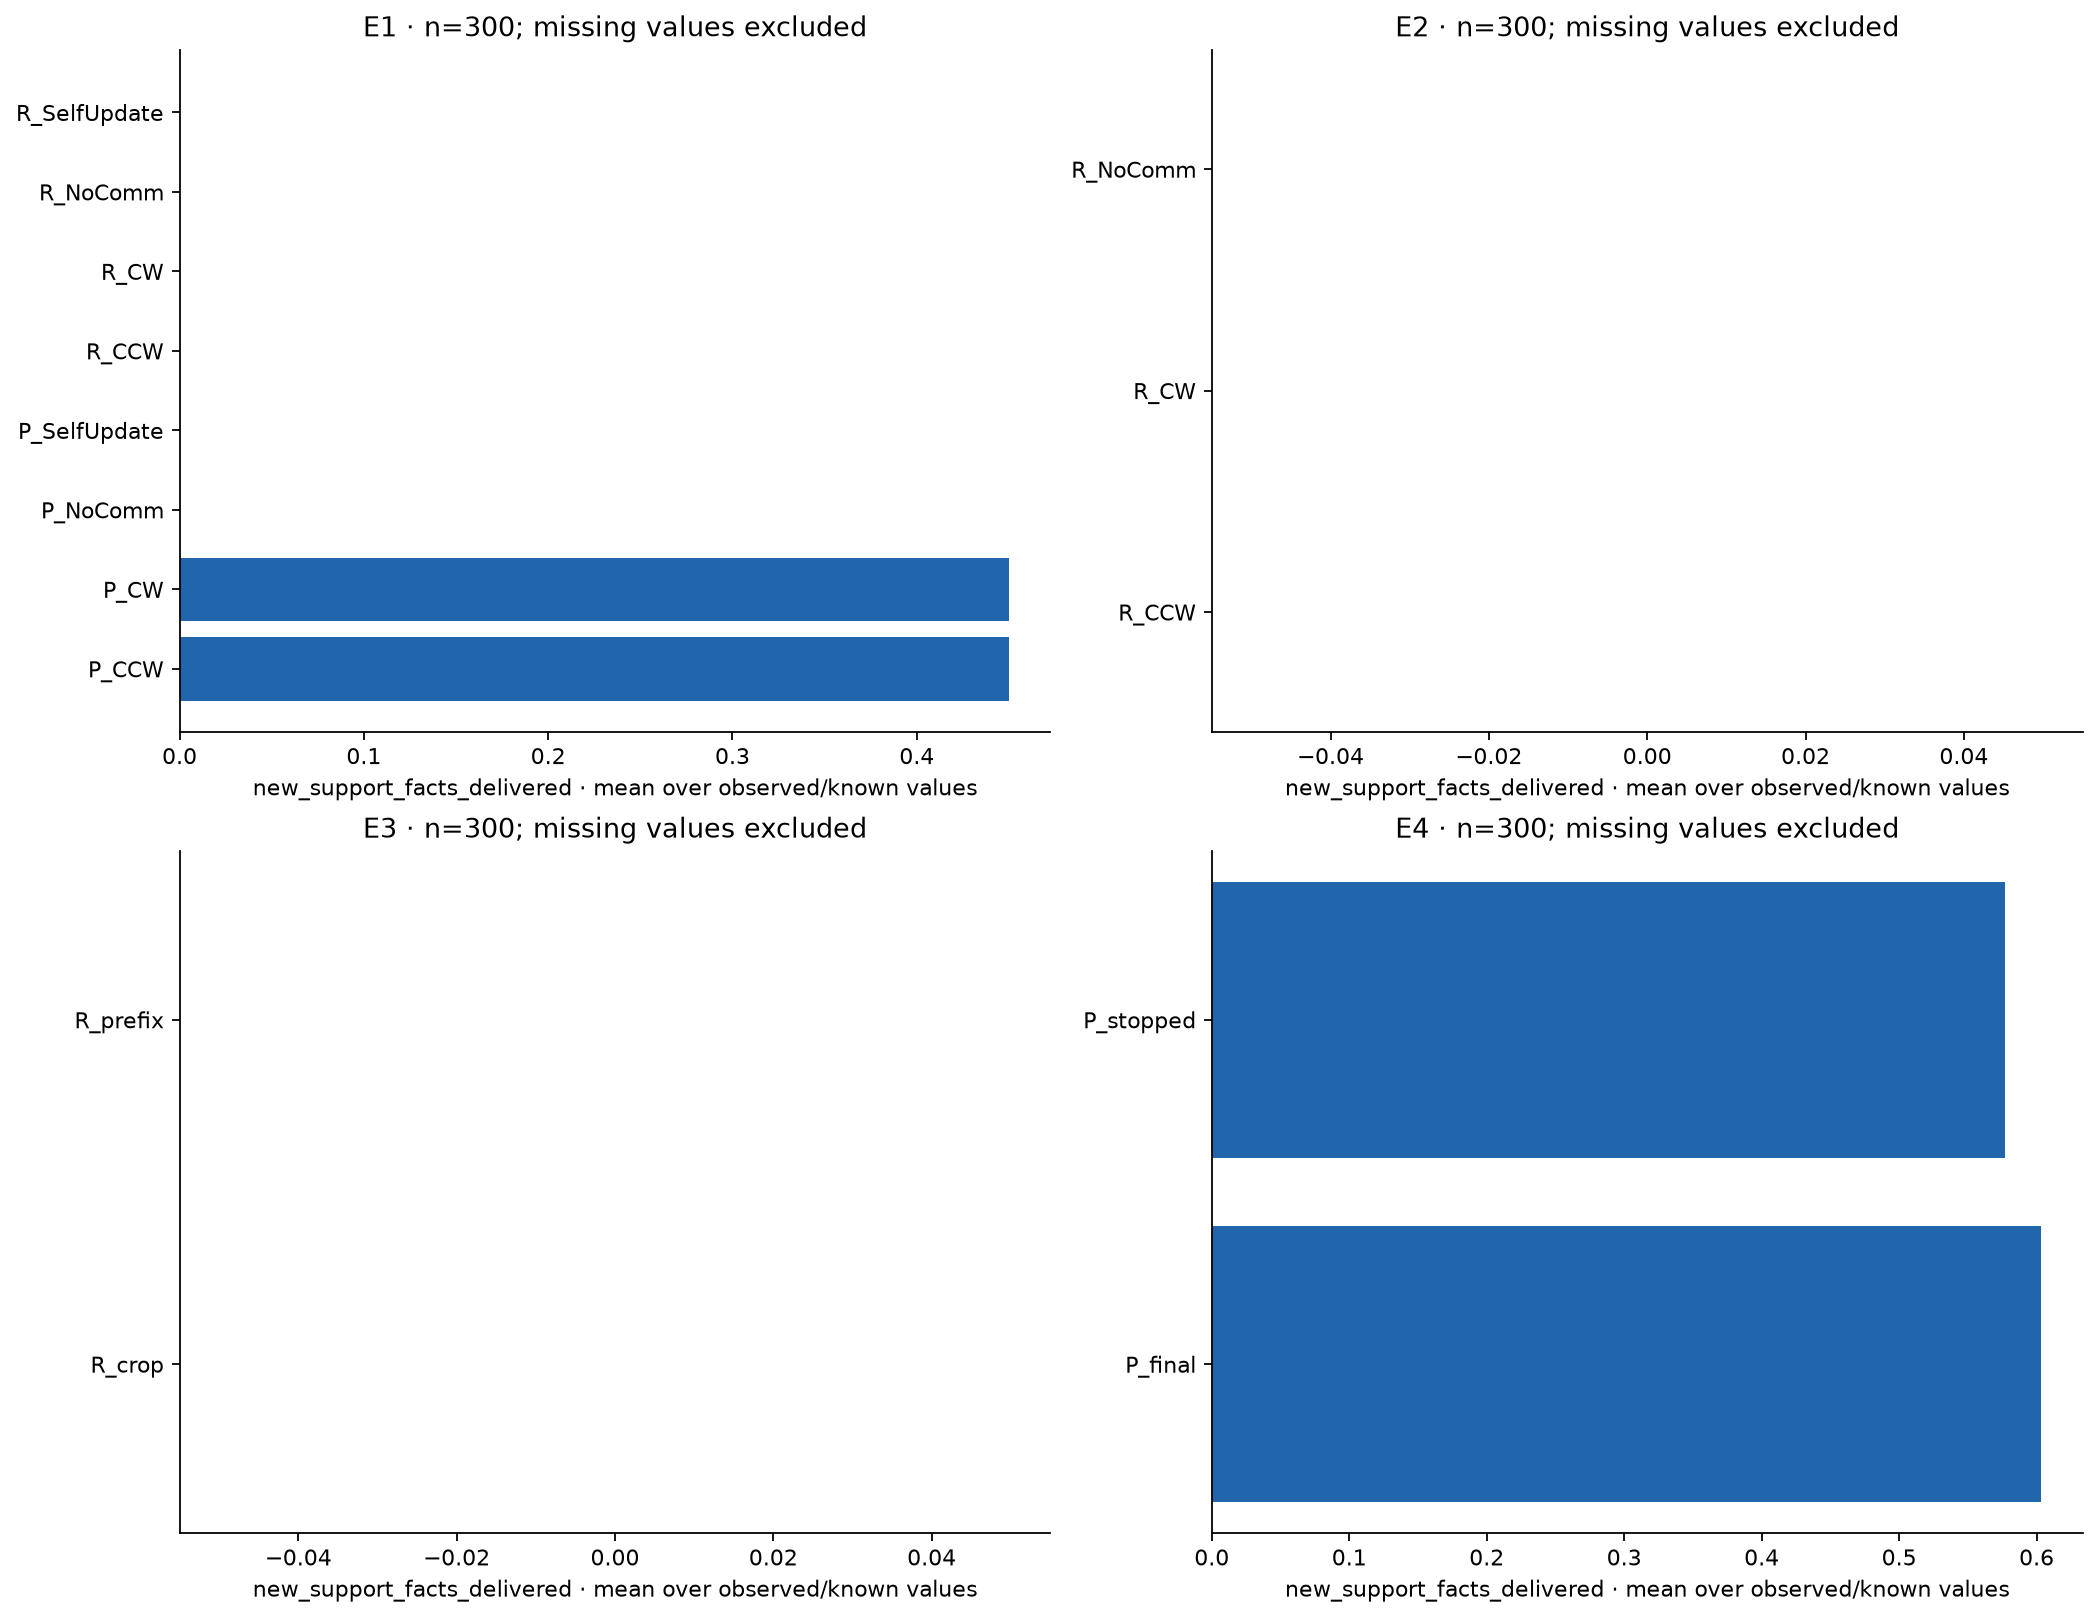

### metric noanswer

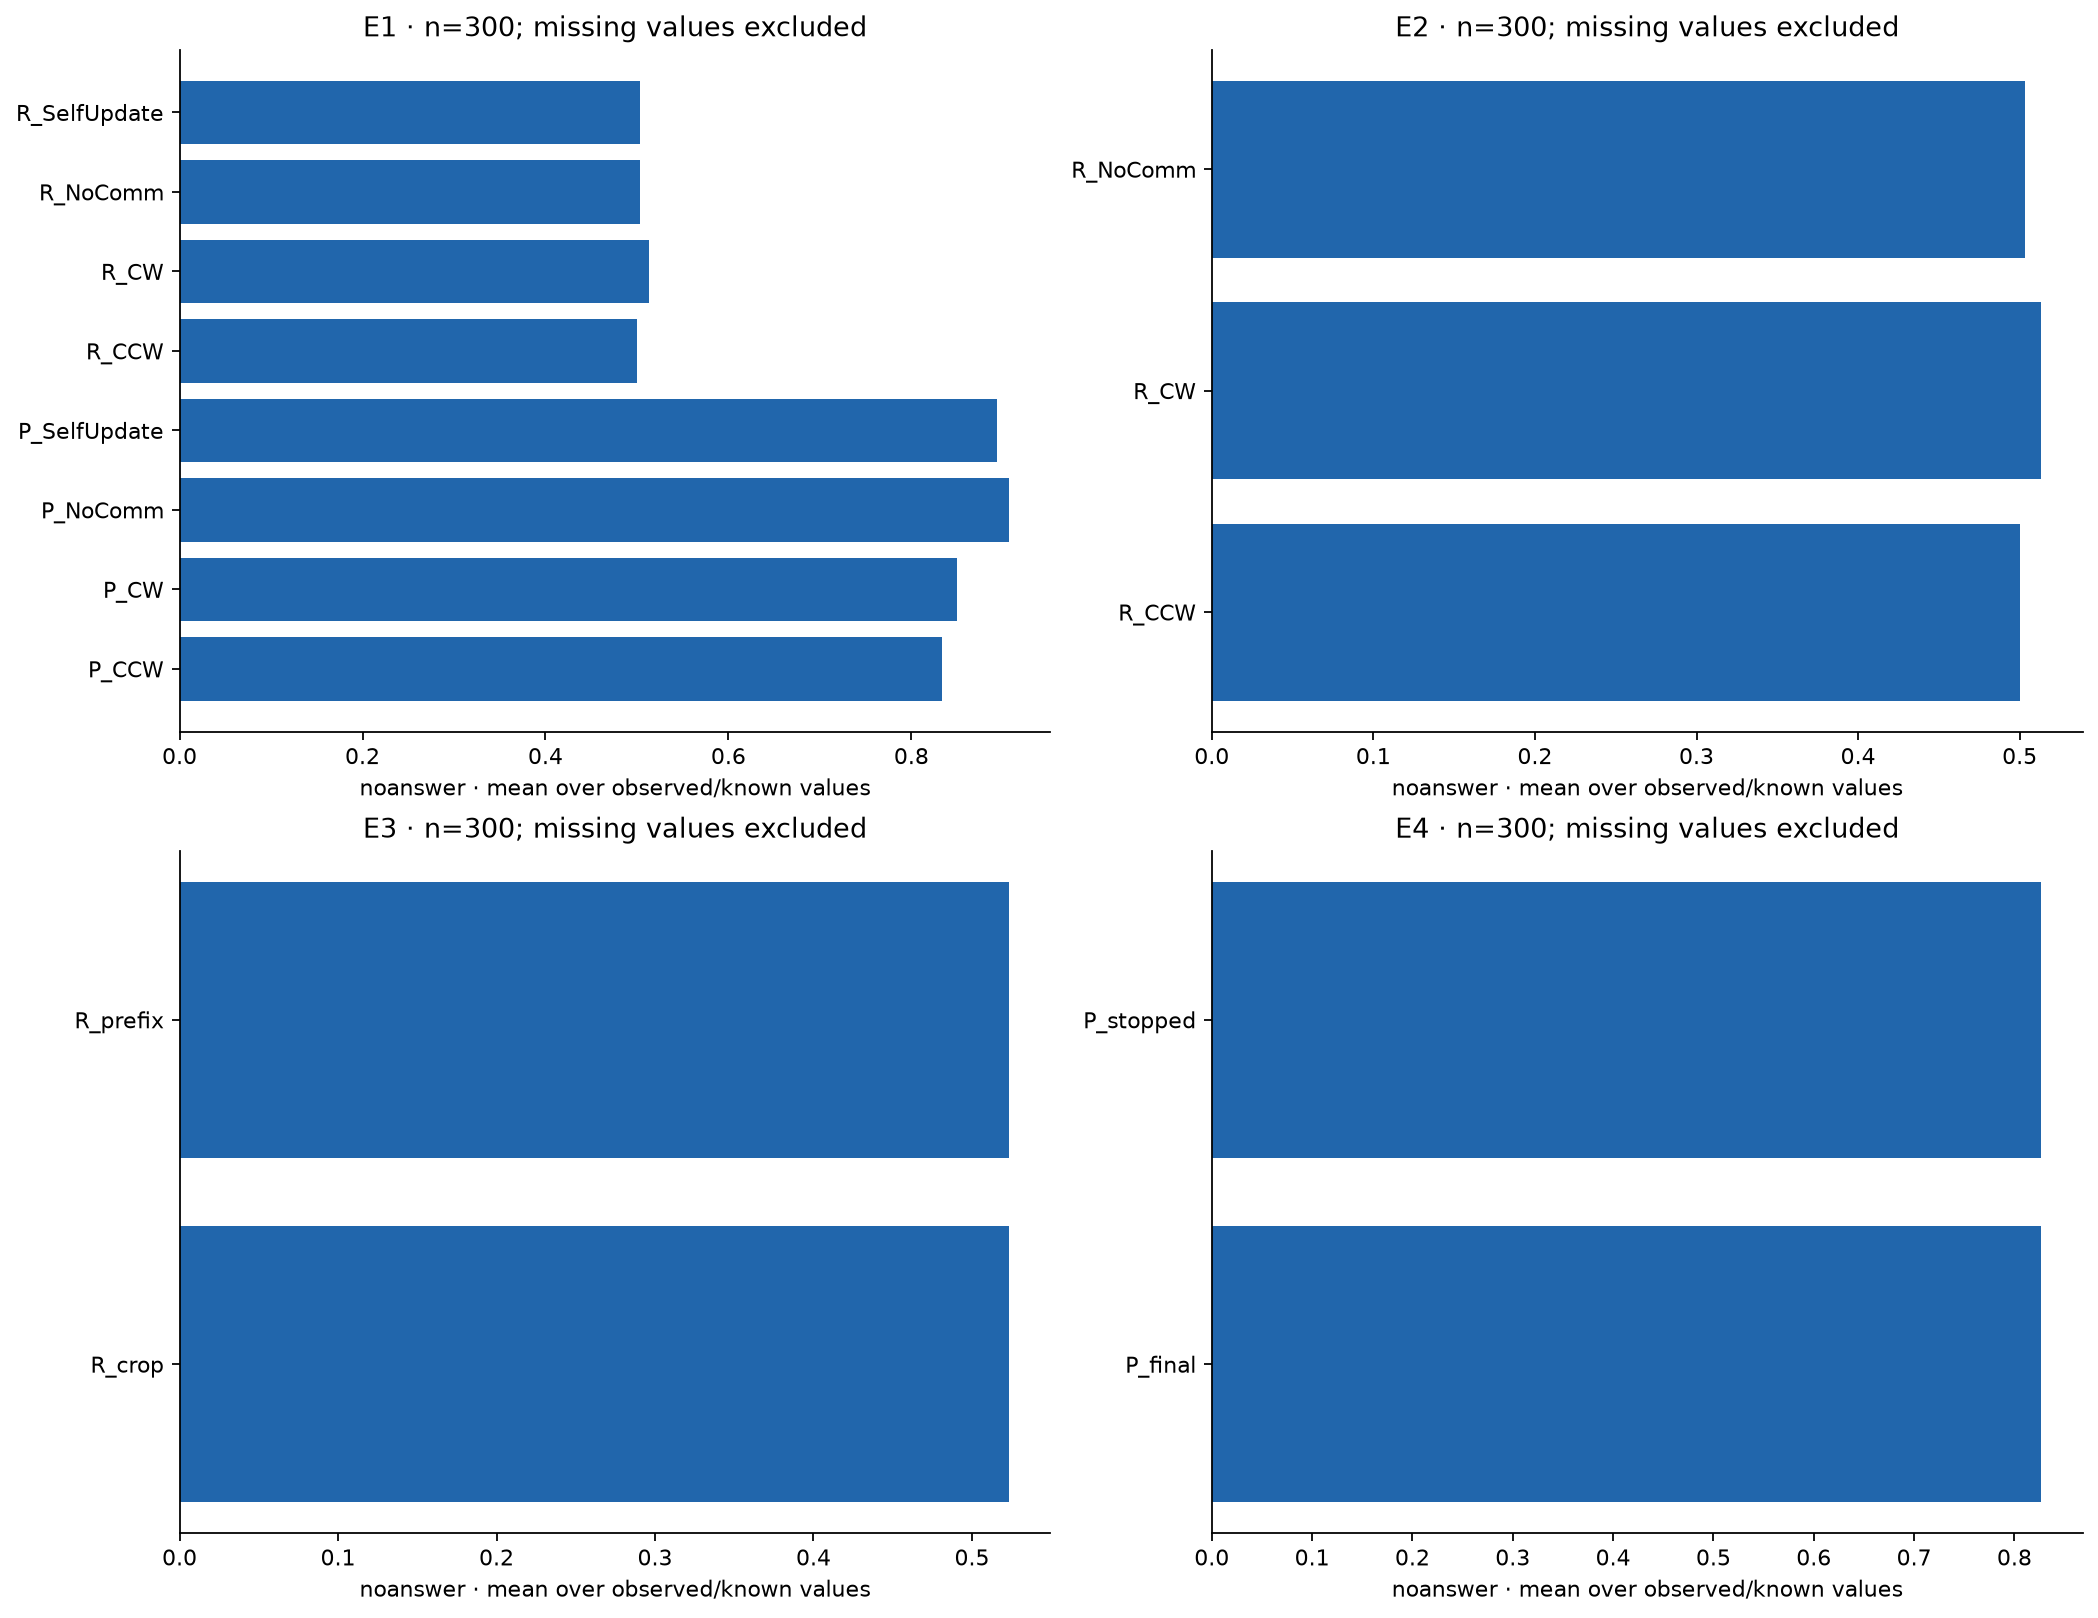

### metric output tokens

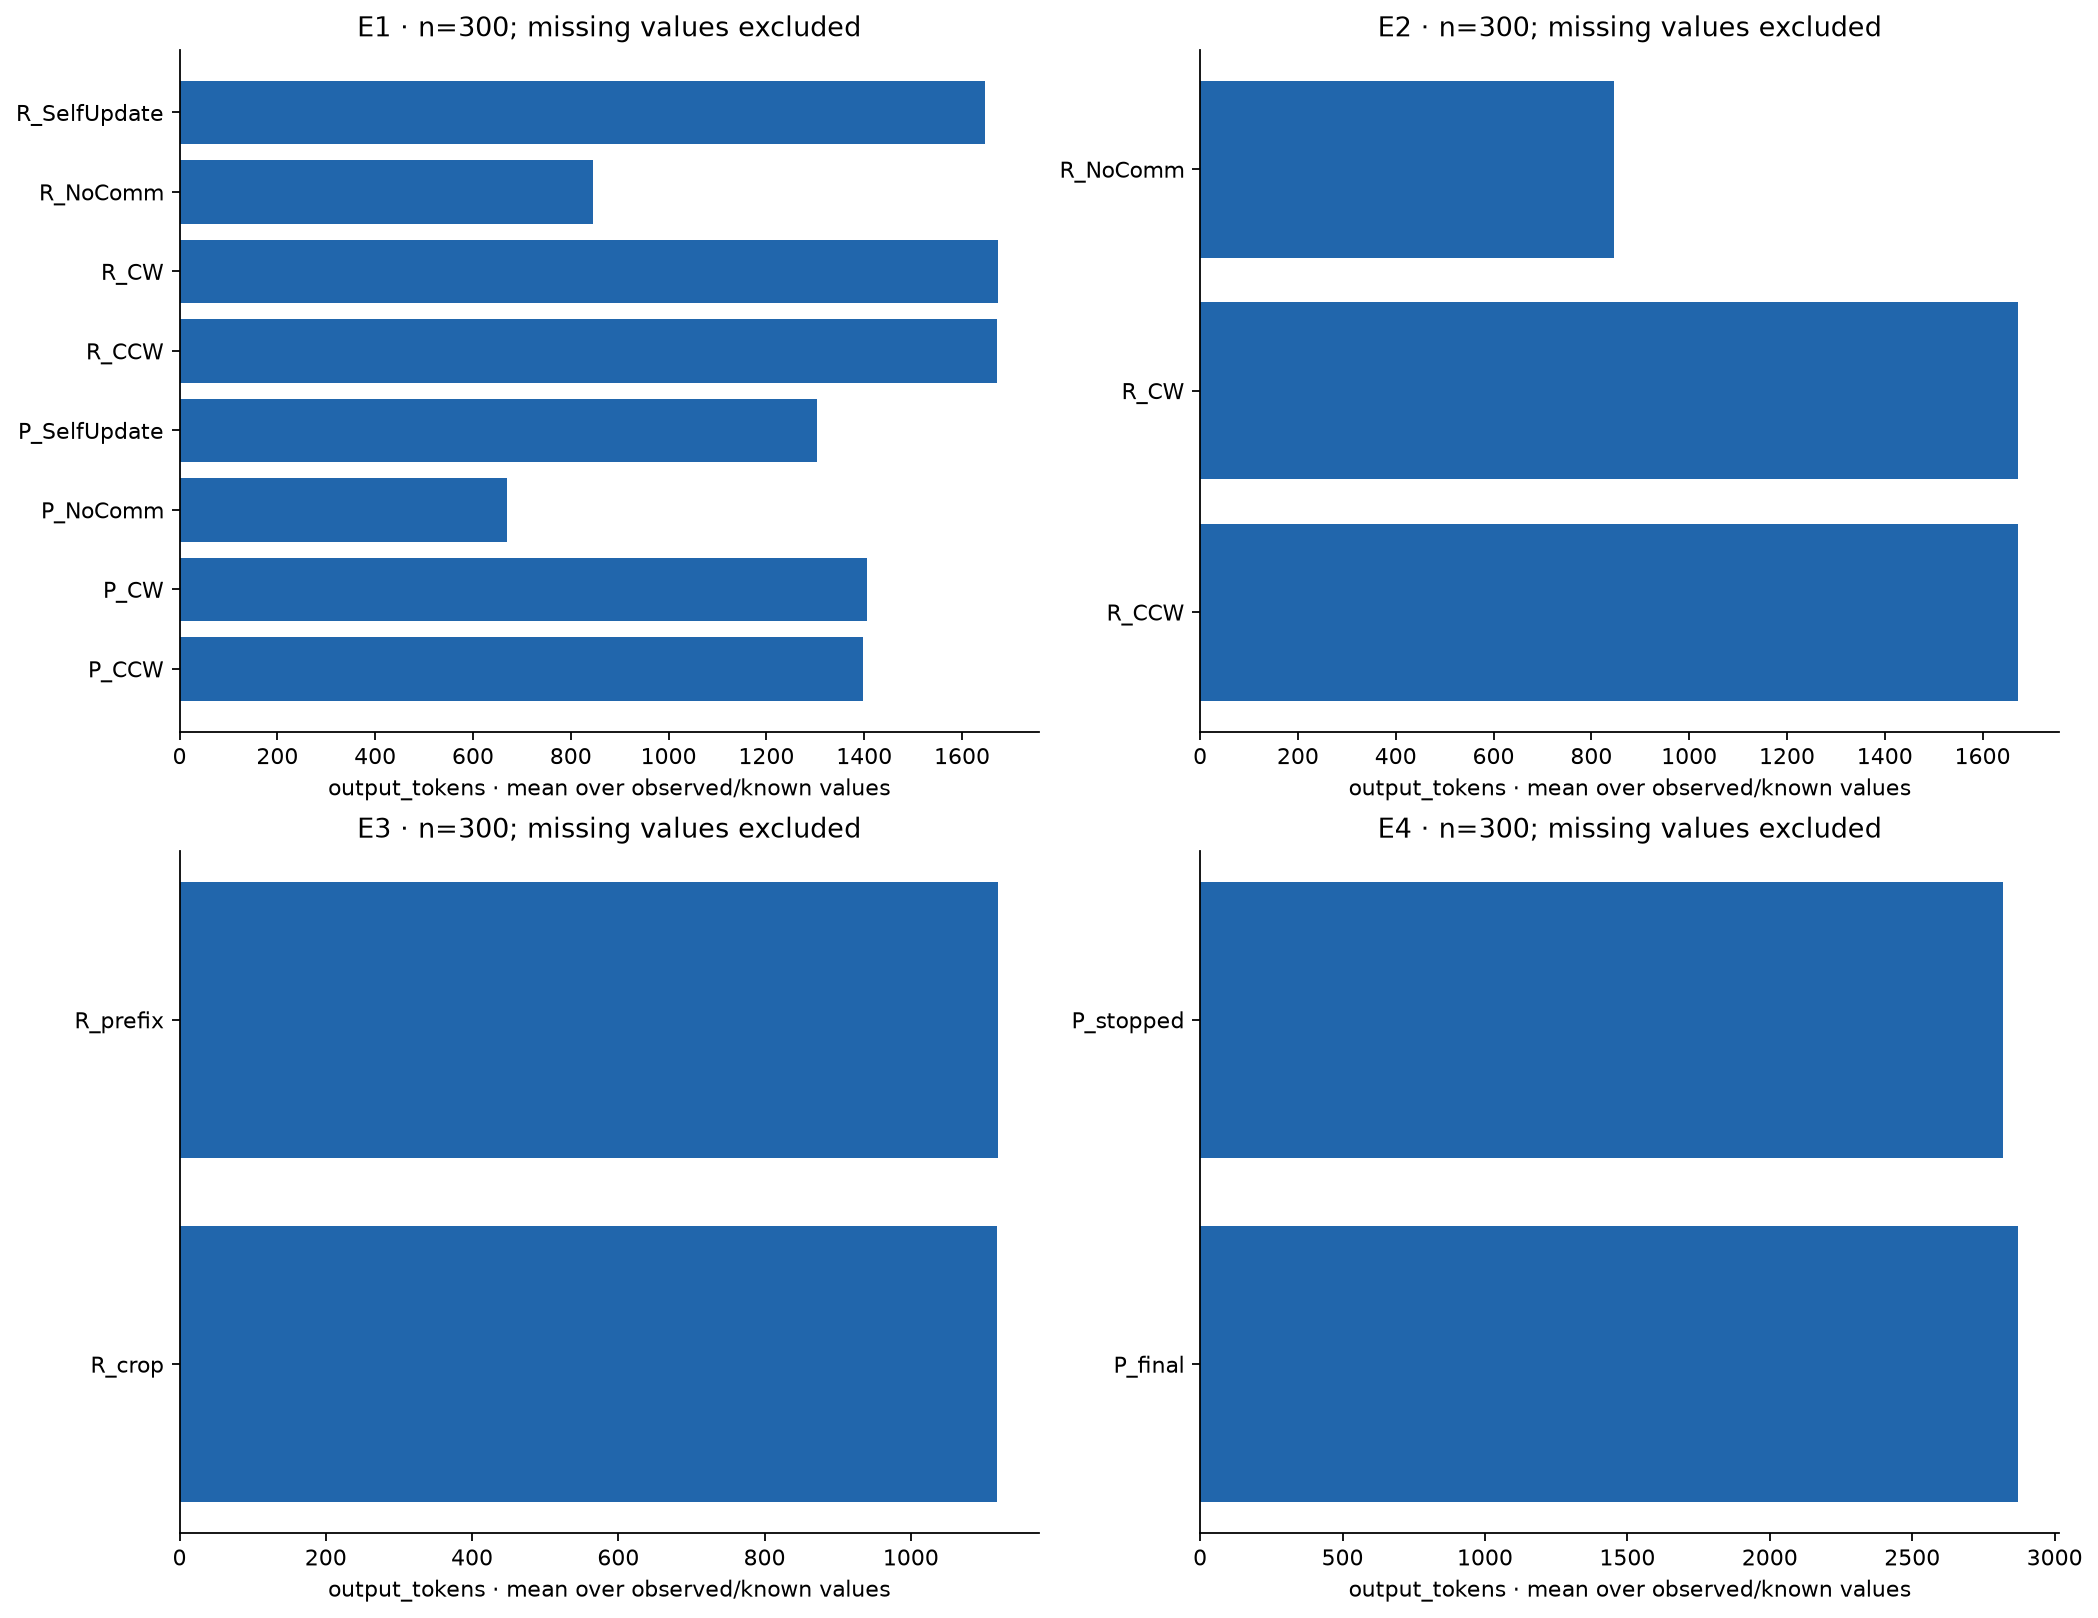

### metric payload tokens

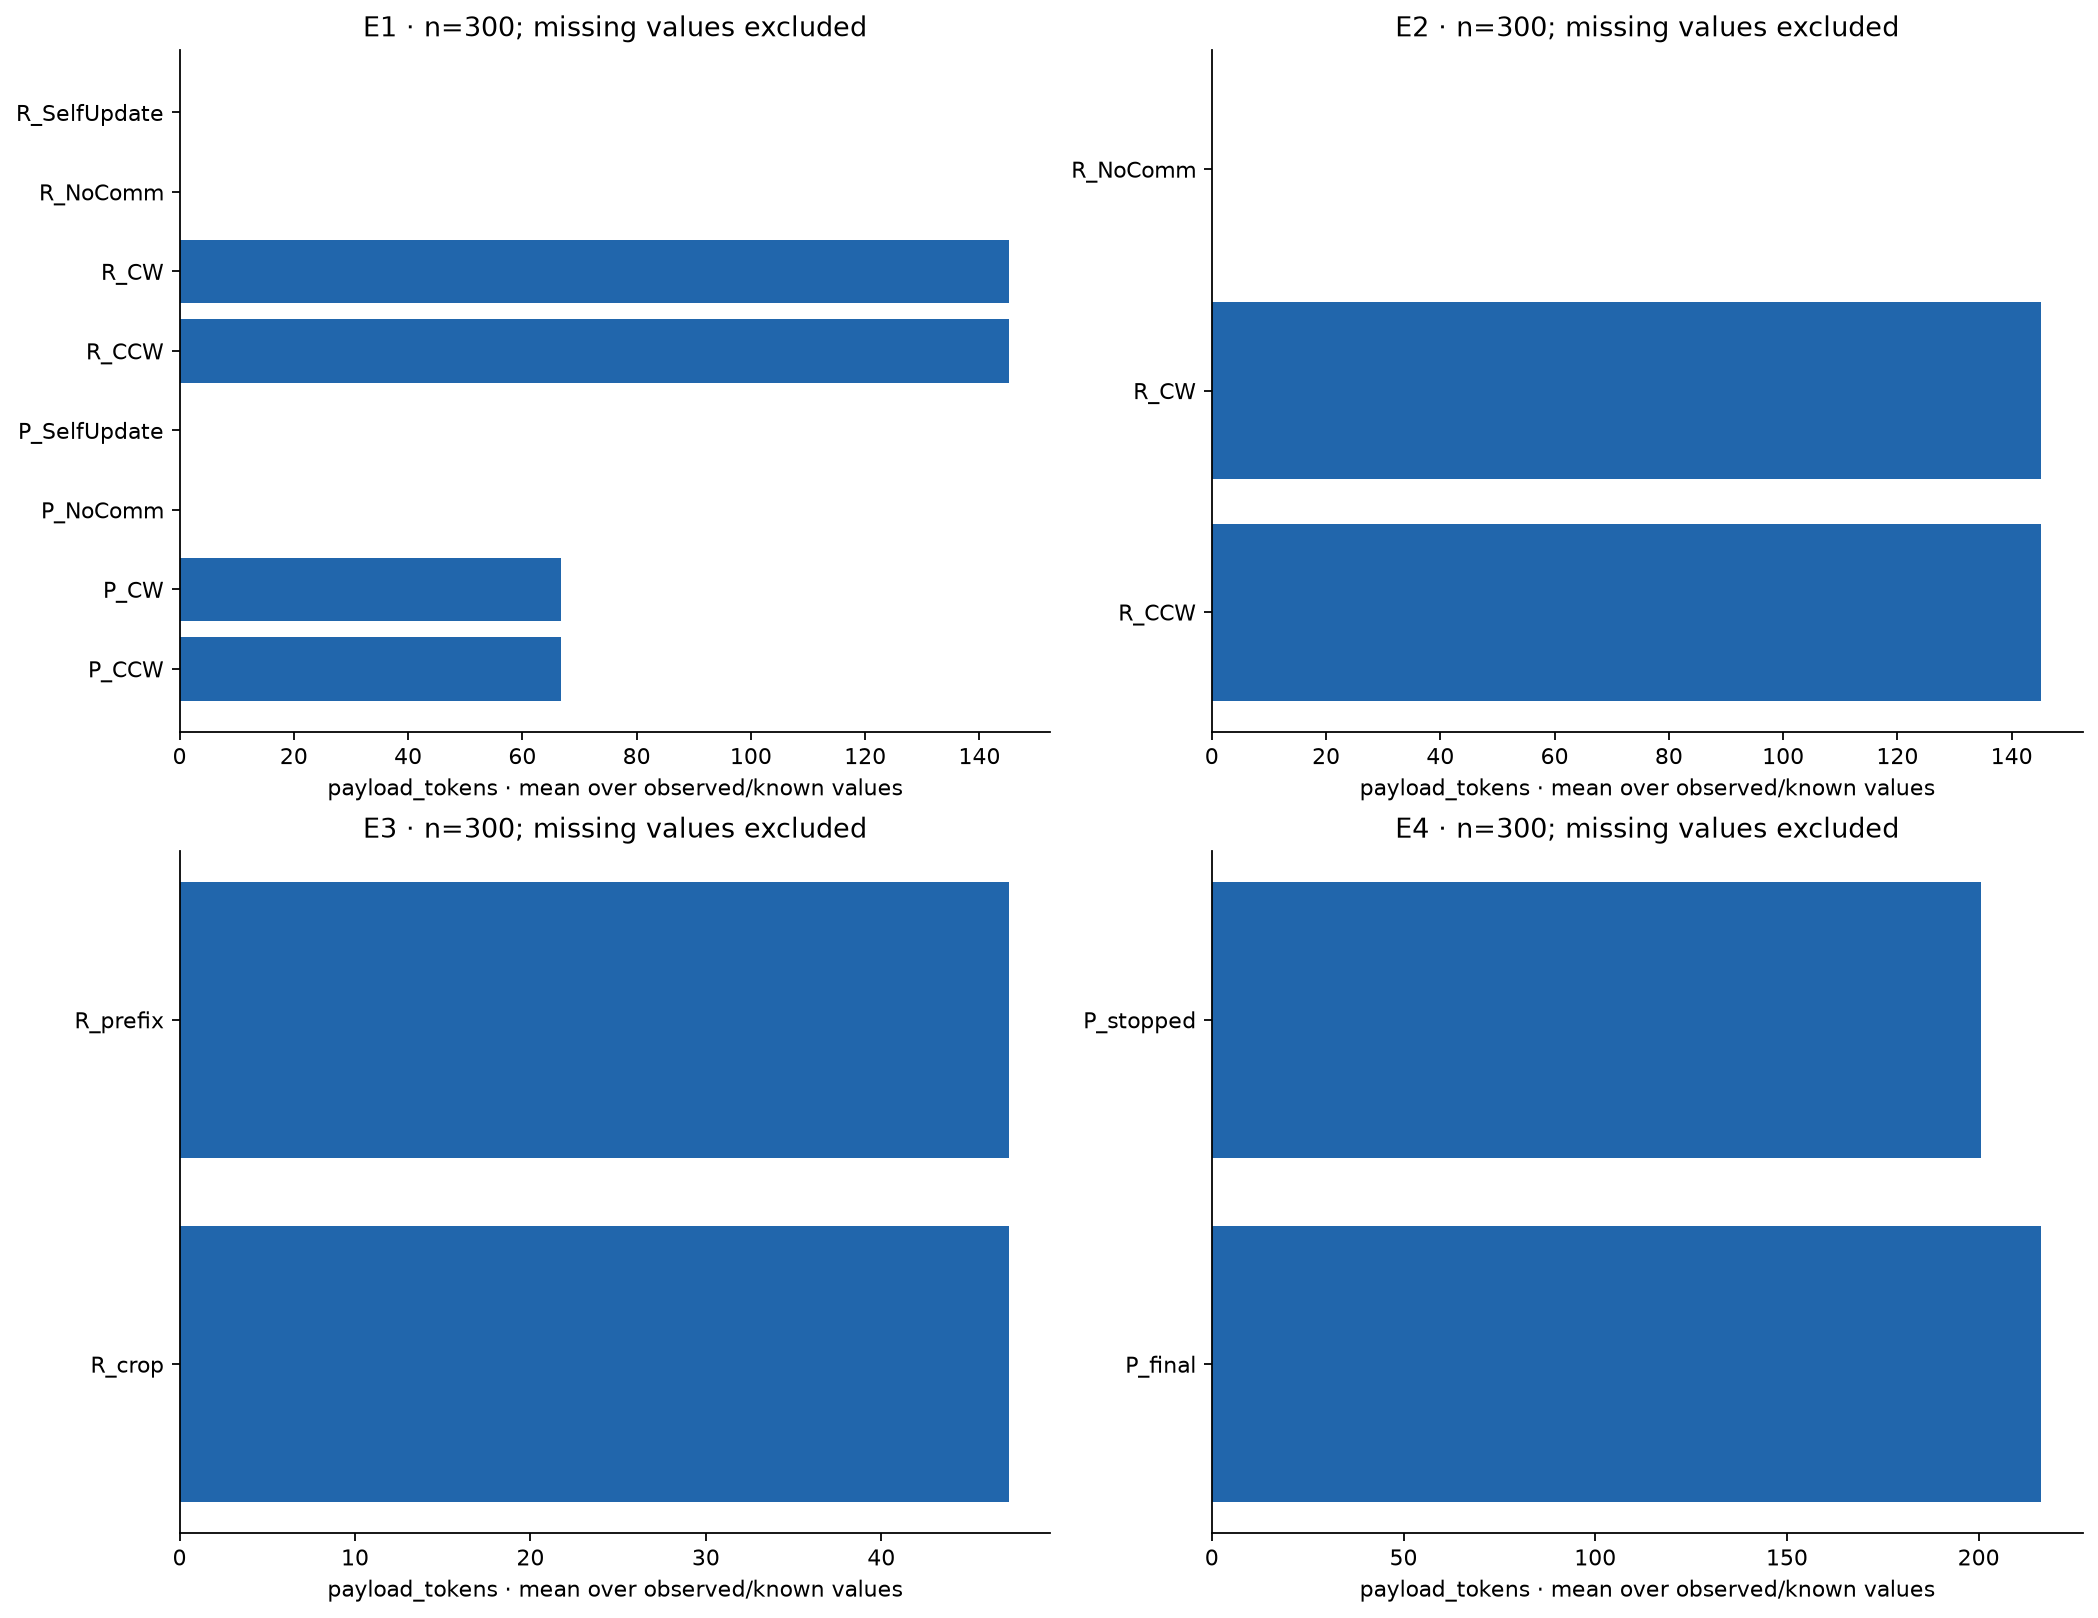

### metric provider refusal calls

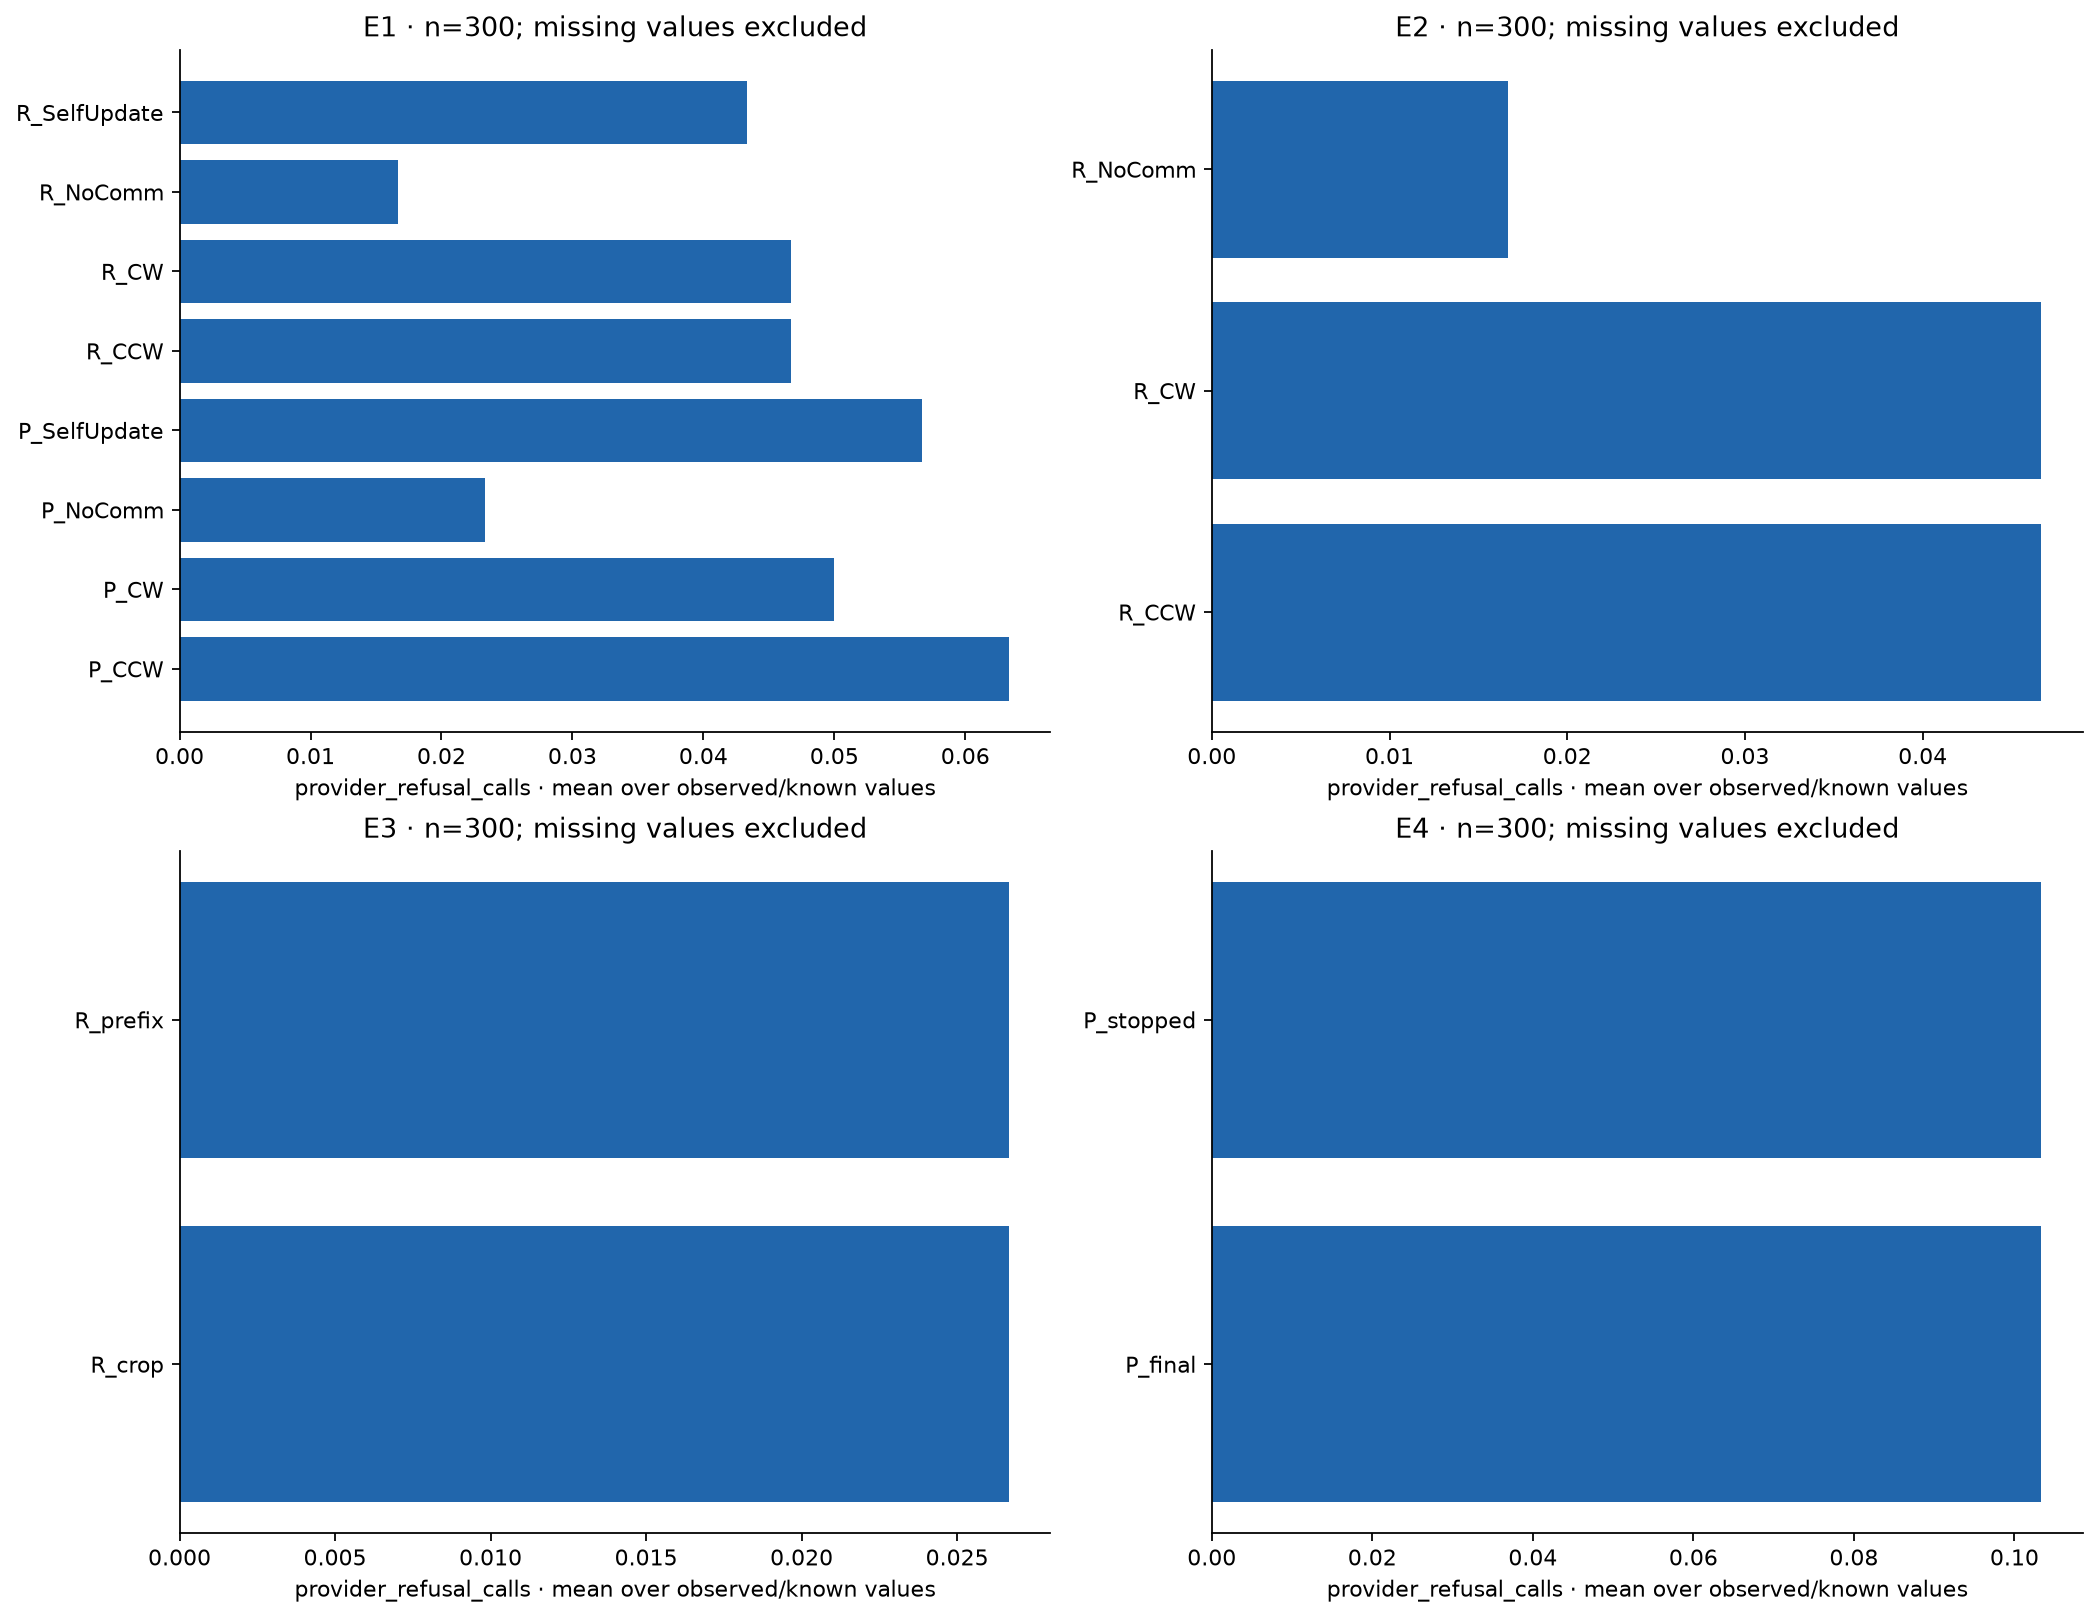

### metric provider refusal count

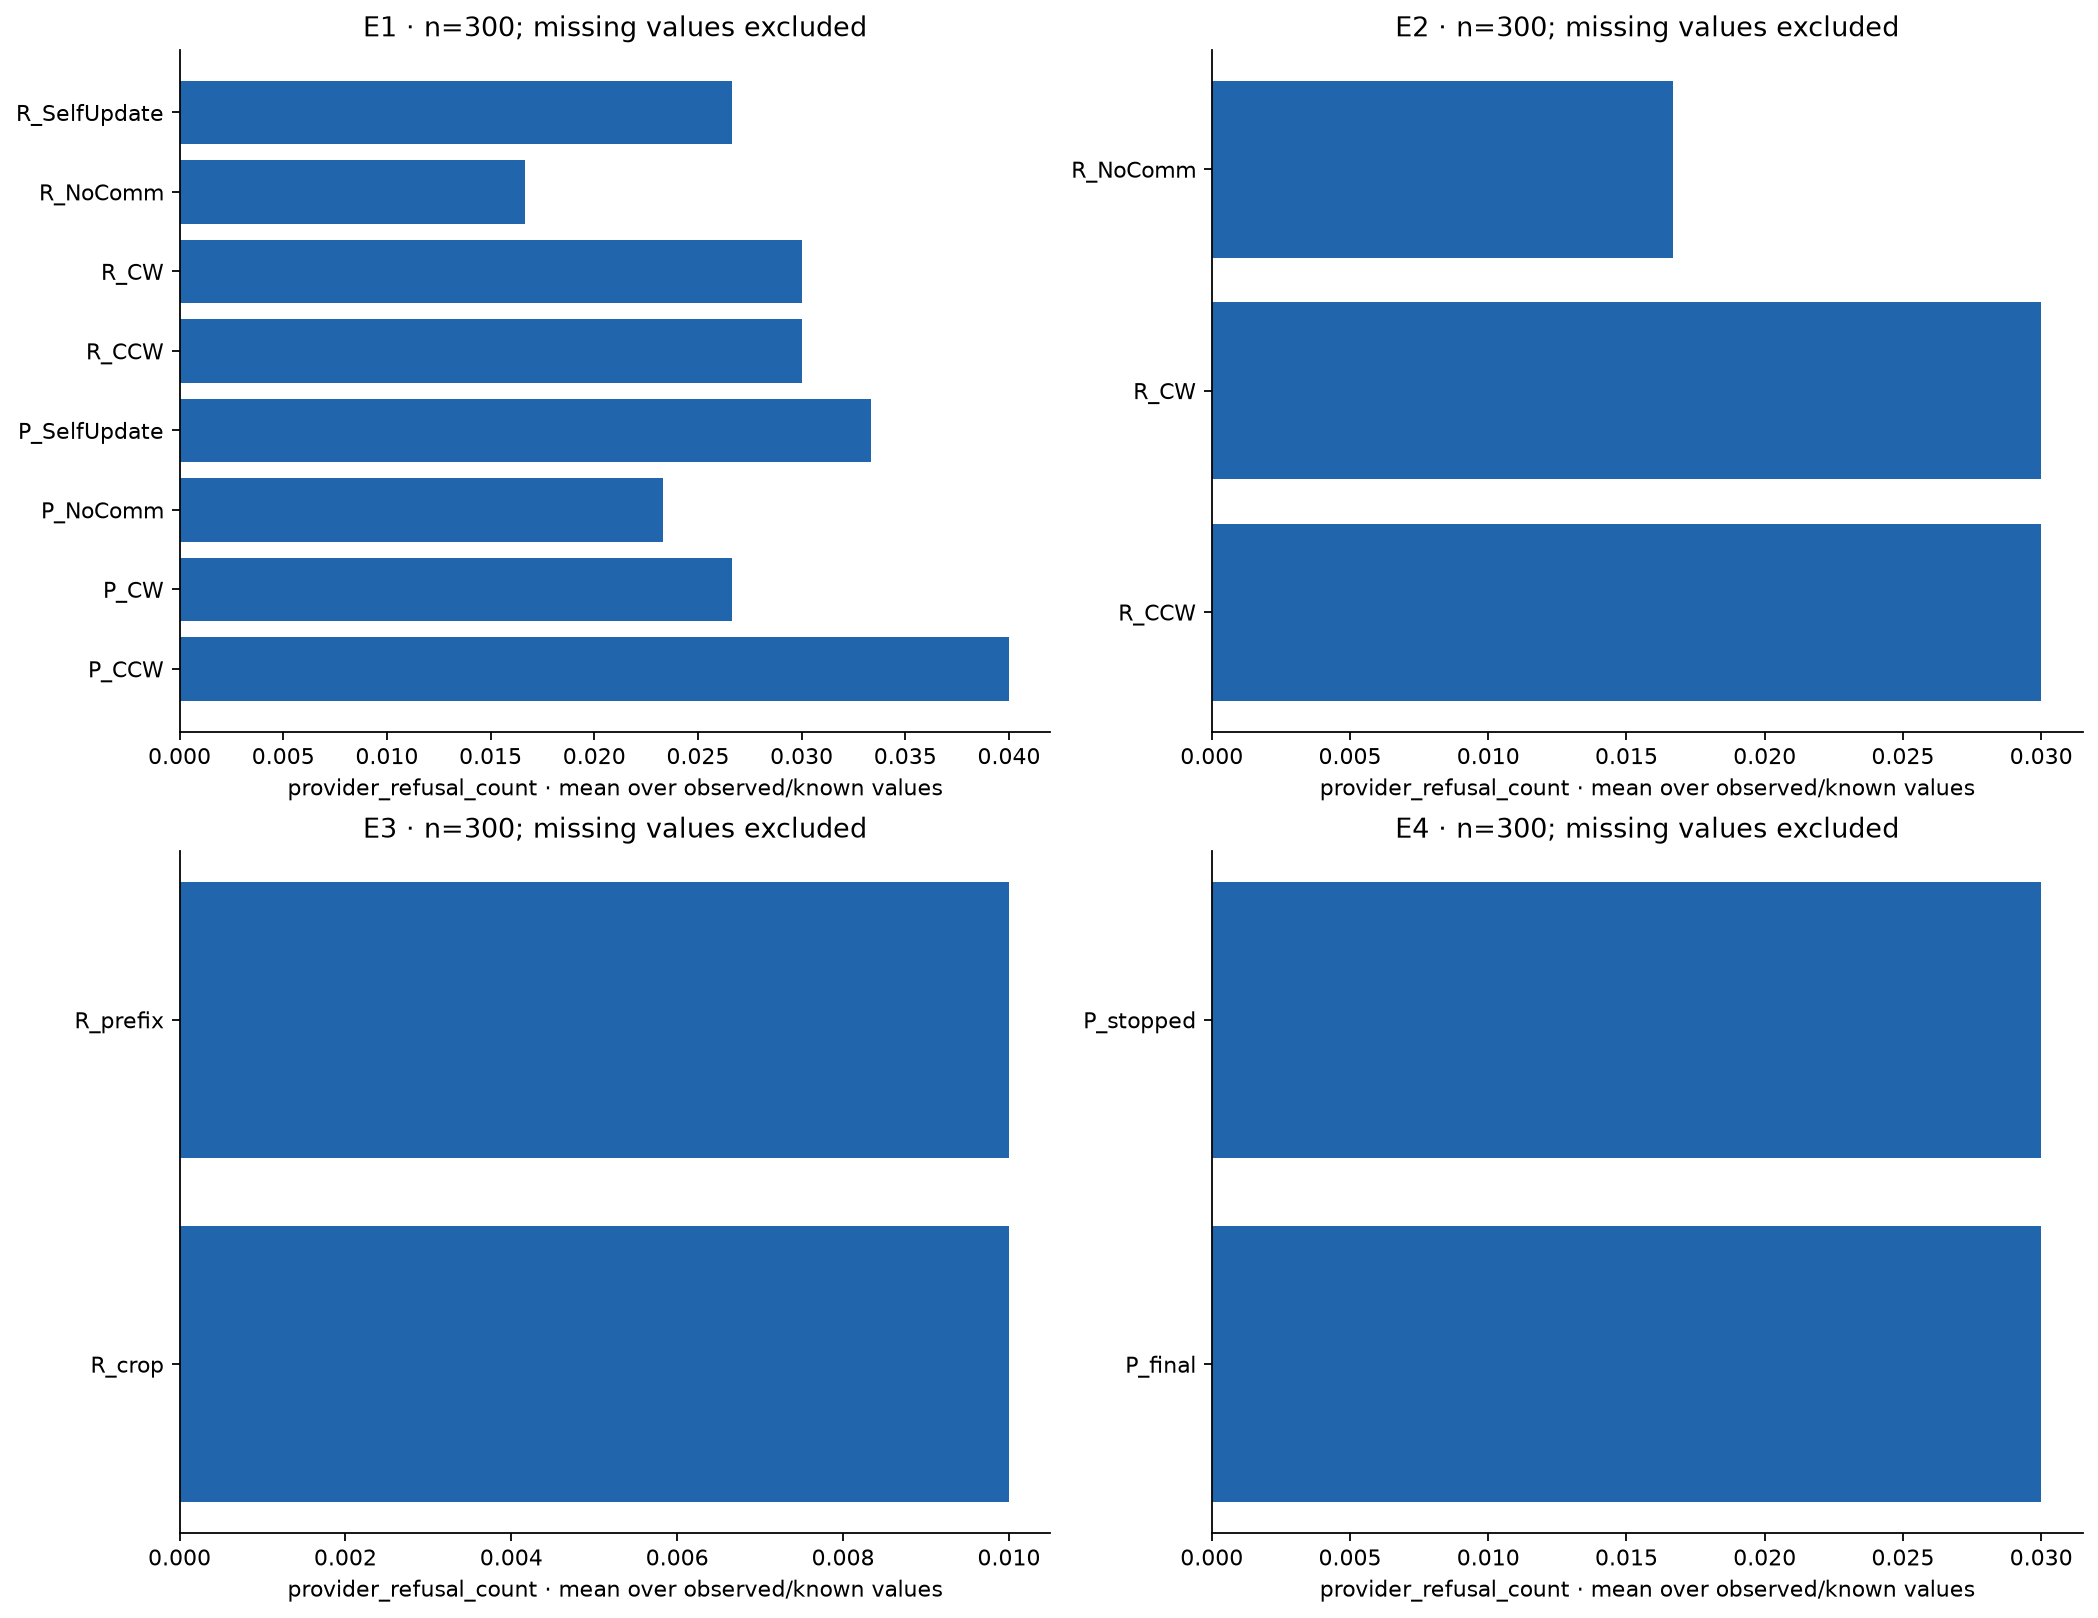

### metric provider refusal question

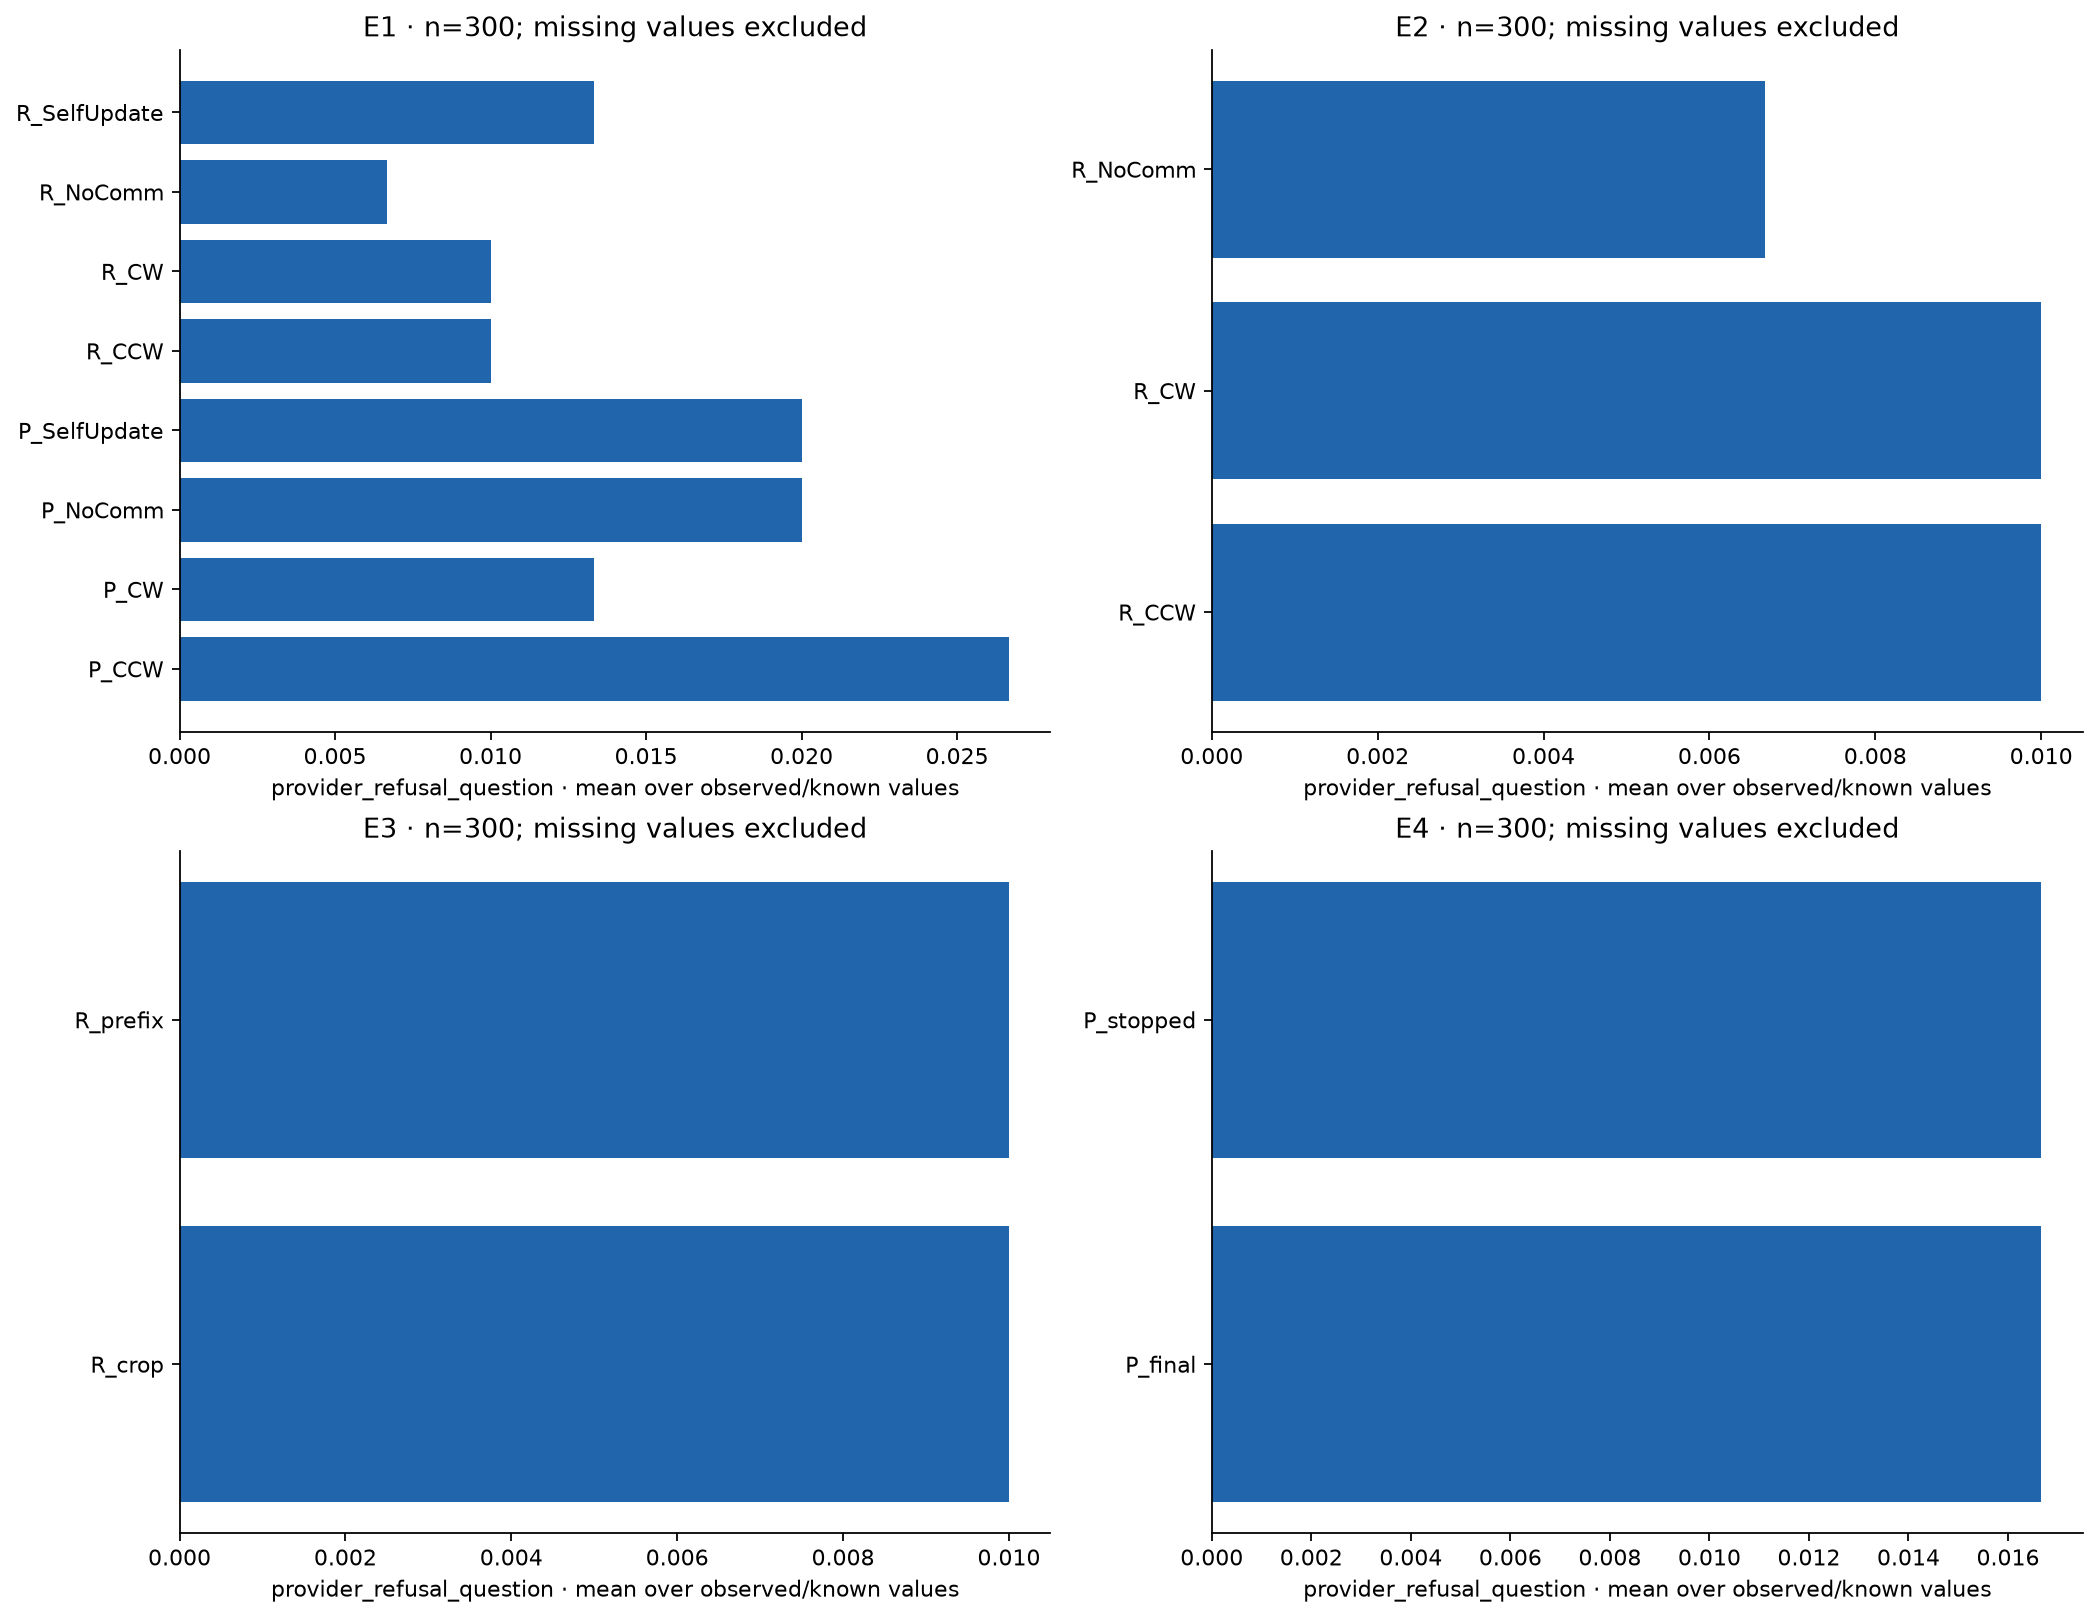

### metric split support across nodes

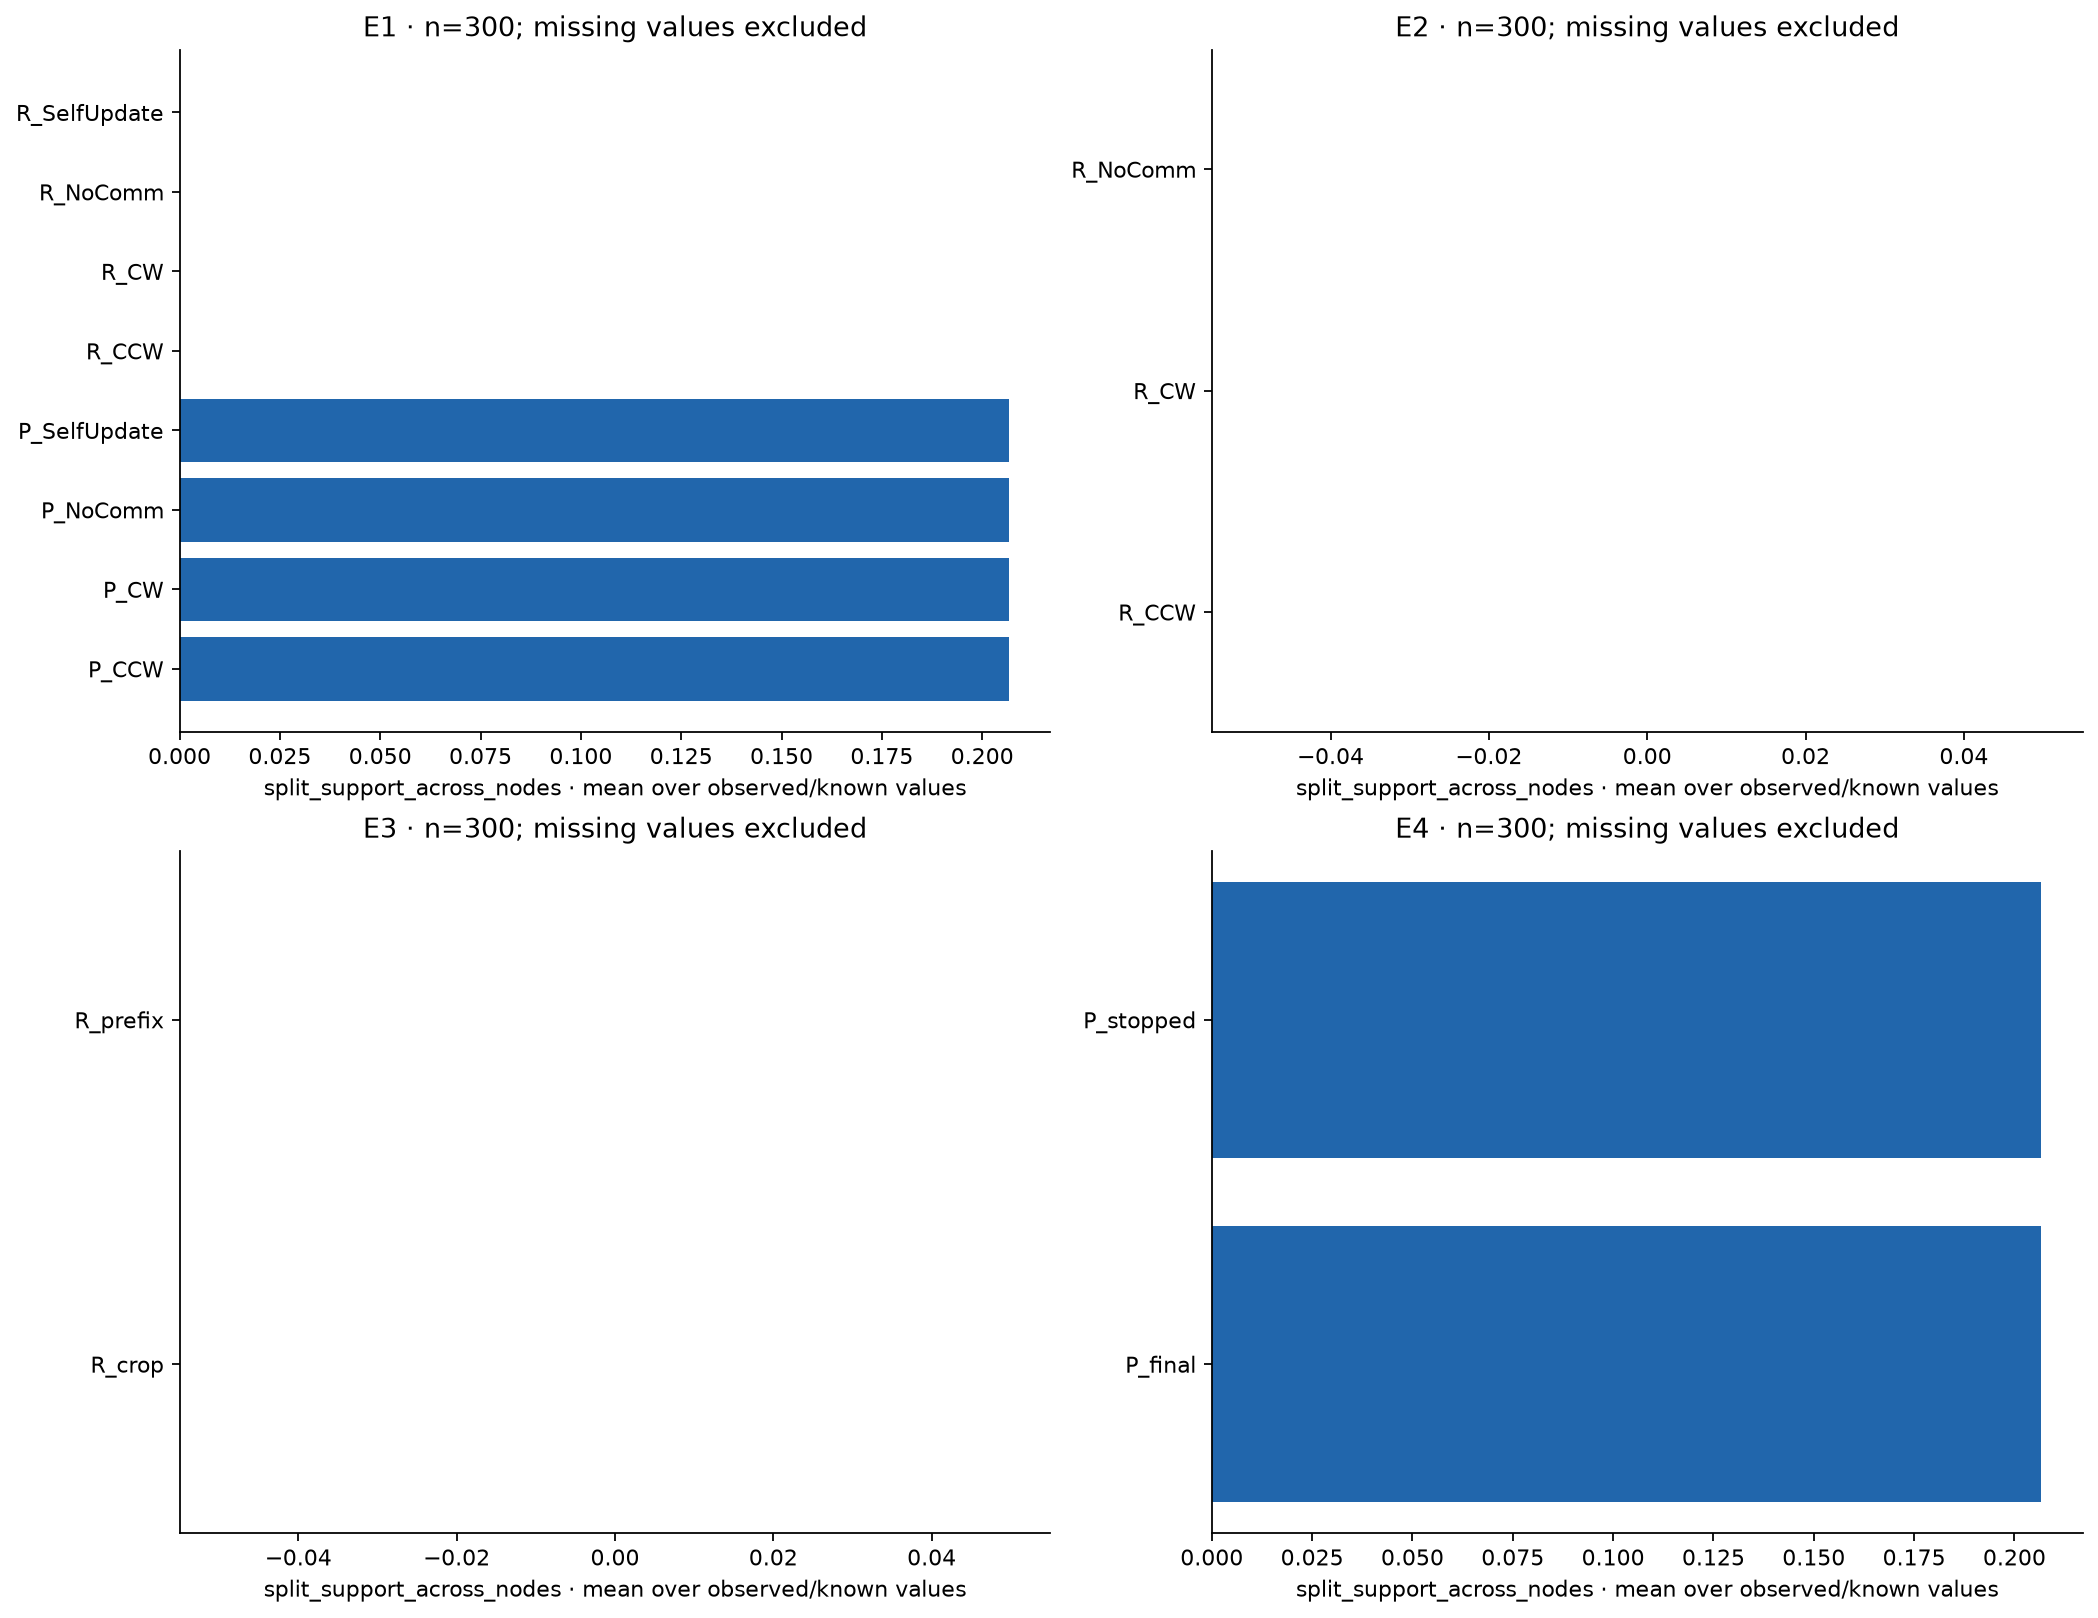

### metric support available recall

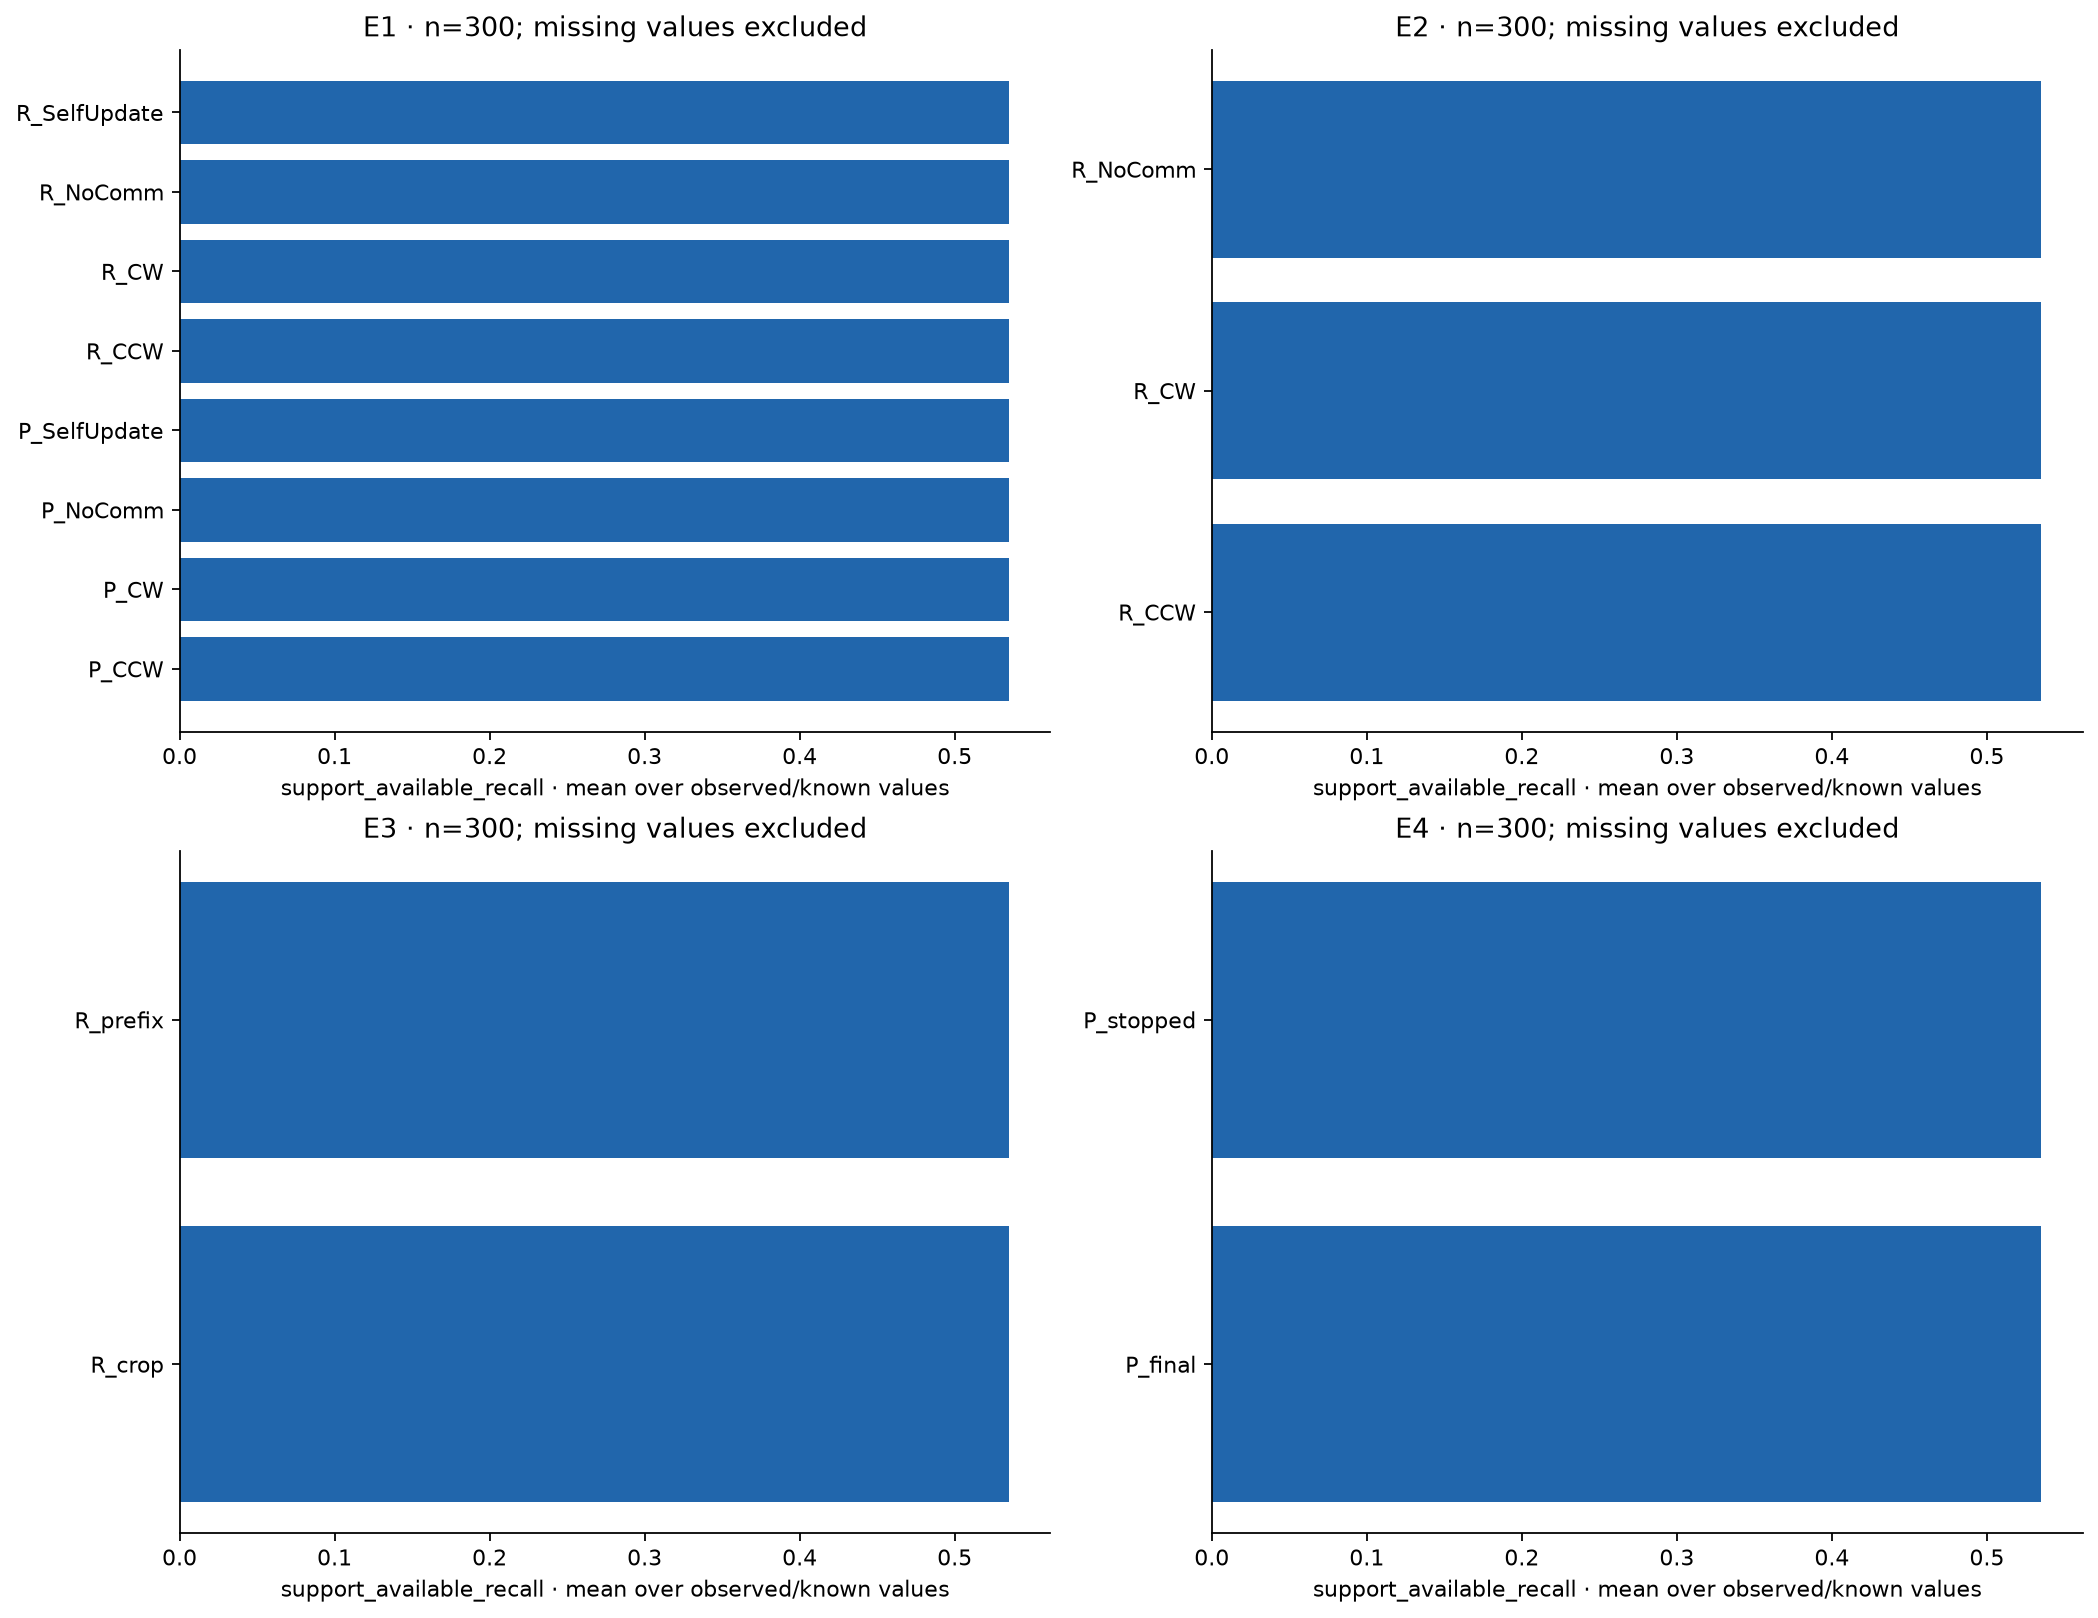

### metric support label em

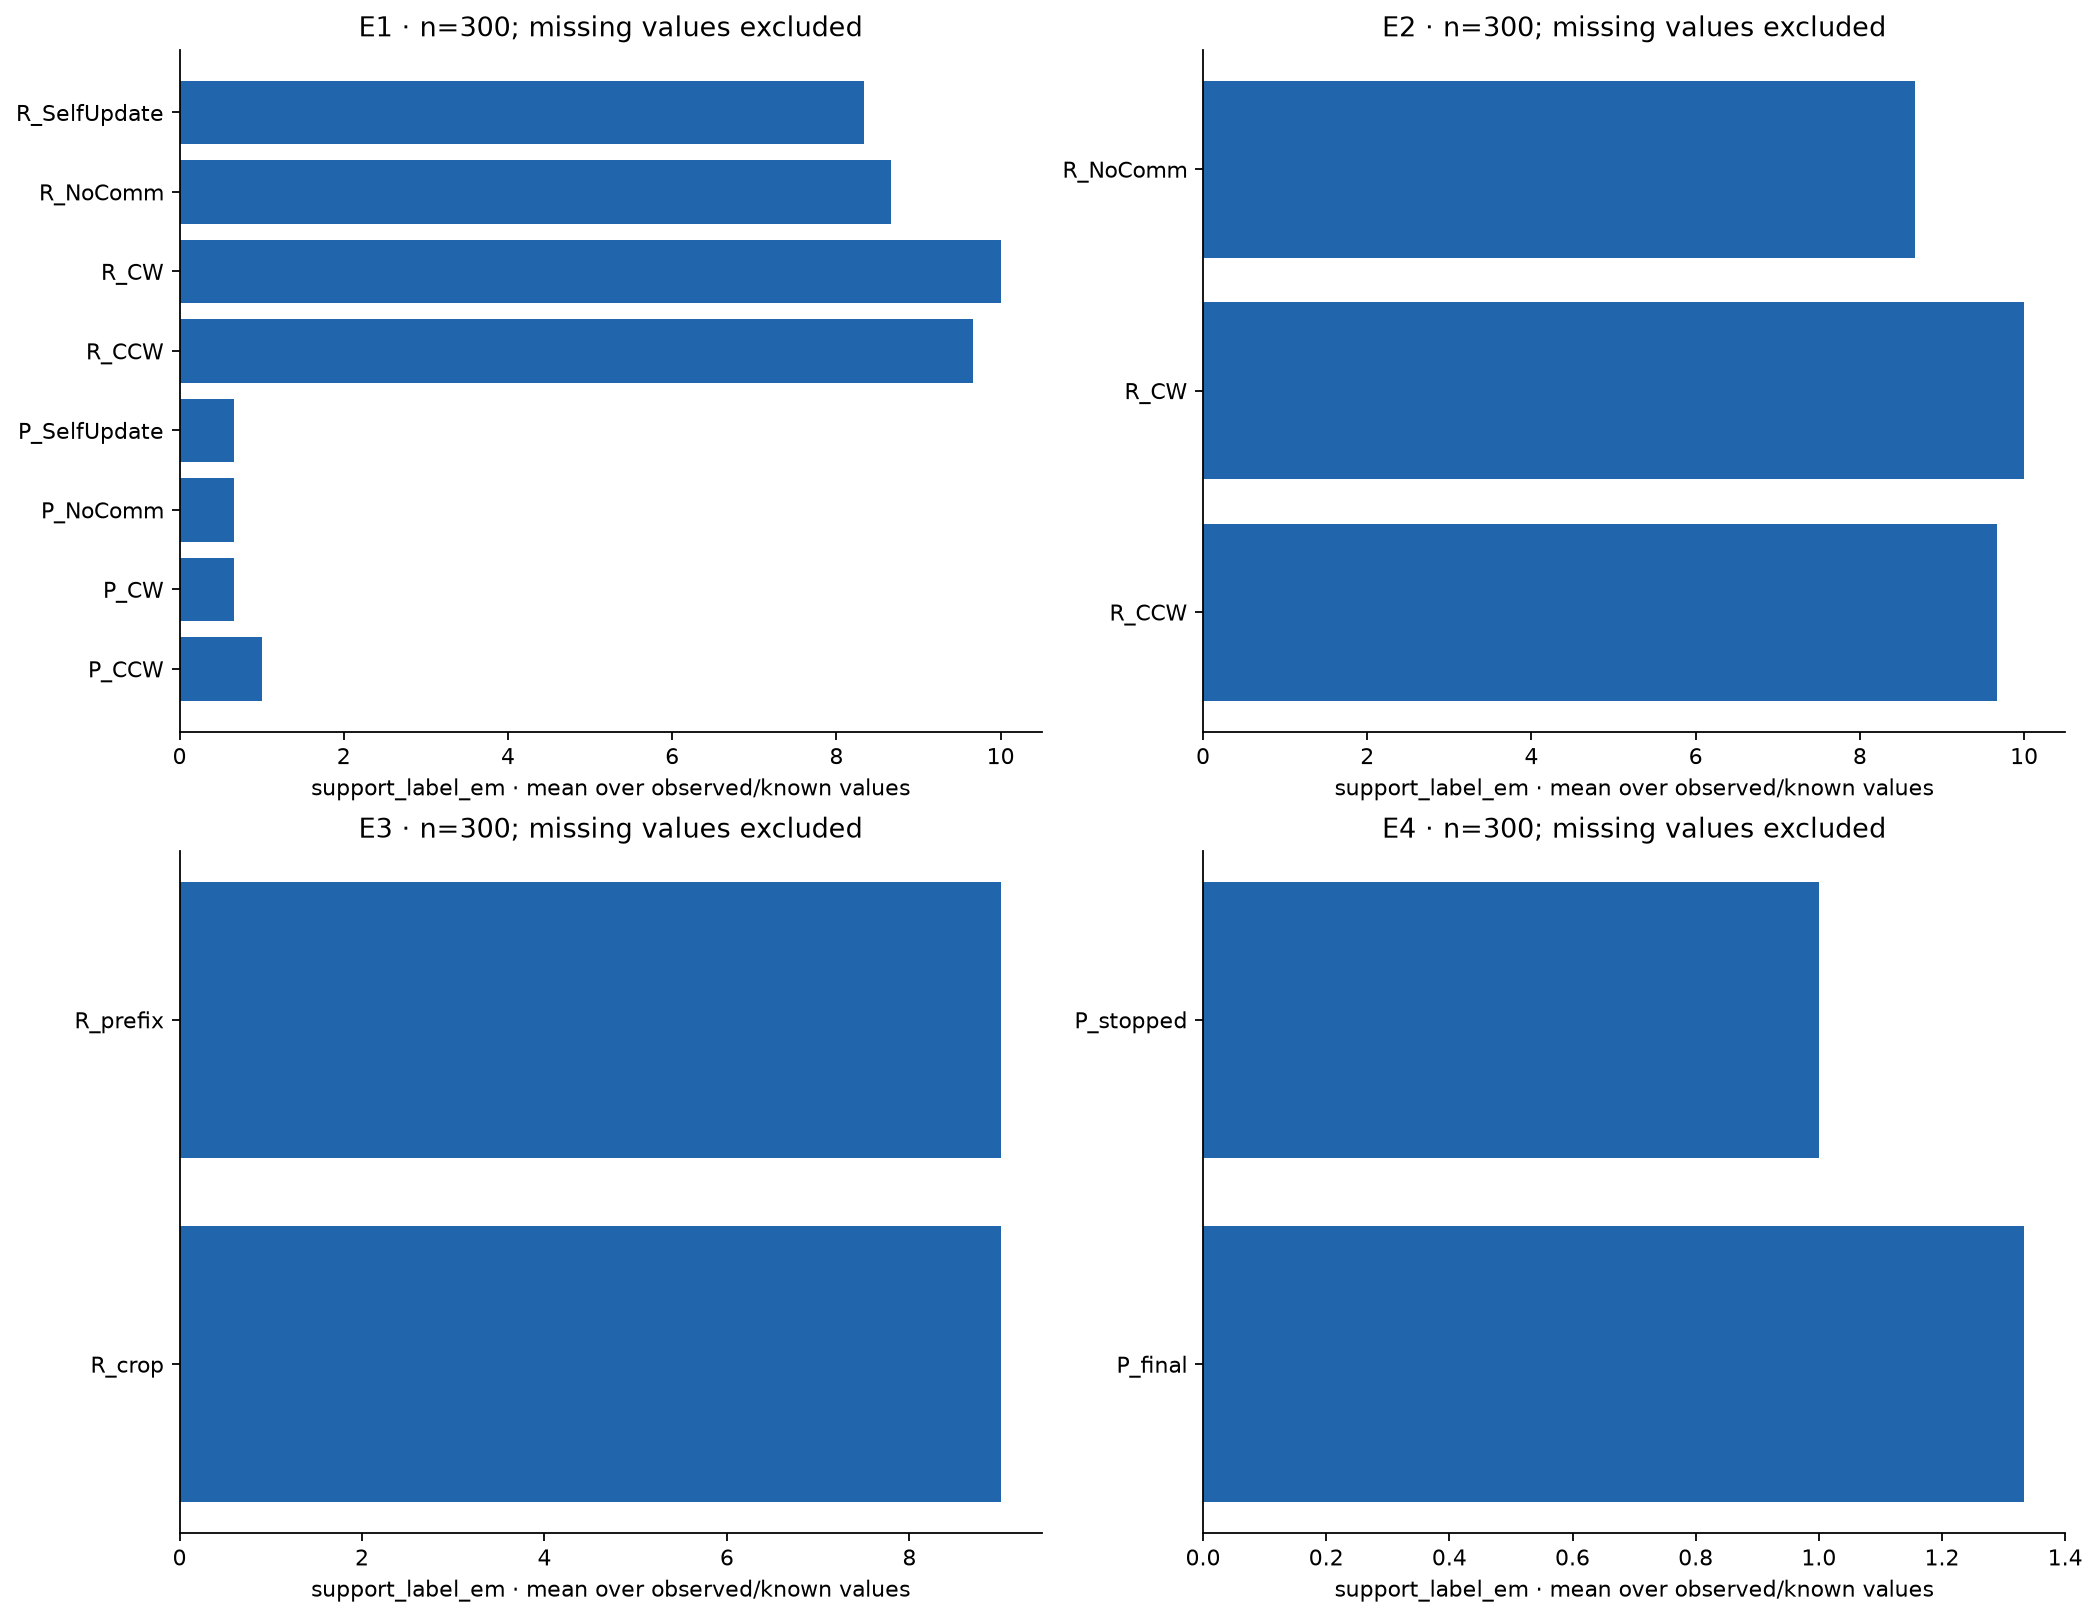

### metric support label f1

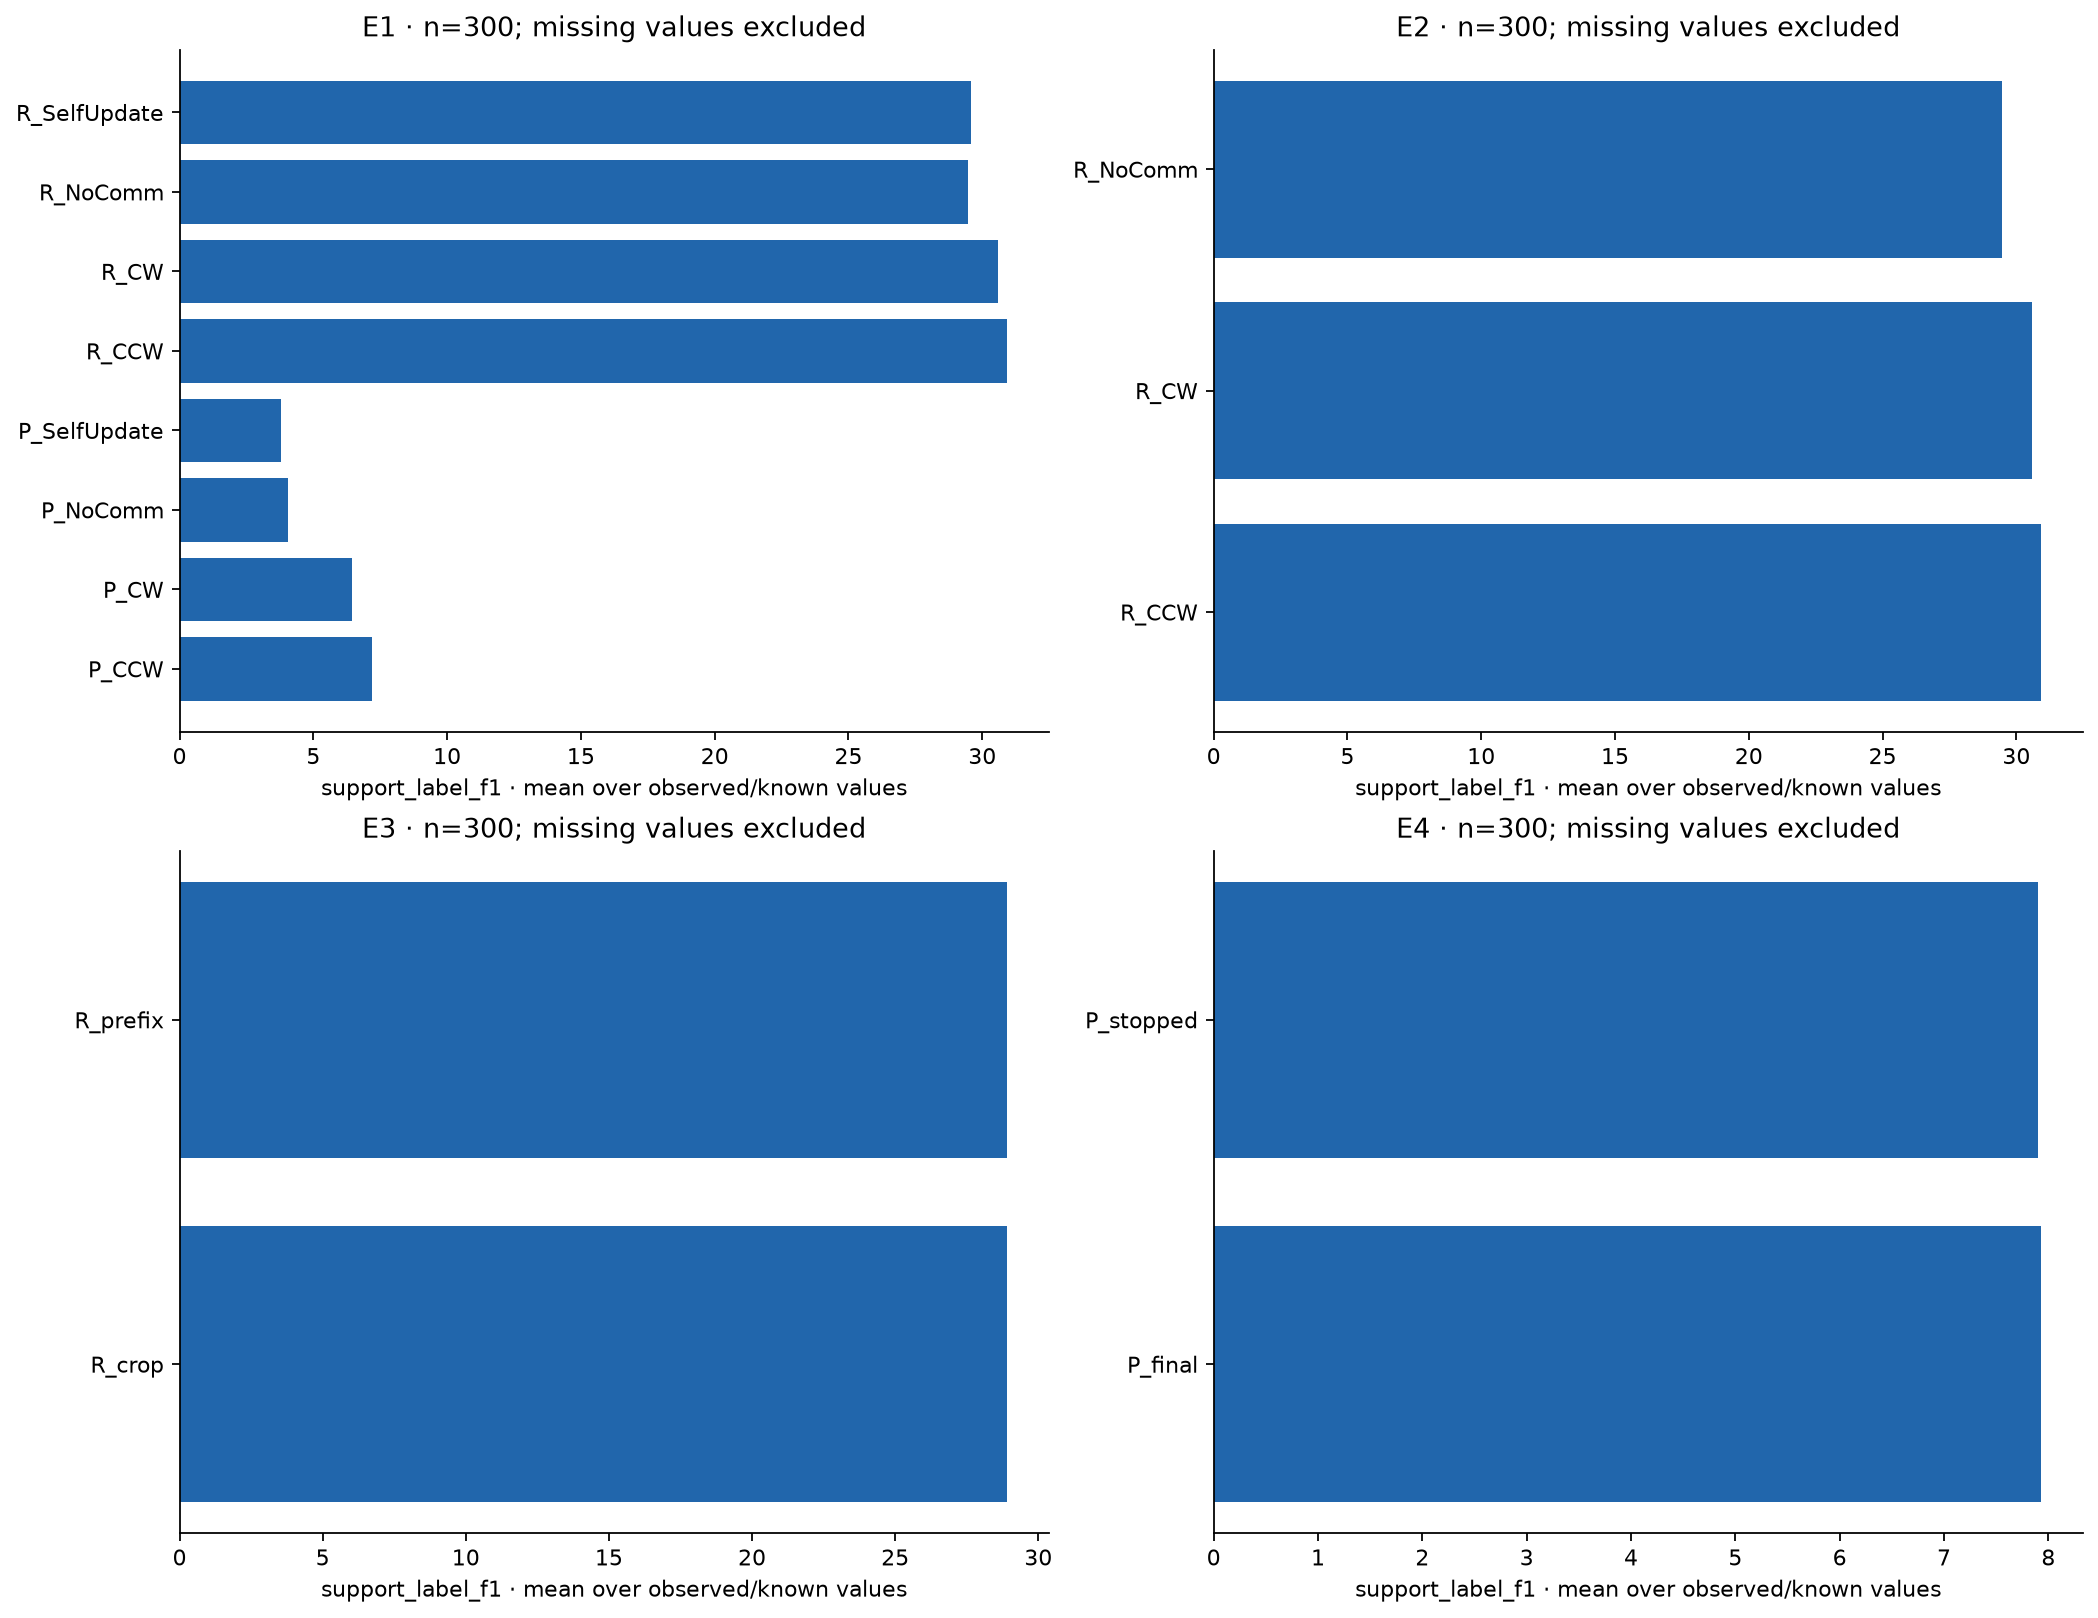

### metric usage complete

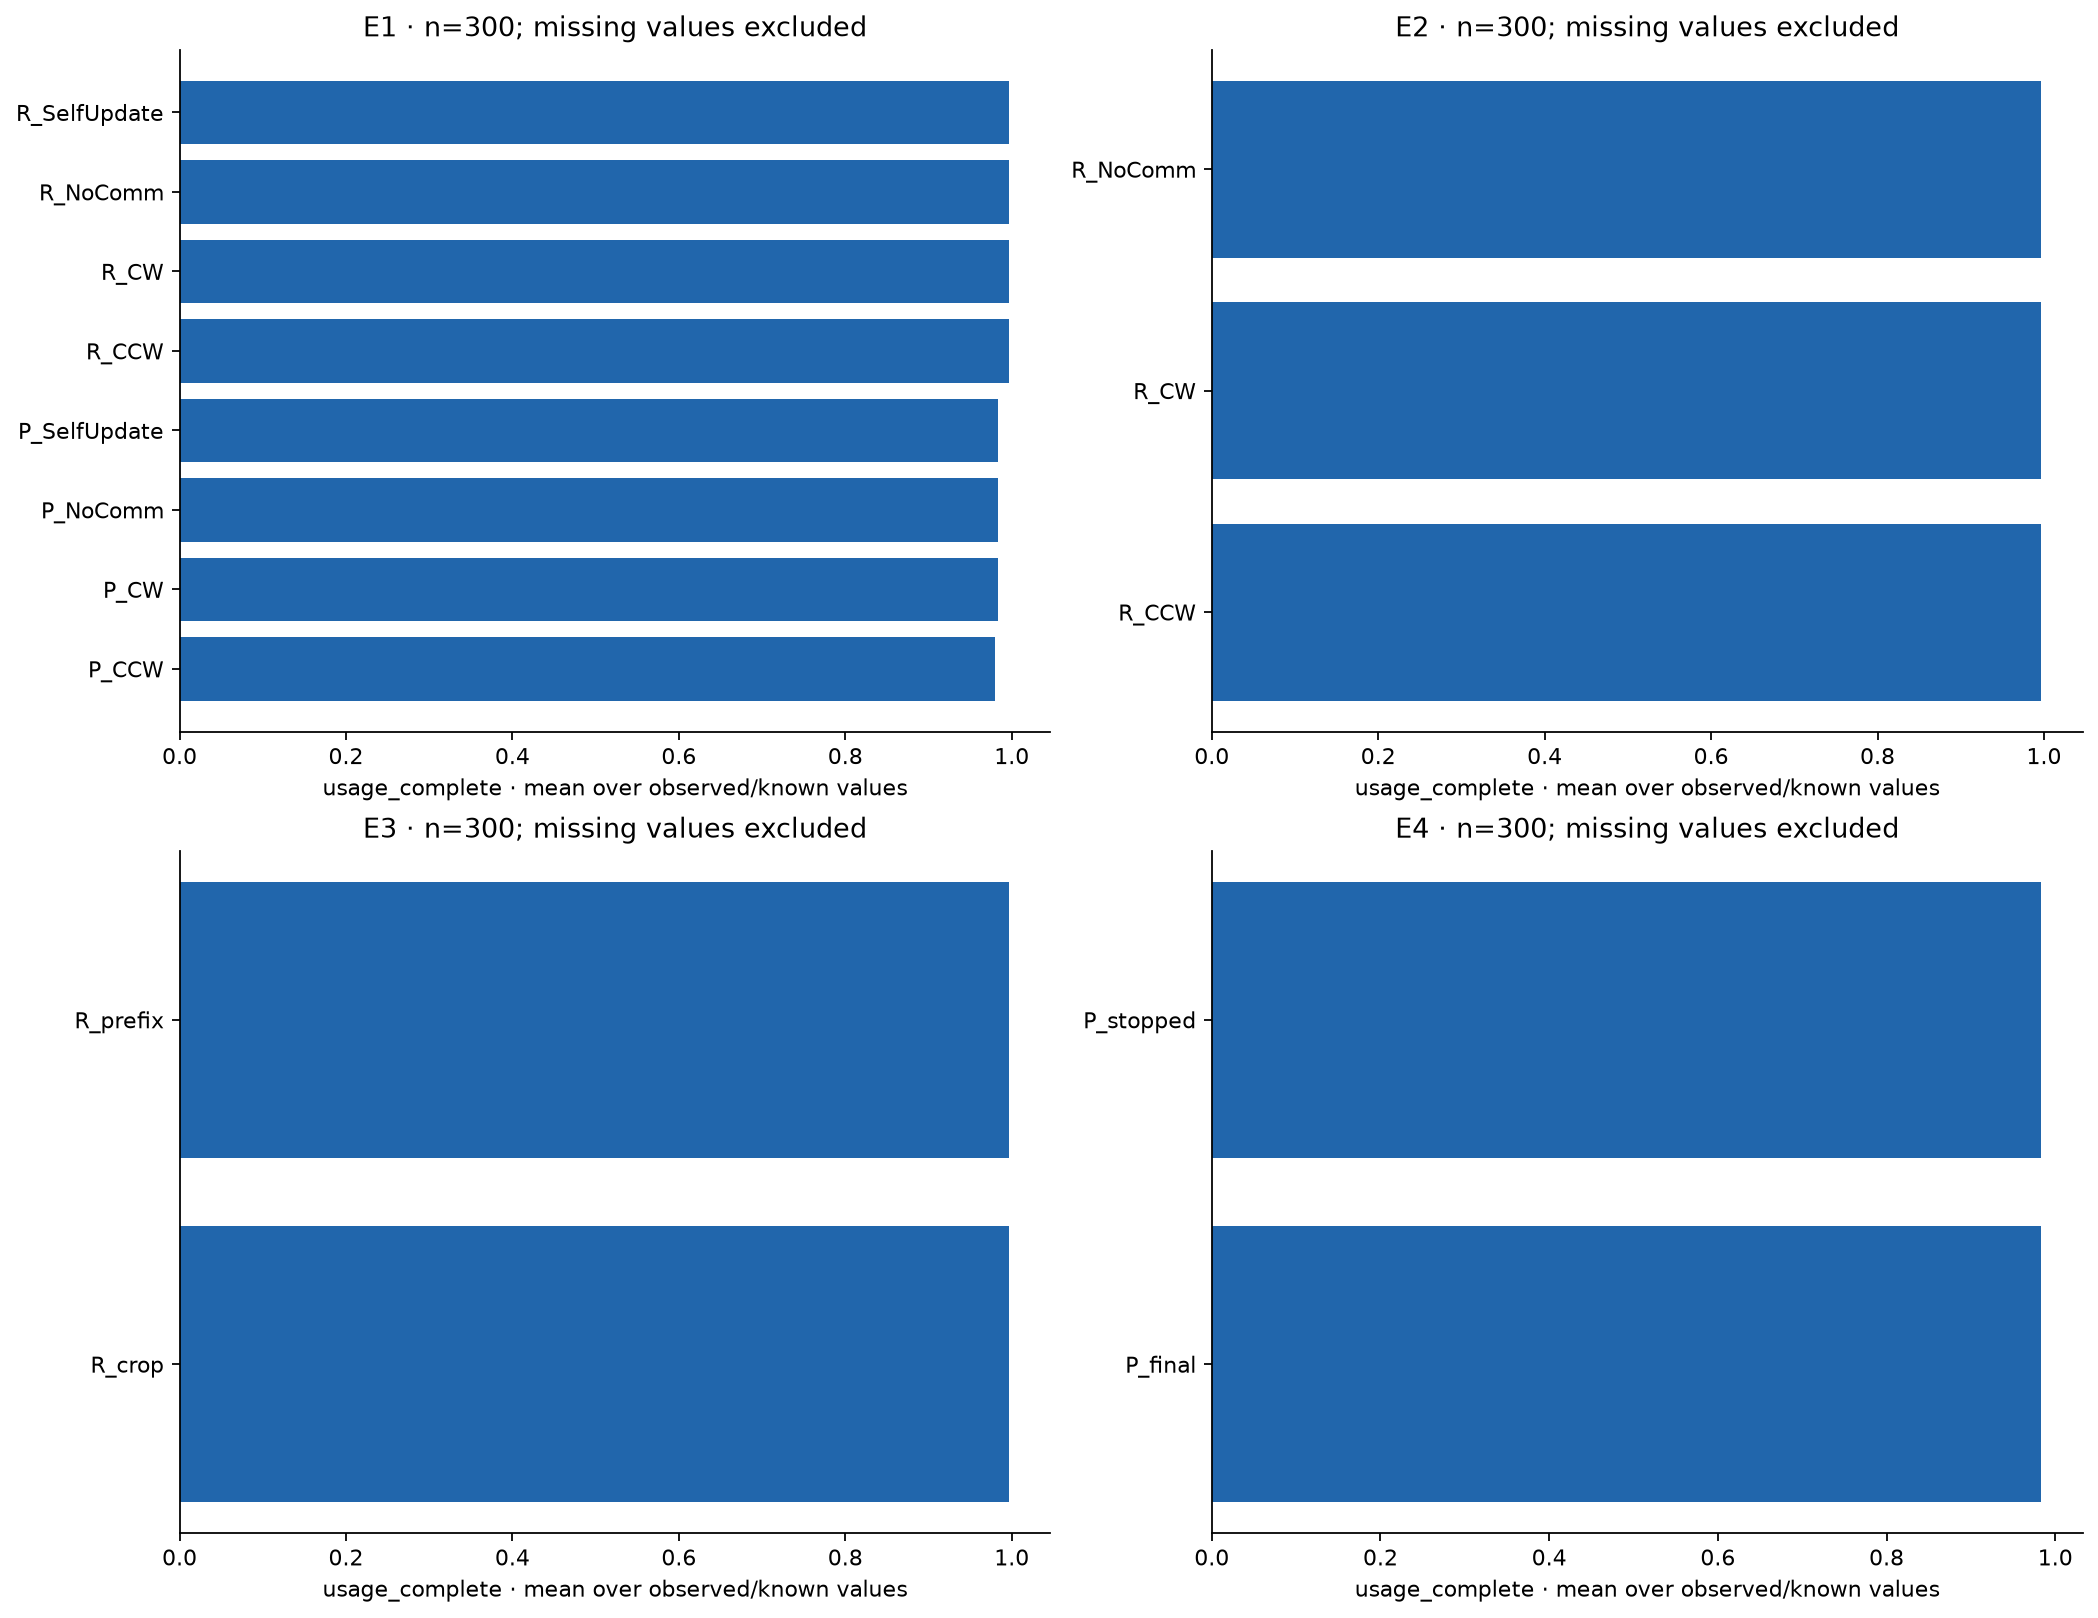

### metric utility gain

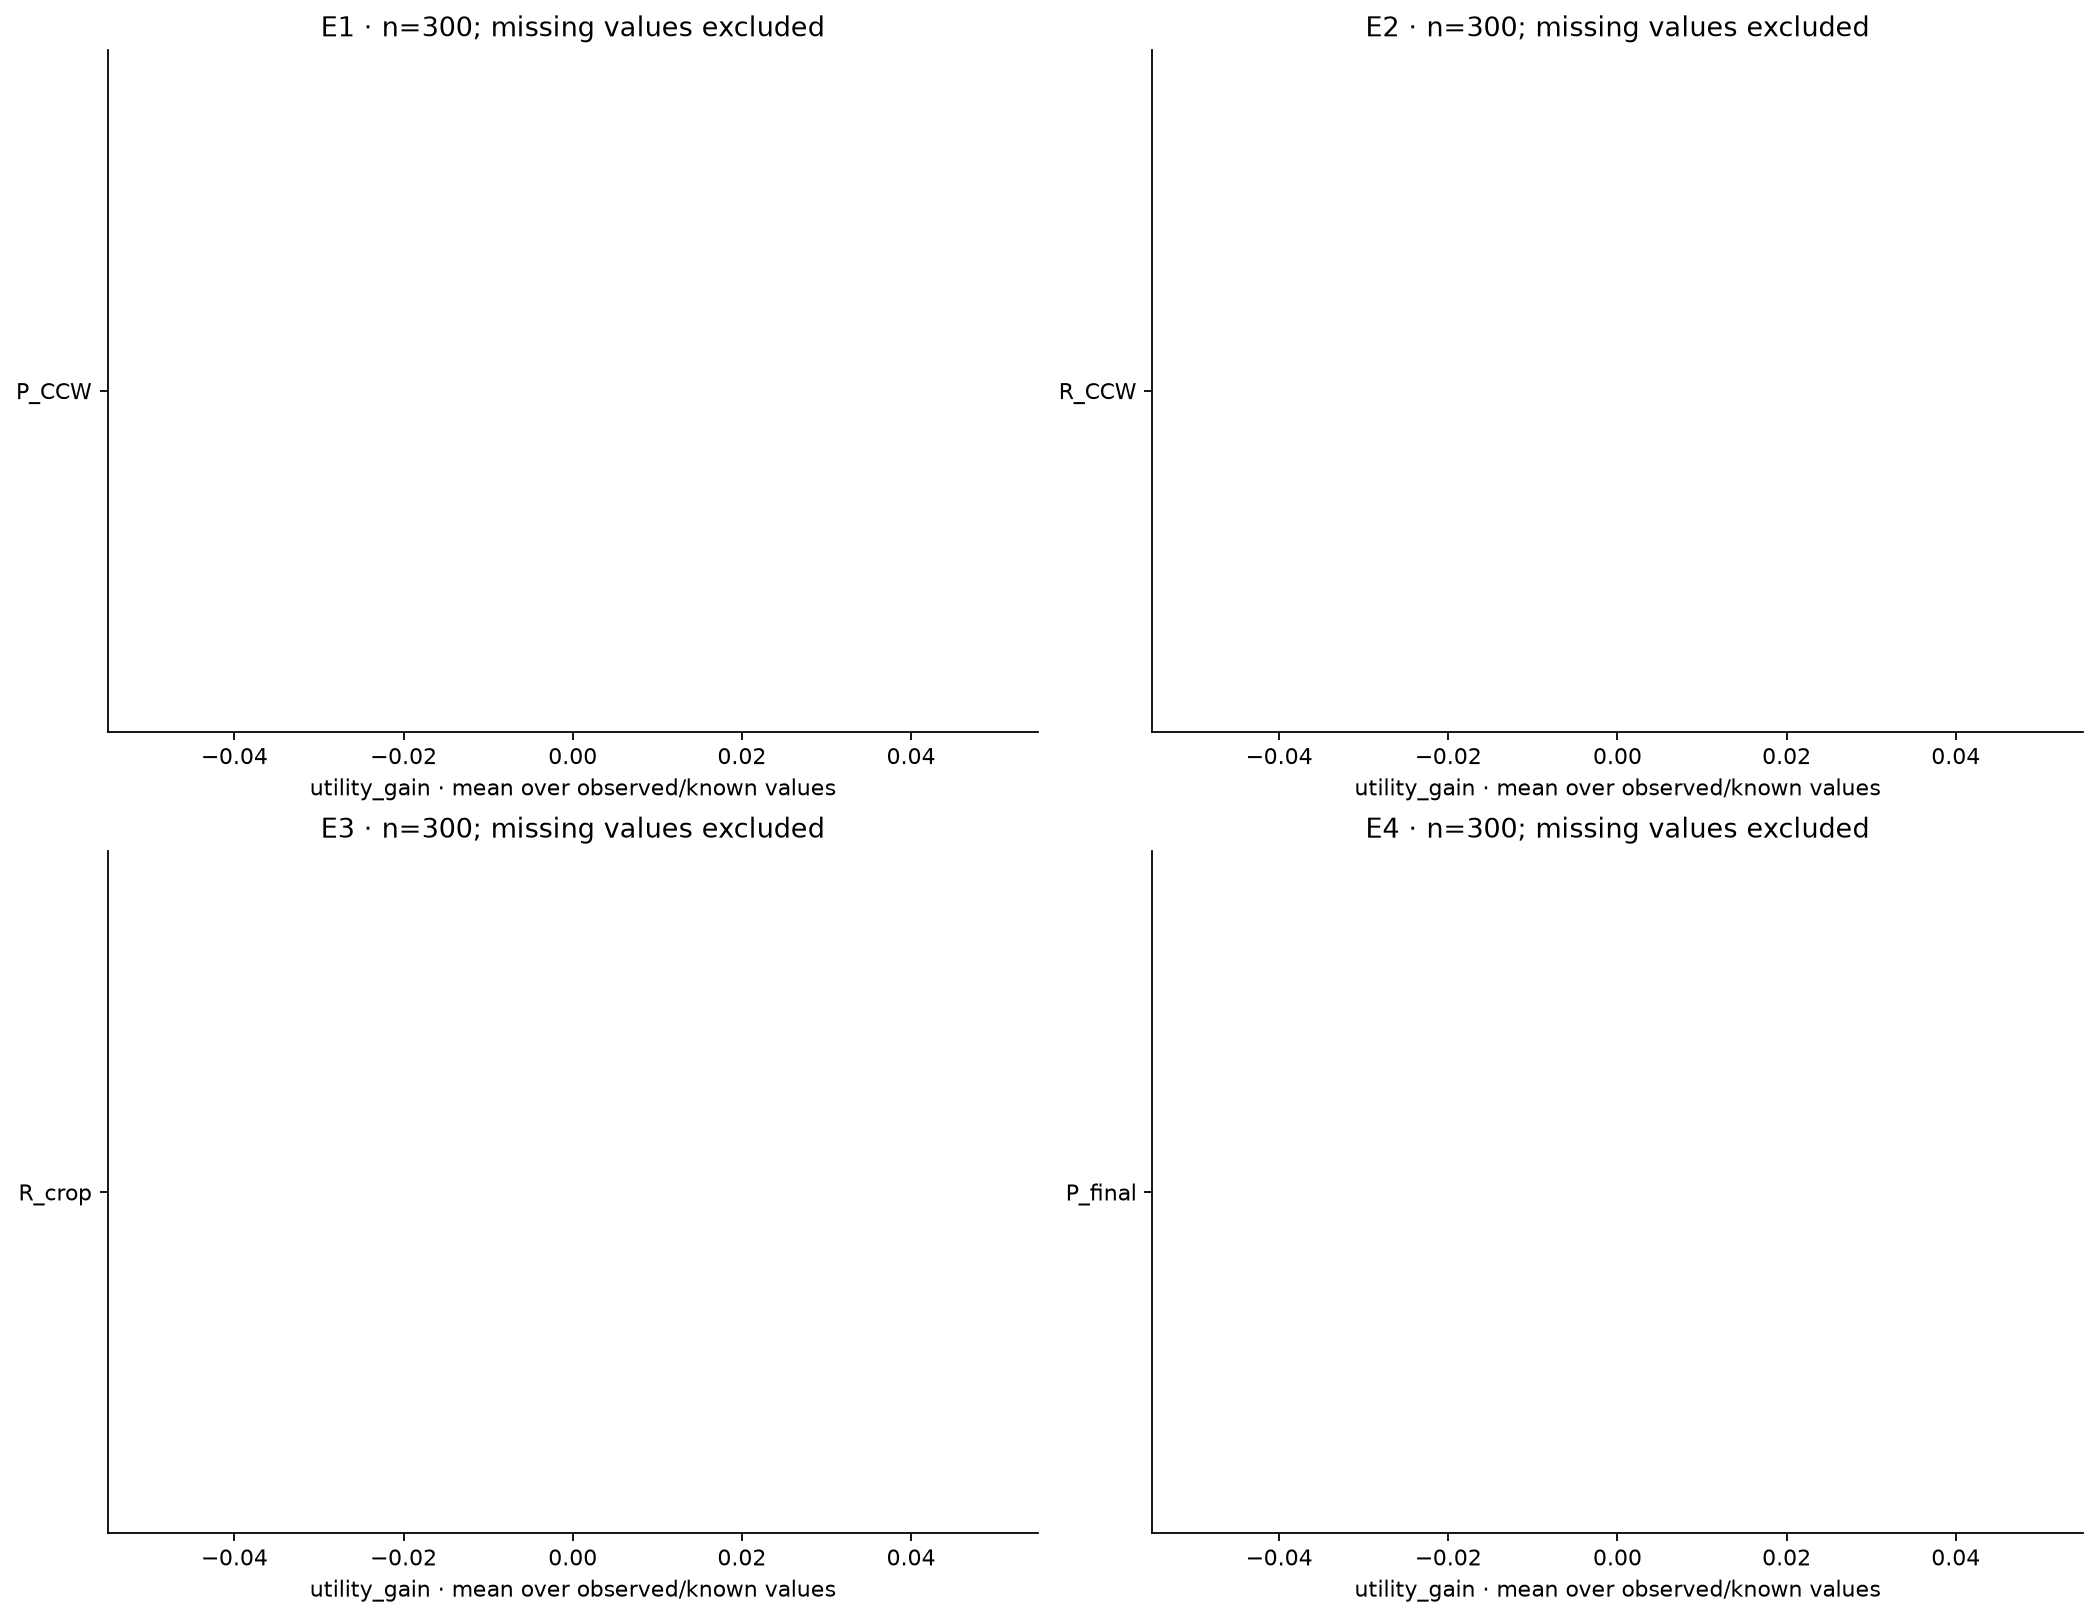

In [8]:
for path in sorted((REVIEW/'figures').glob('metric_*.png')):
    display(Markdown('### '+path.stem.replace('_',' ')))
    display(Image(filename=str(path),width=1000))

## Full evidence-based readiness report

In [9]:
display(Markdown((REVIEW/'PUBLICATION_READINESS_REPORT.md').read_text()))

# SparseComm saved-results audit and publication readiness

Audit snapshot: 2026-10-14T14:16:19.607263+00:00. All analysis uses saved authentic artifacts. Automatic recovery is paused; no experiment services are loaded. This analysis issued **zero inference calls**.

**Verdict: not ready for a strong WWW 2027 research submission as currently framed.** E1–E4 are complete and internally authenticated. E5 has only 129/300 completed questions; no missing results were filled. A null primary result alone does not make research unpublishable. Here the incomplete test, degenerate manipulation and generalizability gaps jointly block readiness. There is useful empirical evidence about evidence availability, but the main interaction remains inconclusive, the content contrast mostly did not change messages, and learned-policy claims need a complete test and careful resource/adaptivity limits.

## 1. Evidence scope and independent verification

- E1–E4 each have exactly 300 unique frozen question IDs. Their saved SHA256 values match completion manifests.
- E5 has exactly 129 unique frozen test IDs, with all 20 required arms per saved question. It is an interrupted prefix, not a completed test.
- All recorded answer F1/EM values in E1–E5 match the provided upstream HotpotQA reference scorer: **zero mismatches**. The reference file is copied and hashed in `sources/`. Supporting-label and joint-label diagnostics were newly derived from the saved ensemble/citation unions and are NOT sentence-entailment evaluations or a leaderboard submission.
- Every unique recorded payload was recounted with the pinned GPT-OSS tokenizer: **zero token-count mismatches**.
- Frozen scientific source hashes and all three selected checkpoint hashes match. No training, data resampling or model invocation was performed during this audit.
- Graph discovery has no current tracked coverage for WEBExtension (generation 2026-10-13T17:28:45Z); direct-source checks support this bounded audit. Index cleanliness is not asserted as proof of completeness.

## 2. Complete experiments: quality and resources

F1 and EM are on a 0–100 scale. R means redundant evidence; P means exclusive partitioned evidence. Logical calls include shared initial inference; they must not be summed across overlapping arms as physical charges.

| Experiment | Condition | n | Mean F1 | EM | Payload tokens/question | Logical calls/question |
|---|---|---:|---:|---:|---:|---:|
| E1 | P_CCW | 300 | 9.040 | 6.333 | 66.800 | 6.000 |
| E1 | P_CW | 300 | 9.133 | 6.667 | 66.800 | 6.000 |
| E1 | P_NoComm | 300 | 5.267 | 3.667 | 0.000 | 3.000 |
| E1 | P_SelfUpdate | 300 | 5.756 | 3.667 | 0.000 | 6.000 |
| E1 | R_CCW | 300 | 32.839 | 24.000 | 145.163 | 6.000 |
| E1 | R_CW | 300 | 32.732 | 24.333 | 145.163 | 6.000 |
| E1 | R_NoComm | 300 | 31.748 | 22.667 | 0.000 | 3.000 |
| E1 | R_SelfUpdate | 300 | 32.089 | 23.667 | 0.000 | 6.000 |
| E2 | R_CCW | 300 | 32.839 | 24.000 | 145.163 | 6.000 |
| E2 | R_CW | 300 | 32.732 | 24.333 | 145.163 | 6.000 |
| E2 | R_NoComm | 300 | 31.748 | 22.667 | 0.000 | 3.000 |
| E3 | R_crop | 300 | 31.490 | 23.333 | 47.277 | 4.000 |
| E3 | R_prefix | 300 | 31.635 | 23.333 | 47.277 | 4.000 |
| E4 | P_final | 300 | 10.772 | 7.667 | 216.310 | 12.000 |
| E4 | P_stopped | 300 | 10.772 | 7.667 | 200.627 | 11.820 |

## 3. Primary and secondary inference

The frozen primary contrast `(CW−NoComm)_P − (CW−NoComm)_R` is **2.882 F1 points**, 95% question-bootstrap CI **[-0.260, 6.011]**, paired sign-randomization **p=0.0713**. The interval includes zero. Do not describe the primary moderator hypothesis as confirmed or replace it with a more favorable subgroup after observing results.

| Contrast | Effect (F1 points) | 95% CI | Raw p | Original Holm p |
|---|---:|---|---:|---:|
| E1 (CW-NoComm)_P - (CW-NoComm)_R | 2.882 | [-0.260, 6.011] | 0.0713 | unknown |
| E1 R_CW - R_NoComm | 0.985 | [-0.768, 2.893] | 0.2955 | 0.858 |
| E1 P_CW - P_NoComm | 3.866 | [1.356, 6.486] | 0.0015 | 0.009 |
| E1 R_CCW - R_NoComm | 1.091 | [-0.801, 3.144] | 0.2860 | 0.858 |
| E1 P_CCW - P_NoComm | 3.773 | [1.421, 6.354] | 0.0024 | 0.012 |
| E1 R_CW - R_SelfUpdate | 0.644 | [-0.871, 2.215] | 0.4210 | 0.858 |
| E1 P_CW - P_SelfUpdate | 3.377 | [0.849, 6.053] | 0.0110 | 0.044 |
| E2 R_CW - R_CCW | -0.107 | [-1.476, 1.147] | 0.8801 | 0.880 |
| E3 R_prefix - R_crop | 0.145 | [-0.136, 0.571] | 1.0000 | 1 |
| E4 P_stopped - P_final | 0.000 | [0.000, 0.000] | 1.0000 | 1 |

Partitioned CW improves on NoComm and SelfUpdate in secondary contrasts. This supports a conditional observed gain within P; it does not prove that P improves communication gains more than R. E2 routing and E3 content estimates do not establish equivalence. Added `holm_across_completed_secondary_contrasts` values are a separately labeled multiplicity sensitivity; they do not silently replace the original analysis families.

## 4. Gold-location strata and retrieval availability

**62 Disjoint-Gold, 14 Co-located-Gold, 224 Retrieval-Missing-Gold.** Both labelled gold articles are present in only 79/300 publisher candidate contexts, and in 76/300 top-6 pools. Thus most absent-gold cases originate in supplied fullwiki candidates, rather than being caused by the additional top-6 selection. These are real publisher fullwiki candidate contexts; the assertion that every question contains two gold articles plus eight distractors does not describe this sample.

A missing gold article does not prove that every possible answer cue is absent: backbone knowledge and non-gold passages may still help. The diagnostic specifically measures availability of annotated gold evidence.

| E1 exploratory stratum contrast | Stratum | n | Effect | 95% CI | Raw p | Report Holm p |
|---|---|---:|---:|---|---:|---:|
| P_CW - NoComm | Disjoint-Gold | 62 | 10.311 | [1.111, 20.167] | 0.0398 | 1.0000 |
| P_CW - NoComm | Co-located-Gold | 14 | 17.857 | [0.000, 39.286] | 0.2502 | 1.0000 |
| P_CW - NoComm | Retrieval-Missing-Gold | 224 | 1.208 | [-0.348, 3.022] | 0.1672 | 1.0000 |
| (CW-NoComm)_P - (CW-NoComm)_R | Disjoint-Gold | 62 | 12.200 | [2.681, 22.301] | 0.0169 | 0.4563 |
| (CW-NoComm)_P - (CW-NoComm)_R | Co-located-Gold | 14 | 10.317 | [-14.286, 34.921] | 0.6211 | 1.0000 |
| (CW-NoComm)_P - (CW-NoComm)_R | Retrieval-Missing-Gold | 224 | -0.163 | [-2.831, 2.451] | 0.9055 | 1.0000 |

The Disjoint-Gold point estimates are larger, but post-hoc subgroup inference has low effective n and does not pass the stored familywise adjustment. Co-location n=14 is particularly uncertain. Stratum membership is observational; its heterogeneity interval does not identify a randomized causal contrast between strata. The real 2/2/2 shard design has a 20% same-shard probability conditional on both gold articles being retained, not the 3/3/4 ten-document probability. Gold labels were used offline here, not to choose controller inputs/actions.

## 5. Manipulation checks and experimental overlap

- **E2:** CW/CCW have identical source payload amounts and calls, isolating one-step destination allocation in R. E2 reuses the same provider keys and scientific outcomes as E1 R; it is a mechanistic reanalysis, not another independent 300-question replication. Execution/cache metadata differs between full records.
- **E3:** 298/300 questions have identical prefix/crop payloads and receiver keys. Only two questions instantiate a content intervention. Exact budget matching passes, but this result cannot show content-insensitivity or compression equivalence. Do not drop the 298 identical questions and relabel the two changing cases as a new primary test.
- **E4:** stopping depths are {'3': 290, '2': 5, '0': 3, '1': 2}; only 10/300 stop before depth3. Six of these10 early consensuses are wrong. Continuing corrects none of those6 in this sample. All300 stopped/final F1 values coincide, but 0 answer strings differ. The total is54/3600 hypothetical calls avoided (**1.5%**) and 7.25% offline payload reduction. Full trajectories were actually generated, so these are replay counterfactuals, not realized monetary or wall-time savings. No justified noninferiority margin was predeclared.
- **Intentional overlap:** the same 300 test questions occur in E1–E4; E5 uses a129-question prefix of the same frozen test population. Pairing improves contrast efficiency. Do not count1200 or900 independent questions. Reusing training/validation questions across epochs and seeds is intentional and disclosed.

## 6. Train/validation/test leakage audit

The active study has100 training,30 validation,300 heldout and12 pilot questions. All6 partition pairs have **zero ID overlap, zero normalized-question overlap, and zero normalized candidate-title overlap**. Within-partition IDs/questions are unique. The100/30 subsets were selected using fixed type-stratified ID hashing without inspecting predictions/scores. Heldout input and gold bytes match the original300/100 study. Type counts: train80 bridge/20 comparison; validation24/6; heldout240/60.

No overt gold/correctness/ID-hash feature is present in `observable_features`. Gold informs offline rewards and validation selection, which is appropriate; inference/actor features are whitelisted. The actual categorical contextual-bandit PPO controller is not an architecture-compatible continuation of the original continuous SparseComm controller and does not train multi-round stopping.

Zero measured overlap is not a guarantee against document aliases, semantic duplicates, older undisclosed evaluations or model pretraining contamination. Title filtering changes representativeness. Training and heldout candidate-retrieval distributions differ. Record these limits rather than claiming universally leakage-free evaluation.

## 7. E5 preliminary trend: explicitly incomplete

All three optimizer seeds completed three epochs, 200 R/P training contexts and60 validation contexts each epoch (1800 train rollouts,540 validation records; only100/30 unique questions). Validation communication utility selects checkpoints, not test F1. Selected epochs: seed7 epoch1, seed19 epoch3, seed31 epoch3.

**The following figures and numbers use only129/300 completed test questions. They cannot support final300-question or publication claims.** Missing rows were not assigned zero, imputed or fabricated. `E5_partial_missing_data_bounds.csv` gives deliberately broad0–100 worst/best-case bounds for the unobserved171 questions.

| Partial contrast, seeds averaged within question | Effect | 95% exploratory CI | n |
|---|---:|---|---:|
| R_seed_mean_Learned - NoComm | -0.543 | [-2.631, 1.470] | 129 |
| R_seed_mean_Learned - SelfUpdate | 0.281 | [-2.117, 2.703] | 129 |
| R_seed_mean_Learned - Static | 0.322 | [-2.085, 2.860] | 129 |
| R_seed_mean_Learned - Broadcast | 0.220 | [-1.699, 2.148] | 129 |
| R_seed_mean_Learned - MatchedRandom | 0.005 | [-1.243, 1.255] | 129 |
| P_seed_mean_Learned - NoComm | 7.836 | [4.439, 11.755] | 129 |
| P_seed_mean_Learned - SelfUpdate | 6.470 | [2.159, 10.799] | 129 |
| P_seed_mean_Learned - Static | 6.479 | [2.707, 10.214] | 129 |
| P_seed_mean_Learned - Broadcast | -5.335 | [-8.337, -2.560] | 129 |
| P_seed_mean_Learned - MatchedRandom | 2.183 | [0.828, 3.918] | 129 |

On this prefix, P learned policies improve over NoComm but their seed mean underperforms Broadcast; R seed-mean quality is slightly below NoComm while using more calls/payload. This is a resource/quality tradeoff, not evidence of blanket dominance. Seed7 P is almost Broadcast; seed31 P chooses a single action on129/129 questions. Do not claim robust task-adaptive routing from three seeds alone.

**MatchedRandom caveat:** all774 learned/random comparisons match declared edge count andquota, but397 differ in logical recipient calls and114 differ in actual transmitted tokens. A fan-in may update one recipient while another two-edge graph updates two. This baseline is not exact recipient-call/token matched and cannot isolate a pure routing effect.

E5 response namespace differs from E1. Same-question baseline answer differences are recorded in `cross_suite_same_question_baselines.csv`; do not pool suites as independent replications or assume identical teacher draws. Controller optimizer seeds share real cached teacher responses where prompts match and are not independent model backbones.

## 8. Physical cost, refusals, timing and unknowns

The original cost reporting function suppresses both input/output totals if any successful output count is missing. This audit preserves the original reports and correctly reports dimensions independently. Known sums are not fabricated complete bills.

| Active pipeline | Returned successful responses | Known input tokens | Output lower bound | Successful responses missing output usage | Original unresolved attempt liabilities |
|---|---:|---:|---:|---:|---:|
| controlled | 6134 | 5,960,203 | 1,582,163 | 29 | 8 |
| controller | 5725 | 5,748,101 | 1,511,822 | 27 | 4 |

Across all preserved WEBExtension ledgers—including archived caps, pilot and prior study—de-duplication by original attempt ID gives 13,666 attempts: {'success': 13632, 'rejected': 21, 'uncertain': 13}. Reported input-token lower bound **13,333,177**, output-token lower bound **3,535,121**. There are 34 missing input-usage records and 91 missing output-usage records. This global scope is not just the active primary protocol and must not be confused with logical per-arm costs.

Refusals remain explicit abstentions with original provider bodies and reported usage; unavailable usage remains unknown. These quality results describe the deployed endpoint including its safety-filter policy, not unconstrained model capability. Call counts differ across some arms, so refusal opportunities may differ as well; the call-matched SelfUpdate control is especially relevant. Provider500/connection/timeouts may have been billed before a response reached disk. Retry authorization never marks those originals as ungenerated. Imported successful responses retain the original cost-owner ledger and are not charged again merely because a new study reads them.

No verified deployment price/billing export is available, so total currency cost and savings are **not calculable** from these artifacts. Do not substitute a public list price for this deployment without verifying billing terms.

Network timing quantiles and worker-session start/end durations are in separate tables. Queue/cache/end-to-end times and nested stage timers overlap; do not sum nested timers as independent wall time. Timings cover captured operational sessions, not unobserved server compute or lost historical spans. No clean arm-randomized end-to-end runtime benchmark exists here. Automatic recovery improved throughput but is not an experimental treatment latency effect.

## 9. Publication readiness and actionable priorities

1. **Complete the frozen E5 heldout evaluation** before reporting a learned-controller result. Keep selected checkpoints unchanged; do not tune after looking at the partial test results.
2. **Repair/reframe the content question.** The current E3 has only2 actual message changes. Preserve it as a failed/degenerate manipulation and, if new experiments are authorized, preregister a separate meaningful content intervention on new authentic data with sufficiently long messages and exact budgets. Do not overwrite the current result.
3. **Make evidence-availability scope explicit.** Only76/300 selected pools contain both gold articles. A fresh authentic distractor/full-availability protocol can test complementary transfer more directly; this requires a separate frozen dataset/run, not gold-aware post-hoc repair of the current primary sample.
4. **Strengthen generalizability.** One model deployment, one benchmark and one primary evidence-partition seed do not establish robustness. Three optimizer seeds do not substitute for independent partition seeds, backbone models or benchmarks. Additional runs are not performed by this audit.
5. **Match resources for causal topology claims.** Either use recipient/call/payload-matched controls or state that E5 compares whole policies with measured resource differences. Keep E2 restricted to one-step destination allocation.
6. **Report known costs and unknown liabilities separately**, publish the correction alongside the original incomplete cost summaries, and verify entitlement/billing before monetary claims.
7. **Align the paper to the actual implementation.** The locally found `PaperOctVersion/Paper6Oct.tex` describes the prior closed-book/continuous SparseComm work; no verified current WWW manuscript tied to these300-question artifacts was identified. The June2026 `SparseComm_Research_Paper.md` also describes continuous edge weights, semantic masking and theoretical/topological claims outside this new categorical-bandit study. Its earlier accuracy/saving claims were not validated by this Web audit and cannot be transferred to these results. Existing dossier headings asserting “100% verified” are claims in those documents, not independent evidence. A submission-ready prose/novelty/page-limit/citation audit of the final manuscript remains outstanding.
8. **Novelty is not certified.** The current blueprint positions an empirical evidence-availability paper, not a state-of-the-art RL router. A full current literature comparison and proof that the Web-specific research challenge is substantive remain necessary.

The official [WWW2027 research-track call](https://www2027.thewebconf.org/research-track-papers/) requires explicit Web/track relevance on the first page and warns that merely using a Web dataset/API is insufficient. Candidate-based multi-hop Web evidence delivery is a plausible research focus, but the abstract must state the scientific challenge, the tested estimand and the actual uncertainty. Listed deadlines were18 October2026 for abstracts and25 October2026 for full papers (AoE), checked during this audit. Acceptance remains a peer-review decision, not something these software checks can guarantee.

## 10. Claim-support map

| Proposed claim | Evidence judgment |
|---|---|
| Communication has a confirmed larger benefit with partitioned evidence | Not confirmed by the pooled primary interaction; report estimate andCI. |
| Communication helps the Disjoint-Gold cases massively | Larger exploratory point estimate, low n, multiplicity adjustment not passed; avoid “massive”. |
| Prefix/crop are equivalent or content does not matter | Unsupported: 298/300 payloads identical; only2 informative pairs. |
| Adaptive stopping preserves correctness and saves real money/time | Unsupported generally; exact observed F1 tie, six wrong early consensuses, small hypothetical savings only. |
| Learned SparseComm robustly outperforms baselines | Incomplete test; partial policies have broadcast tradeoffs and static behavior. |
| MatchedRandom isolates routing at identical resource costs | False for actual calls/tokens; only edgecount/quota matched. |
| Training/testing have no measured overlaps | Supported for exact ID/question/title tests; semantic/pretraining contamination unverified. |
| Results are authentic, internally consistent and reproducible from saved artifacts | Strong internal provenance/scoring/hash evidence; immutable provider snapshot and full external rerun remain unavailable. |

## 11. Available metrics, plots and reproducibility

All recorded scalar quality, grounding-label, transmission, invocation, refusal, cache and utility metrics are in `tables/all_condition_question_metrics.csv`; their per-arm summaries, missingness and full distribution profiles are supplied. Official-style supporting/joint-label metrics are explicitly diagnostic. Paired F1/EM transition records, stratum effects, learning curves, action entropy/dominance, resource matching, source retrieval counts, physical attempt provenance, latency quantiles and missing-test bounds are supplied separately.

The figures include13 core research panels, optimizer diagnostics and individual panels for every additional recorded scalar condition metric. All figures are exported as PNG and vector PDF, with constrained layouts and separate legends. Some exact data points naturally coincide; plotting does not add artificial jitter or change the values. No title/legend/axis overlap was observed in the reviewed core renders.

Run the two saved analysis scripts offline using `HF_HUB_OFFLINE=1`; they do not instantiate a model provider. The companion notebook opens the already-calculated metrics and figures by default. Recalculation is opt-in and writes only derived audit files. Keep the source result/checkpoint artifacts intact. `analysis_artifact_manifest.json` hashes inputs and every derived file.

## 12. Adversarial self-review

- **Contribution:** There is a defensible empirical audit of evidence availability and delivery, but superiority/novelty is not established.
- **Clarity:** Distinguish answerF1 from supporting-label overlap, P fromR, complete tests frompartial prefixes, and actual bills fromlogical/counterfactual costs.
- **Experimental strength:** Complete paired E1–E4 are internally verified; E3 manipulation degeneracy and smallgold strata are substantial limitations.
- **Completeness:** E5 and robustness replication remain incomplete; no final controller claim or publication-readiness certification is justified.
- **Method soundness:** No overt gold-feature leakage and exact split checks pass; controller scope, static degeneration, namespace reuse and imperfect matched controls require explicit disclosure.

## 13. Verified external references

- [Official HotpotQA evaluator](https://github.com/hotpotqa/hotpot/blob/master/hotpot_evaluate_v1.py): answerF1/EM and supporting/joint metric definitions. Local reference hash is recorded in the audit manifest.
- [HotpotQA dataset and official setting descriptions](https://hotpotqa.github.io/): distinguish candidate evaluation from full Wikipedia/live browsing.
- [WWW2027 research-track requirements](https://www2027.thewebconf.org/research-track-papers/): scope/relevance/deadlines, consulted14 October2026.

The supplied blueprint and pasted strategy are treated as research plans and claims to test, not as evidence that experiments ran or permission to fabricate favorable outcomes.


## Optional offline recomputation

Default is false. This recalculates only saved-data diagnostics and figures. It performs no provider inference. Scientific source/result/checkpoint files remain unchanged. Use the recorded source hashes to detect drift before interpreting a new snapshot.

In [10]:
RECOMPUTE=False
if RECOMPUTE:
    import subprocess, os, sys
    env={**os.environ,'HF_HUB_OFFLINE':'1','MPLCONFIGDIR':'/tmp/sparsecomm_audit_mpl'}
    for name in ['analyze_saved.py','add_details.py','build_report.py']:
        subprocess.run([sys.executable,str(REVIEW/name)],env=env,check=True)